In [1]:
# %%
import os
from pathlib import Path

_tok = Path.home() / ".kaggle" / "access_token"
if _tok.exists():
    os.environ["KAGGLE_API_TOKEN"] = _tok.read_text().strip()
    print("Token loaded from ~/.kaggle/access_token")
else:
    print("No token file found — create it first.")

Token loaded from ~/.kaggle/access_token


In [2]:
# %%
import sys, zipfile, tarfile, hashlib, json, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(42)

DATA   = Path("data");      DATA.mkdir(exist_ok=True)
FIGDIR = Path("figures");   FIGDIR.mkdir(exist_ok=True)
OUT    = Path("artifacts"); OUT.mkdir(exist_ok=True)

COMP = "challenges-in-representation-learning-facial-expression-recognition-challenge"
MIRRORS = ["deadskull7/fer2013", "msambare/fer2013"]

EMOTION_MAP = {0: "angry", 1: "disgust", 2: "fear", 3: "happy",
               4: "sad", 5: "surprise", 6: "neutral"}

print("Working dir:", Path.cwd())

Working dir: /path/to/Documents


In [3]:
# %%
import kagglehub

def extract_all(root: Path):
    """Recursively unpack every .zip / .tar.gz found under root."""
    for _ in range(3):
        found = False
        for f in list(root.rglob("*")):
            if f.suffix == ".zip":
                with zipfile.ZipFile(f) as z: z.extractall(f.parent)
                f.unlink(); found = True
            elif f.name.endswith((".tar.gz", ".tgz")):
                with tarfile.open(f) as t: t.extractall(f.parent)
                f.unlink(); found = True
        if not found:
            break

source_used = None
try:
    cache = Path(kagglehub.competition_download(COMP))
    print("kagglehub cache:", cache)
    for f in cache.rglob("*"):
        if f.is_file():
            shutil.copy2(f, DATA / f.name)
    extract_all(DATA)
    source_used = f"kaggle competition: {COMP}"
except Exception as e:
    print(f"Competition download failed ({type(e).__name__}: {e})")
    print("Falling back to dataset mirror...\n")
    for slug in MIRRORS:
        try:
            p = Path(kagglehub.dataset_download(slug))
            for f in p.rglob("*"):
                if f.is_file():
                    shutil.copy2(f, DATA / f.name)
            extract_all(DATA)
            source_used = f"kaggle dataset mirror: {slug}"
            break
        except Exception as e2:
            print(f"  {slug} failed: {e2}")

print("\nSource used:", source_used)
print("Files in data/:")
for f in sorted(DATA.rglob("*")):
    if f.is_file():
        print(f"  {f.relative_to(DATA)}  ({f.stat().st_size/1e6:.1f} MB)")

Competition download failed (KaggleApiHTTPError: 403 Client Error.

You don't have permission to access resource at URL: https://kaggle.com/competitions/challenges-in-representation-learning-facial-expression-recognition-challenge
Please make sure you are authenticated and have accepted the competition rules which can be found at this location: https://kaggle.com/competitions/challenges-in-representation-learning-facial-expression-recognition-challenge/rules)
Falling back to dataset mirror...


Source used: kaggle dataset mirror: deadskull7/fer2013
Files in data/:
  fer2013.csv  (301.1 MB)


In [4]:
!pip install kagglehub

In [5]:
# %%
csvs = [f for f in DATA.rglob("*.csv")
        if "fer" in f.name.lower() and "submission" not in f.name.lower()]
if not csvs:
    csvs = [f for f in DATA.rglob("*.csv") if f.stat().st_size > 10_000_000]

assert csvs, (f"No fer2013 CSV under {DATA.resolve()}. Found: "
              f"{[str(p.relative_to(DATA)) for p in DATA.rglob('*') if p.is_file()]}")

CSV = max(csvs, key=lambda f: f.stat().st_size)
print(f"Using: {CSV}  ({CSV.stat().st_size/1e6:.1f} MB)")

raw = pd.read_csv(CSV)
print("Columns:", list(raw.columns))
print("Rows:", f"{len(raw):,}")
raw.head(3)

Using: data/fer2013.csv  (301.1 MB)
Columns: ['emotion', 'pixels', 'Usage']
Rows: 35,887


,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training


In [6]:
# %%
raw.columns = [c.strip().lower() for c in raw.columns]
assert {"emotion", "pixels"}.issubset(raw.columns), f"Unexpected schema: {list(raw.columns)}"

if "usage" not in raw.columns:
    print("WARNING: no 'usage' column — this source dropped the official split. "
          "You'll build a stratified split in Step 2.")
    raw["usage"] = "Training"

vals = np.stack(raw["pixels"].map(lambda s: np.array(s.split(), dtype=np.uint8)).values)
assert vals.shape[1] == 48 * 48, f"Expected 2304 pixels/row, got {vals.shape[1]}"

X = vals.reshape(-1, 48, 48)
y = raw["emotion"].astype(int).values
usage = raw["usage"].values

print(f"X: {X.shape} {X.dtype}   range [{X.min()}, {X.max()}]")
print(f"y: {y.shape}  classes {sorted(set(y))}")

manifest = pd.DataFrame({
    "index":    np.arange(len(y)),
    "label_id": y,
    "label":    [EMOTION_MAP[i] for i in y],
    "usage":    usage,
})
print("\n", pd.crosstab(manifest["label"], manifest["usage"]))

X: (35887, 48, 48) uint8   range [0, 255]
y: (35887,)  classes [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

 usage     PrivateTest  PublicTest  Training
label                                      
angry             491         467      3995
disgust            55          56       436
fear              528         496      4097
happy             879         895      7215
neutral           626         607      4965
sad               594         653      4830
surprise          416         415      3171


In [7]:
# %%
report = {}

stds = X.reshape(len(X), -1).std(axis=1)
report["near_constant_images"] = int((stds < 1.0).sum())
print(f"Near-constant (blank/corrupt) images: {report['near_constant_images']}")

hashes = np.array([hashlib.md5(img.tobytes()).hexdigest() for img in X])
manifest["hash"] = hashes
dup_counts = pd.Series(hashes).value_counts()
report["duplicate_rows"] = int(dup_counts[dup_counts > 1].sum() - (dup_counts > 1).sum())
print(f"Exact-duplicate images: {report['duplicate_rows']}")

span = manifest.groupby("hash")["usage"].nunique()
report["hashes_spanning_splits"] = int((span > 1).sum())
print(f"Identical images in more than one split: {report['hashes_spanning_splits']}")
if report["hashes_spanning_splits"]:
    print("  -> real leakage. Document it; de-dup in Step 2.")

conflict = manifest.groupby("hash")["label_id"].nunique()
report["hashes_with_conflicting_labels"] = int((conflict > 1).sum())
print(f"Identical images with conflicting labels: {report['hashes_with_conflicting_labels']}")

manifest.to_csv(OUT / "manifest.csv", index=False)

Near-constant (blank/corrupt) images: 13
Exact-duplicate images: 1853
Identical images in more than one split: 557
  -> real leakage. Document it; de-dup in Step 2.
Identical images with conflicting labels: 57


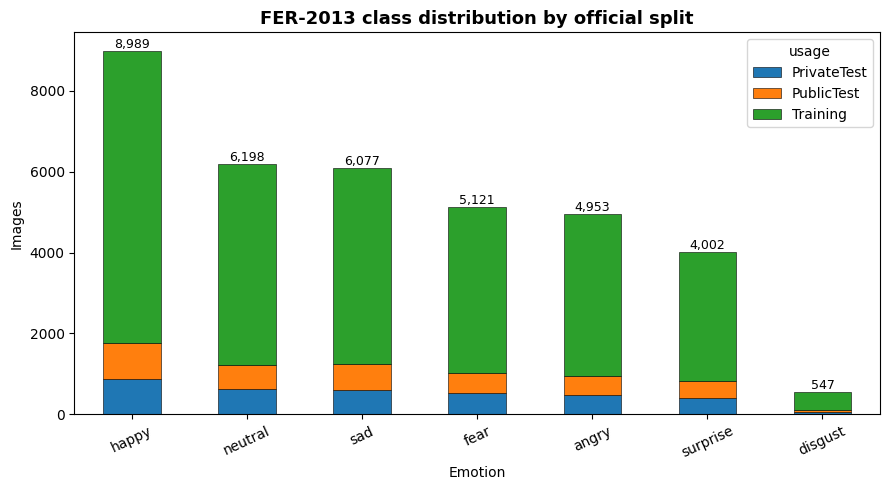

Imbalance ratio        : 16.4:1  (happy vs disgust)
Majority-class baseline: 0.2505   <- every model must beat this
Random-guess baseline  : 0.1429


In [8]:
# %%
ct = pd.crosstab(manifest["label"], manifest["usage"])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5))
ct.plot(kind="bar", stacked=True, ax=ax, edgecolor="black", linewidth=0.4)
ax.set_title("FER-2013 class distribution by official split", fontsize=13, weight="bold")
ax.set_xlabel("Emotion"); ax.set_ylabel("Images")
ax.tick_params(axis="x", rotation=25)
for i, t in enumerate(ct.sum(axis=1)):
    ax.text(i, t, f"{t:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(FIGDIR / "01_class_distribution.png", dpi=150); plt.show()

totals = ct.sum(axis=1)
imb = totals.max() / totals.min()
maj = totals.max() / totals.sum()
print(f"Imbalance ratio        : {imb:.1f}:1  ({totals.idxmax()} vs {totals.idxmin()})")
print(f"Majority-class baseline: {maj:.4f}   <- every model must beat this")
print(f"Random-guess baseline  : {1/len(totals):.4f}")

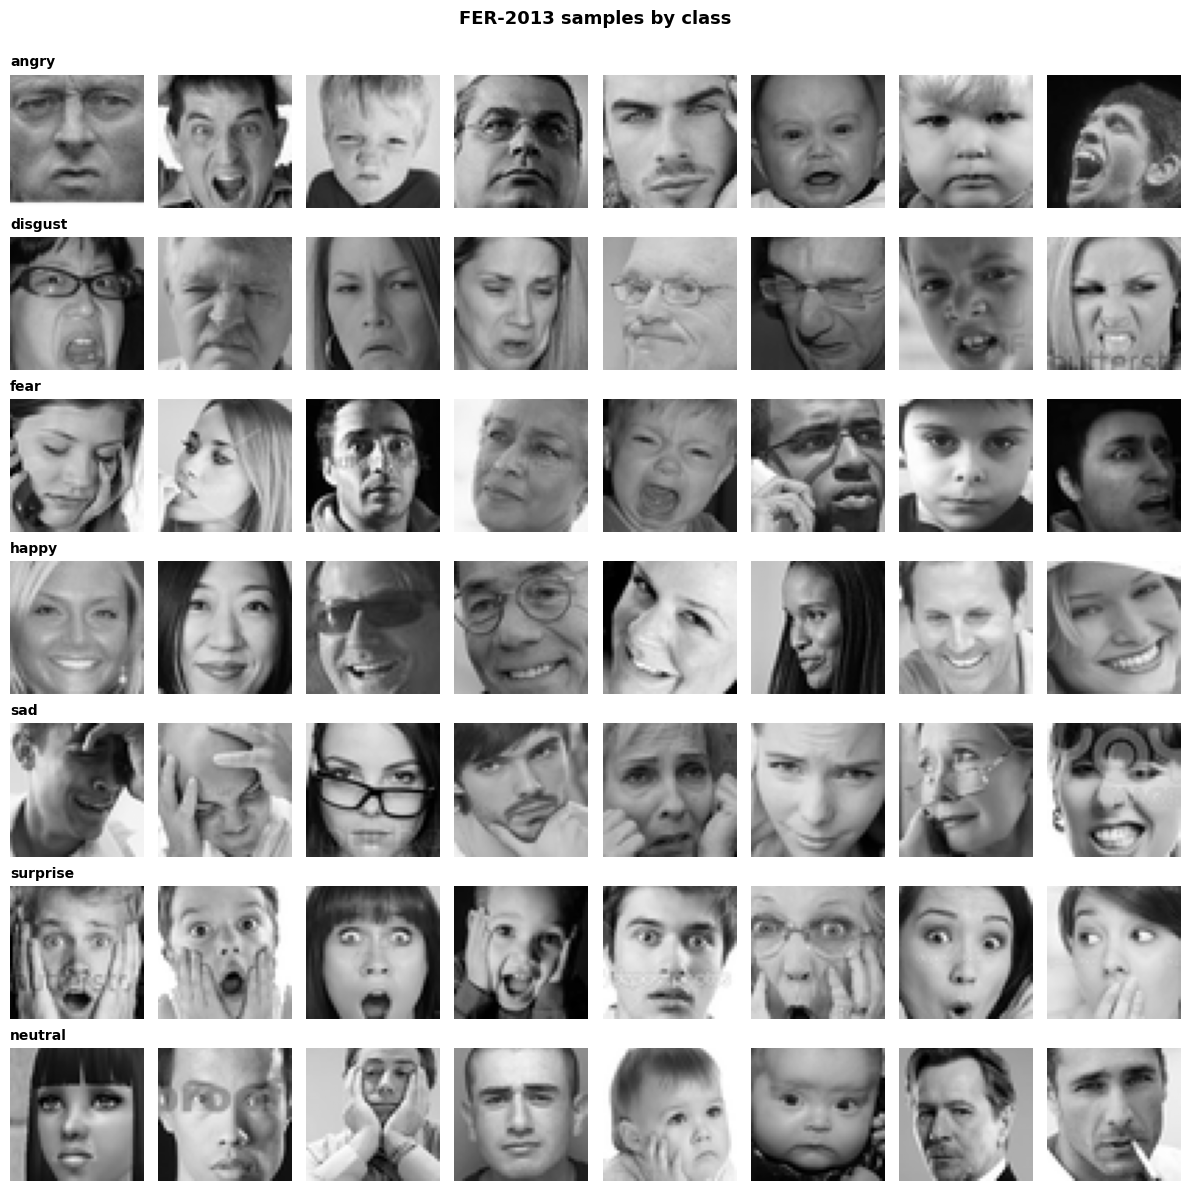

In [9]:
# %%
classes = [EMOTION_MAP[i] for i in sorted(EMOTION_MAP)]
n_show = 8
fig, axes = plt.subplots(len(classes), n_show, figsize=(n_show*1.5, len(classes)*1.7))
for r, cls in enumerate(classes):
    idx = manifest.index[manifest["label"] == cls]
    pick = np.random.choice(idx, size=min(n_show, len(idx)), replace=False)
    for c in range(n_show):
        ax = axes[r, c]; ax.axis("off")
        if c < len(pick):
            ax.imshow(X[pick[c]], cmap="gray", vmin=0, vmax=255)
        if c == 0:
            ax.set_title(cls, loc="left", fontsize=10, weight="bold")
fig.suptitle("FER-2013 samples by class", y=1.0, fontsize=13, weight="bold")
plt.tight_layout(); plt.savefig(FIGDIR / "02_sample_grid.png", dpi=150, bbox_inches="tight"); plt.show()

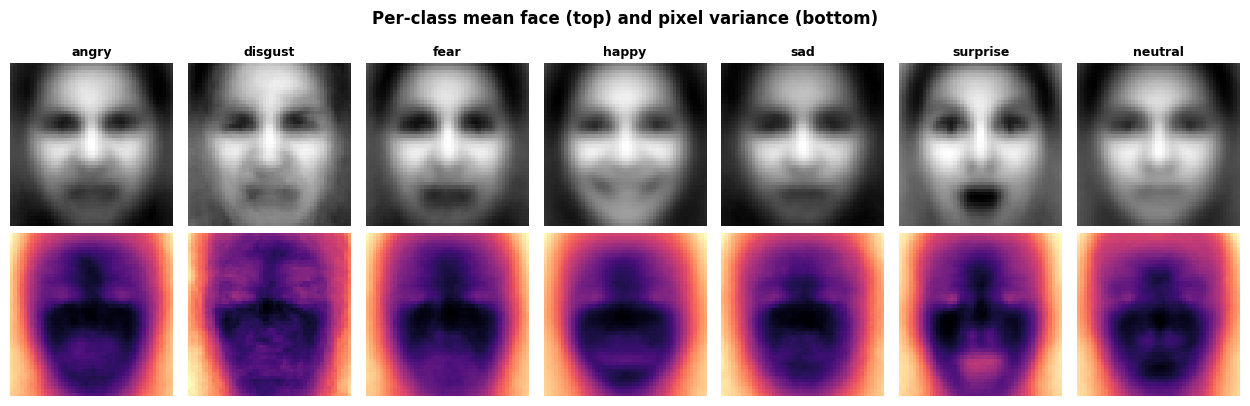

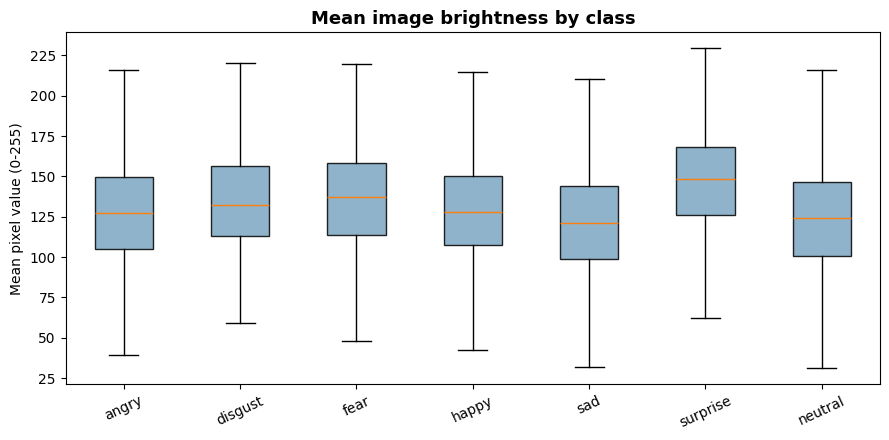

In [10]:
# %%
fig, axes = plt.subplots(2, len(classes), figsize=(len(classes)*1.8, 4.2))
for c, cls in enumerate(classes):
    sel = X[manifest["label"].values == cls]
    axes[0, c].imshow(sel.mean(axis=0), cmap="gray"); axes[0, c].axis("off")
    axes[0, c].set_title(cls, fontsize=9, weight="bold")
    axes[1, c].imshow(sel.std(axis=0), cmap="magma"); axes[1, c].axis("off")
fig.suptitle("Per-class mean face (top) and pixel variance (bottom)", fontsize=12, weight="bold")
plt.tight_layout(); plt.savefig(FIGDIR / "03_mean_faces.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
data = [X[manifest["label"].values == c].reshape(-1, 2304).mean(axis=1) for c in classes]
bp = ax.boxplot(data, labels=classes, patch_artist=True, showfliers=False)
for b in bp["boxes"]: b.set_facecolor("#7aa6c2"); b.set_alpha(0.85)
ax.set_title("Mean image brightness by class", fontsize=13, weight="bold")
ax.set_ylabel("Mean pixel value (0-255)"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(FIGDIR / "04_brightness_by_class.png", dpi=150); plt.show()

In [11]:
# %%
np.savez_compressed(OUT / "fer2013.npz", X=X, y=y,
                    usage=usage.astype(str), classes=np.array(classes))

summary = {
    "source": source_used,
    "csv_path": str(CSV),
    "n_images": int(len(X)),
    "image_shape": [48, 48],
    "n_classes": len(classes),
    "classes": classes,
    "split_counts": {k: int(v) for k, v in pd.Series(usage).value_counts().items()},
    "class_counts": {k: int(v) for k, v in totals.items()},
    "imbalance_ratio": round(float(imb), 2),
    "majority_baseline": round(float(maj), 4),
    "random_baseline": round(1/len(classes), 4),
    "integrity": report,
}
with open(OUT / "data_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print(f"\nCached: {OUT/'fer2013.npz'}  ({(OUT/'fer2013.npz').stat().st_size/1e6:.1f} MB)")

{
  "source": "kaggle dataset mirror: deadskull7/fer2013",
  "csv_path": "data/fer2013.csv",
  "n_images": 35887,
  "image_shape": [
    48,
    48
  ],
  "n_classes": 7,
  "classes": [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",
    "neutral"
  ],
  "split_counts": {
    "Training": 28709,
    "PublicTest": 3589,
    "PrivateTest": 3589
  },
  "class_counts": {
    "happy": 8989,
    "neutral": 6198,
    "sad": 6077,
    "fear": 5121,
    "angry": 4953,
    "surprise": 4002,
    "disgust": 547
  },
  "imbalance_ratio": 16.43,
  "majority_baseline": 0.2505,
  "random_baseline": 0.1429,
  "integrity": {
    "near_constant_images": 13,
    "duplicate_rows": 1853,
    "hashes_spanning_splits": 557,
    "hashes_with_conflicting_labels": 57
  }
}

Cached: artifacts/fer2013.npz  (78.3 MB)


Loaded: 35,887 images
start                                  remaining  35,887

A. blank/near-constant       -    13   remaining  35,874
B. contradictory labels      -   148   remaining  35,726
C. leaked train copies       -   649   remaining  35,077
D. PublicTest/PrivateTest overlap -    43   remaining  35,034
E. within-split duplicates   - 1,058   remaining  33,976

Post-clean verification (all should be 0):
  duplicate_hashes_remaining     0
  hashes_spanning_splits         0
  conflicting_labels             0
  near_constant                  0

           before  after  removed  pct_removed
angry       4953   4717      236         4.76
disgust      547    458       89        16.27
fear        5121   4802      319         6.23
happy       8989   8794      195         2.17
sad         6077   5912      165         2.72
surprise    4002   3248      754        18.84
neutral     6198   6045      153         2.47

Split sizes after cleaning:
Training       26911
PrivateTest     3557
Publi

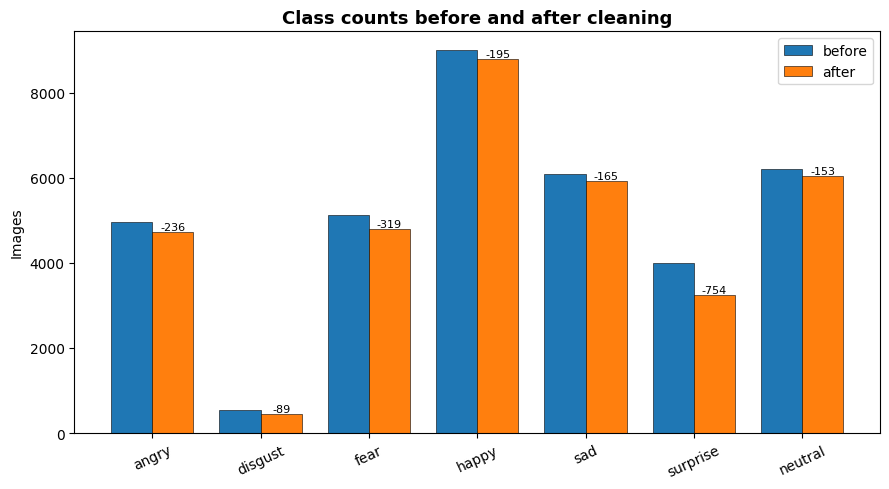


Saved: artifacts/fer2013_clean.npz
Removed 1,911 of 35,887 (5.33%)


In [12]:
# %% [markdown]
# # Step 1b — Cleaning
# Removes blanks, contradictory labels, cross-split leakage, and duplicates.
# Writes artifacts/fer2013_clean.npz and a cleaning ledger for the report.

# %%
import numpy as np, pandas as pd, hashlib, json
from pathlib import Path
import matplotlib.pyplot as plt

OUT    = Path("artifacts")
FIGDIR = Path("figures")

d = np.load(OUT / "fer2013.npz", allow_pickle=False)
X, y, usage, classes = d["X"], d["y"], d["usage"].astype(str), list(d["classes"])
print(f"Loaded: {X.shape[0]:,} images")

df = pd.DataFrame({
    "idx":   np.arange(len(y)),
    "label": y,
    "usage": usage,
    "hash":  [hashlib.md5(im.tobytes()).hexdigest() for im in X],
    "std":   X.reshape(len(X), -1).std(axis=1),
})

ledger = []
def log(step, removed, remaining, why):
    ledger.append({"step": step, "removed": int(removed),
                   "remaining": int(remaining), "rationale": why})
    print(f"{step:<28} -{removed:>6,}   remaining {remaining:>7,}")

keep = pd.Series(True, index=df.index)
print(f"{'start':<28} {'':>7}   remaining {len(df):>7,}\n")

# %%
# --- A. Blank / near-constant images -----------------------------------
mask = df["std"] < 1.0
keep &= ~mask
log("A. blank/near-constant", mask.sum(), keep.sum(),
    "no facial information; pure noise for the optimizer")

# --- B. Contradictory labels -------------------------------------------
# Identical pixels labelled differently. We cannot know which is correct,
# so every copy is discarded rather than guessing.
conflict_hashes = df.groupby("hash")["label"].nunique()
conflict_hashes = set(conflict_hashes[conflict_hashes > 1].index)
mask = df["hash"].isin(conflict_hashes) & keep
keep &= ~mask
log("B. contradictory labels", mask.sum(), keep.sum(),
    "same image, different label; ground truth unrecoverable")

# --- C. Cross-split leakage: train copies ------------------------------
# Drop from Training only. Test sets stay intact so results remain
# comparable to published FER-2013 benchmarks.
sub = df[keep]
test_hashes = set(sub.loc[sub["usage"] != "Training", "hash"])
mask = (df["usage"] == "Training") & df["hash"].isin(test_hashes) & keep
keep &= ~mask
log("C. leaked train copies", mask.sum(), keep.sum(),
    "image also present in a test split; would inflate test accuracy")

# --- D. Cross-split leakage: PublicTest vs PrivateTest -----------------
# PrivateTest is the canonical final benchmark, so it is preserved whole.
sub = df[keep]
priv = set(sub.loc[sub["usage"] == "PrivateTest", "hash"])
mask = (df["usage"] == "PublicTest") & df["hash"].isin(priv) & keep
keep &= ~mask
log("D. PublicTest/PrivateTest overlap", mask.sum(), keep.sum(),
    "validation and final test must not share images")

# --- E. Within-split duplicates ----------------------------------------
sub = df[keep]
dup_idx = sub[sub.duplicated(subset=["usage", "hash"], keep="first")]["idx"]
mask = df["idx"].isin(dup_idx) & keep
keep &= ~mask
log("E. within-split duplicates", mask.sum(), keep.sum(),
    "repeated images silently reweight the loss")

# %%
# --- Verify the cleaning actually worked -------------------------------
final = df[keep]
checks = {
    "duplicate_hashes_remaining": int(final.duplicated(subset=["hash"]).sum()),
    "hashes_spanning_splits":     int((final.groupby("hash")["usage"].nunique() > 1).sum()),
    "conflicting_labels":         int((final.groupby("hash")["label"].nunique() > 1).sum()),
    "near_constant":              int((final["std"] < 1.0).sum()),
}
print("\nPost-clean verification (all should be 0):")
for k, v in checks.items():
    print(f"  {k:<30} {v}")
assert all(v == 0 for v in checks.values()), "cleaning did not fully resolve issues"

# %%
# --- Save ---------------------------------------------------------------
sel = final["idx"].values
Xc, yc, uc = X[sel], y[sel], usage[sel]

np.savez_compressed(OUT / "fer2013_clean.npz",
                    X=Xc, y=yc, usage=uc.astype(str), classes=np.array(classes))

before = pd.Series(y).map(lambda i: classes[i]).value_counts()
after  = pd.Series(yc).map(lambda i: classes[i]).value_counts()
comp = pd.DataFrame({"before": before, "after": after}).fillna(0).astype(int)
comp["removed"] = comp["before"] - comp["after"]
comp["pct_removed"] = (comp["removed"] / comp["before"] * 100).round(2)
comp = comp.loc[[c for c in classes]]
print("\n", comp)

print("\nSplit sizes after cleaning:")
print(pd.Series(uc).value_counts())

# class weights for the imbalance, computed on cleaned training data only
tr = yc[uc == "Training"]
counts = np.bincount(tr, minlength=len(classes))
weights = len(tr) / (len(classes) * counts)
class_weight = {i: round(float(w), 4) for i, w in enumerate(weights)}
print("\nClass weights (Step 3):", class_weight)

pd.DataFrame(ledger).to_csv(OUT / "cleaning_ledger.csv", index=False)
comp.to_csv(OUT / "class_counts_before_after.csv")

clean_summary = {
    "n_before": int(len(X)),
    "n_after": int(len(Xc)),
    "n_removed": int(len(X) - len(Xc)),
    "pct_removed": round((len(X) - len(Xc)) / len(X) * 100, 2),
    "ledger": ledger,
    "verification": checks,
    "split_counts": {k: int(v) for k, v in pd.Series(uc).value_counts().items()},
    "class_counts": {k: int(v) for k, v in after.items()},
    "class_weight": class_weight,
}
with open(OUT / "cleaning_summary.json", "w") as f:
    json.dump(clean_summary, f, indent=2)

# %%
# --- FIGURE 5 — before/after by class ----------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
xpos = np.arange(len(comp)); w = 0.38
ax.bar(xpos - w/2, comp["before"], w, label="before", edgecolor="black", linewidth=0.4)
ax.bar(xpos + w/2, comp["after"],  w, label="after",  edgecolor="black", linewidth=0.4)
ax.set_xticks(xpos); ax.set_xticklabels(comp.index, rotation=25)
ax.set_ylabel("Images"); ax.legend()
ax.set_title("Class counts before and after cleaning", fontsize=13, weight="bold")
for i, (b, a) in enumerate(zip(comp["before"], comp["after"])):
    ax.text(i + w/2, a, f"-{b-a}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(FIGDIR / "05_clean_before_after.png", dpi=150); plt.show()

print(f"\nSaved: {OUT/'fer2013_clean.npz'}")
print(f"Removed {clean_summary['n_removed']:,} of {len(X):,} "
      f"({clean_summary['pct_removed']}%)")

Step 2 — diagnostic, splits, and tensors

Clean set: 33,976 images
split     Training  PublicTest  PrivateTest  total
class                                             
happy         7030         888          876   8794
neutral       4821         599          625   6045
sad           4677         646          589   5912
fear          3797         484          521   4802
angry         3776         457          484   4717
surprise      2460         381          407   3248
disgust        350          53           55    458

Classes with <100 images in a test split — per-class metrics
for these carry wide error bars. Report with that caveat:
split    PublicTest  PrivateTest
class                           
disgust          53           55
Distinct images appearing more than once: 1,516
Most-repeated single image appears 12 times

          dupe_instances  class_total  pct_of_class
label                                              
surprise            1333         4002          33.3
disgust              153          547          2

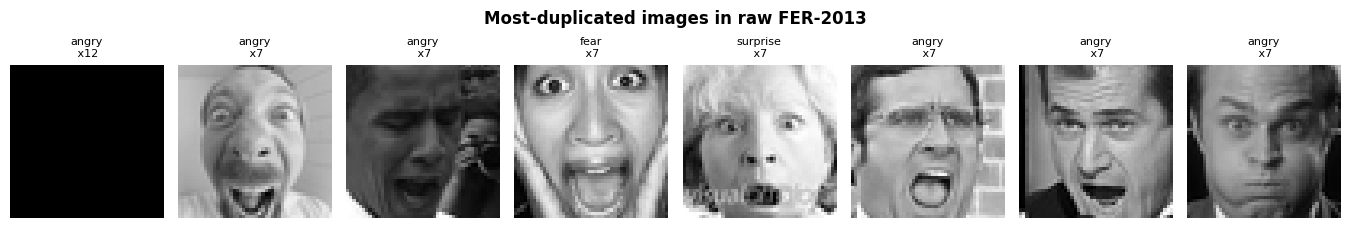

train  26,911
val     3,508
test    3,557
train mean 128.823   train std 64.942
X_train (26911, 48, 48, 1)  range [-1.98, 1.94]
Normalization verified on train.
val   mean -0.0009  std 0.9996   (should be near 0/1, not exact)
test  mean +0.0015  std 1.0069
class           n        none    balanced        sqrt   capped_4x
angry       3,776       1.000       1.018       1.009       1.018
disgust       350       1.000      10.984       3.314       4.000
fear        3,797       1.000       1.012       1.006       1.012
happy       7,030       1.000       0.547       0.740       0.547
sad         4,677       1.000       0.822       0.907       0.822
surprise    2,460       1.000       1.563       1.250       1.563
neutral     4,821       1.000       0.797       0.893       0.797

'balanced' pushes disgust past 10x — a known source of unstable
training. 'sqrt' and 'capped_4x' are gentler. Comparing these is a
clean axis for one of your three required model variations.
{
  "n_train": 26911,
 

In [13]:
# %% [markdown]
# # Step 2 — Preprocessing
# Diagnostic on the duplicate concentration, then train/val/test tensors.

# %%
import numpy as np, pandas as pd, hashlib, json
from pathlib import Path
import matplotlib.pyplot as plt

OUT    = Path("artifacts")
FIGDIR = Path("figures")

raw   = np.load(OUT / "fer2013.npz",       allow_pickle=False)
clean = np.load(OUT / "fer2013_clean.npz", allow_pickle=False)
classes = list(clean["classes"])

Xc, yc, uc = clean["X"], clean["y"], clean["usage"].astype(str)
print(f"Clean set: {Xc.shape[0]:,} images")

# %%
# ----------------------------------------------------------------------
# 1. Per-split per-class counts — how thin is disgust in test?
# ----------------------------------------------------------------------
tbl = pd.crosstab(pd.Series([classes[i] for i in yc], name="class"),
                  pd.Series(uc, name="split"))
tbl = tbl[["Training", "PublicTest", "PrivateTest"]]
tbl["total"] = tbl.sum(axis=1)
print(tbl.sort_values("total", ascending=False))

thin = tbl[tbl[["PublicTest", "PrivateTest"]].min(axis=1) < 100]
if len(thin):
    print("\nClasses with <100 images in a test split — per-class metrics")
    print("for these carry wide error bars. Report with that caveat:")
    print(thin[["PublicTest", "PrivateTest"]])

# %%
# ----------------------------------------------------------------------
# 2. DIAGNOSTIC — where was the duplication concentrated?
# ----------------------------------------------------------------------
Xr, yr = raw["X"], raw["y"]
hr = np.array([hashlib.md5(im.tobytes()).hexdigest() for im in Xr])
rep = pd.DataFrame({"hash": hr, "label": [classes[i] for i in yr]})

counts = rep["hash"].value_counts()
multi  = counts[counts > 1]
print(f"Distinct images appearing more than once: {len(multi):,}")
print(f"Most-repeated single image appears {counts.max()} times\n")

# which class did the repeats live in?
dupe_rows = rep[rep["hash"].isin(multi.index)]
by_class = pd.DataFrame({
    "dupe_instances": dupe_rows["label"].value_counts(),
    "class_total":    rep["label"].value_counts(),
})
by_class["pct_of_class"] = (by_class["dupe_instances"] /
                            by_class["class_total"] * 100).round(1)
print(by_class.sort_values("pct_of_class", ascending=False))

# show the worst offenders
top = counts.head(8).index
fig, axes = plt.subplots(1, len(top), figsize=(len(top)*1.7, 2.4))
for ax, h in zip(axes, top):
    i = int(np.where(hr == h)[0][0])
    ax.imshow(Xr[i], cmap="gray", vmin=0, vmax=255); ax.axis("off")
    ax.set_title(f"{classes[yr[i]]}\n x{counts[h]}", fontsize=8)
fig.suptitle("Most-duplicated images in raw FER-2013", fontsize=12, weight="bold")
plt.tight_layout(); plt.savefig(FIGDIR / "06_top_duplicates.png", dpi=150,
                                bbox_inches="tight"); plt.show()

# %%
# ----------------------------------------------------------------------
# 3. Splits — official Usage column drives this
# ----------------------------------------------------------------------
tr_m = uc == "Training"
va_m = uc == "PublicTest"
te_m = uc == "PrivateTest"

X_train, y_train = Xc[tr_m], yc[tr_m]
X_val,   y_val   = Xc[va_m], yc[va_m]
X_test,  y_test  = Xc[te_m], yc[te_m]

for name, a in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:<6} {len(a):>6,}")

# %%
# ----------------------------------------------------------------------
# 4. Normalization — statistics from TRAIN ONLY
#    Using val/test pixels to compute the mean would be leakage.
# ----------------------------------------------------------------------
mean = float(X_train.mean())
std  = float(X_train.std())
print(f"train mean {mean:.3f}   train std {std:.3f}")

def prep(X):
    X = X.astype("float32")
    X = (X - mean) / std
    return X[..., np.newaxis]          # (N, 48, 48, 1) for Conv2D

X_train_p = prep(X_train)
X_val_p   = prep(X_val)
X_test_p  = prep(X_test)

print(f"X_train {X_train_p.shape}  range [{X_train_p.min():.2f}, {X_train_p.max():.2f}]")
assert abs(X_train_p.mean()) < 1e-4 and abs(X_train_p.std() - 1) < 1e-3, \
       "train set should be zero-mean unit-variance"
print("Normalization verified on train.")
print(f"val   mean {X_val_p.mean():+.4f}  std {X_val_p.std():.4f}   (should be near 0/1, not exact)")
print(f"test  mean {X_test_p.mean():+.4f}  std {X_test_p.std():.4f}")

# %%
# ----------------------------------------------------------------------
# 5. Three class-weighting schemes to compare in Step 3
# ----------------------------------------------------------------------
cnt = np.bincount(y_train, minlength=len(classes))
n, k = len(y_train), len(classes)

schemes = {
    "none":      {i: 1.0 for i in range(k)},
    "balanced":  {i: float(n / (k * c)) for i, c in enumerate(cnt)},
    "sqrt":      {i: float(np.sqrt(n / (k * c))) for i, c in enumerate(cnt)},
    "capped_4x": {i: float(min(n / (k * c), 4.0)) for i, c in enumerate(cnt)},
}

print(f"{'class':<10}{'n':>7}", end="")
for s in schemes: print(f"{s:>12}", end="")
print()
for i, c in enumerate(classes):
    print(f"{c:<10}{cnt[i]:>7,}", end="")
    for s in schemes:
        print(f"{schemes[s][i]:>12.3f}", end="")
    print()

print("\n'balanced' pushes disgust past 10x — a known source of unstable")
print("training. 'sqrt' and 'capped_4x' are gentler. Comparing these is a")
print("clean axis for one of your three required model variations.")

# %%
# ----------------------------------------------------------------------
# 6. Save tensors
# ----------------------------------------------------------------------
np.savez_compressed(
    OUT / "fer2013_tensors.npz",
    X_train=X_train_p, y_train=y_train,
    X_val=X_val_p,     y_val=y_val,
    X_test=X_test_p,   y_test=y_test,
    classes=np.array(classes),
    norm_mean=np.array([mean]), norm_std=np.array([std]),
)

prep_summary = {
    "n_train": int(len(y_train)),
    "n_val":   int(len(y_val)),
    "n_test":  int(len(y_test)),
    "input_shape": [48, 48, 1],
    "n_classes": k,
    "classes": classes,
    "norm_mean": round(mean, 4),
    "norm_std":  round(std, 4),
    "norm_fitted_on": "training split only",
    "train_class_counts": {classes[i]: int(c) for i, c in enumerate(cnt)},
    "imbalance_ratio": round(float(cnt.max() / cnt.min()), 2),
    "class_weight_schemes": schemes,
}
with open(OUT / "preprocessing_summary.json", "w") as f:
    json.dump(prep_summary, f, indent=2)

print(json.dumps(prep_summary, indent=2))
print(f"\nSaved: {OUT/'fer2013_tensors.npz'} "
      f"({(OUT/'fer2013_tensors.npz').stat().st_size/1e6:.1f} MB)")

In [2]:
# %%
import time, numpy as np, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

t = np.load("artifacts/fer2013_tensors.npz")
Xs, ys = t["X_train"][:2048], t["y_train"][:2048]

m = keras.Sequential([
    layers.Input((48,48,1)),
    layers.Conv2D(32,3,padding="same",activation="relu"),
    layers.Conv2D(32,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,padding="same",activation="relu"),
    layers.Conv2D(64,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(128,activation="relu"),
    layers.Dropout(0.5), layers.Dense(7,activation="softmax"),
])
m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time(); m.fit(Xs, ys, epochs=1, batch_size=64, verbose=1); dt = time.time()-t0
print(f"\n2,048 imgs: {dt:.1f}s  ->  full epoch ~{dt*13.1/60:.1f} min")

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.2314 - loss: 1.8423

2,048 imgs: 3.2s  ->  full epoch ~0.7 min


In [1]:
# %%
import platform, time, numpy as np
print("machine:", platform.machine())        # want 'arm64', NOT 'x86_64'
print("python :", platform.python_version())

import tensorflow as tf
a = tf.random.normal((2000, 2000)); b = tf.random.normal((2000, 2000))
tf.matmul(a, b)                               # warm up
t0 = time.time(); [tf.matmul(a, b) for _ in range(10)]; dt = time.time() - t0
print(f"10x 2000^2 matmul: {dt:.2f}s   ({8e10/dt/1e9:.1f} GFLOPS)")

machine: arm64
python : 3.12.2
10x 2000^2 matmul: 0.27s   (299.1 GFLOPS)


In [1]:
# %%
import faulthandler, sys, numpy as np, time, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
faulthandler.dump_traceback_later(90, exit=False)   # dumps a stack trace if it hangs

t = np.load("artifacts/fer2013_tensors.npz")
X = np.ascontiguousarray(t["X_train"]); y = np.ascontiguousarray(t["y_train"])
Xv = np.ascontiguousarray(t["X_val"]);  yv = np.ascontiguousarray(t["y_val"])

print("A: plain fit, no validation", flush=True)
m = build_baseline_local = keras.Sequential([
    layers.Input((48,48,1)),
    layers.Conv2D(32,3,padding="same",activation="relu"),
    layers.Conv2D(32,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,padding="same",activation="relu"),
    layers.Conv2D(64,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(128,activation="relu"),
    layers.Dropout(0.5), layers.Dense(7,activation="softmax")])
m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0=time.time(); m.fit(X, y, epochs=1, batch_size=64, verbose=1); print(f"A ok {time.time()-t0:.0f}s", flush=True)

print("\nB: same + validation_data", flush=True)
t0=time.time(); m.fit(X, y, validation_data=(Xv,yv), epochs=1, batch_size=64, verbose=1); print(f"B ok {time.time()-t0:.0f}s", flush=True)

A: plain fit, no validation
421/421 ━━━━━━━━━━━━━━━━━━━━ 32s 75ms/step - accuracy: 0.3583 - loss: 1.6222
A ok 32s

B: same + validation_data
421/421 ━━━━━━━━━━━━━━━━━━━━ 33s 79ms/step - accuracy: 0.4765 - loss: 1.3686 - val_accuracy: 0.5200 - val_loss: 1.2645
B ok 33s


In [1]:
# %%
import numpy as np, time, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

t = np.load("artifacts/fer2013_tensors.npz")
X, y = t["X_train"], t["y_train"]
X = np.ascontiguousarray(X); y = np.ascontiguousarray(y)
print("loaded", X.shape, X.dtype, flush=True)

class Ticker(keras.callbacks.Callback):
    def on_train_batch_end(self, b, logs=None):
        if b % 25 == 0:
            print(f"  batch {b} loss={logs['loss']:.3f} t={time.time()-self.t0:.1f}s", flush=True)
    def on_train_begin(self, logs=None): self.t0 = time.time()

m = keras.Sequential([
    layers.Input((48,48,1)),
    layers.Conv2D(32,3,padding="same",activation="relu"),
    layers.Conv2D(32,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3,padding="same",activation="relu"),
    layers.Conv2D(64,3,padding="same",activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(128,activation="relu"),
    layers.Dropout(0.5), layers.Dense(7,activation="softmax"),
])
m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
m.fit(X, y, epochs=1, batch_size=64, verbose=0, callbacks=[Ticker()])

loaded (26911, 48, 48, 1) float32
  batch 0 loss=1.959 t=0.6s
  batch 25 loss=1.823 t=2.8s
  batch 50 loss=1.803 t=5.1s
  batch 75 loss=1.793 t=7.3s
  batch 100 loss=1.777 t=9.4s
  batch 125 loss=1.764 t=12.3s
  batch 150 loss=1.750 t=14.3s
  batch 175 loss=1.734 t=16.2s
  batch 200 loss=1.720 t=18.2s
  batch 225 loss=1.708 t=20.1s
  batch 250 loss=1.694 t=22.0s
  batch 275 loss=1.682 t=24.1s
  batch 300 loss=1.671 t=26.0s
  batch 325 loss=1.658 t=28.2s
  batch 350 loss=1.646 t=30.3s
  batch 375 loss=1.638 t=32.3s
  batch 400 loss=1.627 t=34.2s


SyntaxError: invalid syntax (4081999873.py, line 1)

In [ ]:
# %% [markdown]
# # Step 3 — FULL RUN (no Keras callbacks)
# Restart the kernel before running.

# %%
import numpy as np, pandas as pd, json, time, random
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score, accuracy_score

OUT    = Path("artifacts")
MODELS = OUT / "models";  MODELS.mkdir(parents=True, exist_ok=True)
HIST   = OUT / "history"; HIST.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

EPOCHS, BATCH   = 45, 64
PATIENCE_STOP   = 10      # epochs without val_loss improvement -> stop
PATIENCE_LR     = 4       # epochs without improvement -> halve LR
MIN_LR          = 1e-6

t = np.load(OUT / "fer2013_tensors.npz", allow_pickle=False)
X_train = np.ascontiguousarray(t["X_train"]); y_train = np.ascontiguousarray(t["y_train"])
X_val   = np.ascontiguousarray(t["X_val"]);   y_val   = np.ascontiguousarray(t["y_val"])
X_test  = np.ascontiguousarray(t["X_test"]);  y_test  = np.ascontiguousarray(t["y_test"])
classes = [str(c) for c in t["classes"]]
N_CLASSES, INPUT_SHAPE = len(classes), X_train.shape[1:]

CLASS_WEIGHTS = {
    "none": {i: 1.0 for i in range(7)},
    "sqrt": {0:1.0090, 1:3.3142, 2:1.0062, 3:0.7395, 4:0.9066, 5:1.2501, 6:0.8930},
}
MAJORITY = float(pd.Series(y_test).value_counts().max() / len(y_test))
print(f"train {X_train.shape}   majority floor {MAJORITY:.4f}", flush=True)

# %%
def augmentation_block():
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.05, seed=SEED),
        layers.RandomZoom(0.10, seed=SEED),
        layers.RandomTranslation(0.08, 0.08, seed=SEED),
    ], name="augment")

def build_baseline(name="A_baseline"):
    return keras.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(N_CLASSES, activation="softmax"),
    ], name=name)

def build_regularized(name="B_regularized"):
    return keras.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        augmentation_block(),
        layers.Conv2D(32, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(32, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Conv2D(64, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(64, 3, padding="same", use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(128, use_bias=False),
        layers.BatchNormalization(), layers.Activation("relu"),
        layers.Dropout(0.5),
        layers.Dense(N_CLASSES, activation="softmax"),
    ], name=name)

def build_deep(name="C_deep"):
    def block(x, f, drop):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        return layers.Dropout(drop)(x)
    inp = layers.Input(shape=INPUT_SHAPE)
    x = augmentation_block()(inp)
    x = block(x,  32, 0.25)
    x = block(x,  64, 0.30)
    x = block(x, 128, 0.35)
    x = block(x, 256, 0.40)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(N_CLASSES, activation="softmax")(x), name=name)

# %%
def train(builder, tag, class_weight=None, lr=1e-3):
    path = MODELS / f"{tag}.keras"
    if path.exists():
        print(f"\n{tag}: already trained, loading", flush=True)
        return keras.models.load_model(path), json.load(open(HIST / f"{tag}.json"))

    keras.backend.clear_session()
    tf.random.set_seed(SEED); np.random.seed(SEED)
    model = builder(name=tag)
    print(f"\n{'='*70}\n{tag}   params={model.count_params():,}   "
          f"weights={'sqrt' if class_weight else 'none'}\n{'='*70}", flush=True)

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    hist = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": [], "lr": []}
    best_loss, best_weights, bad_stop, bad_lr = np.inf, None, 0, 0
    cur_lr = lr

    for ep in range(EPOCHS):
        print(f"  [epoch {ep+1}/{EPOCHS}] training...", flush=True)
        h = model.fit(X_train, y_train, epochs=1, batch_size=BATCH,
                      class_weight=class_weight, shuffle=True, verbose=1)
        vl, va = model.evaluate(X_val, y_val, batch_size=256, verbose=0)

        hist["loss"].append(float(h.history["loss"][0]))
        hist["accuracy"].append(float(h.history["accuracy"][0]))
        hist["val_loss"].append(float(vl)); hist["val_accuracy"].append(float(va))
        hist["lr"].append(float(cur_lr))

        if vl < best_loss - 1e-4:
            best_loss, best_weights = vl, model.get_weights()
            bad_stop = bad_lr = 0
            flag = " *best*"
        else:
            bad_stop += 1; bad_lr += 1; flag = ""
        print(f"  ep {ep+1:>2}  val_loss {vl:.4f}  val_acc {va:.4f}{flag}", flush=True)

        if bad_lr >= PATIENCE_LR and cur_lr > MIN_LR:
            cur_lr = max(cur_lr * 0.5, MIN_LR)
            model.optimizer.learning_rate.assign(cur_lr)
            bad_lr = 0
            print(f"     lr -> {cur_lr:.2e}", flush=True)

        if bad_stop >= PATIENCE_STOP:
            print(f"     early stop at epoch {ep+1}", flush=True)
            break

    if best_weights is not None:
        model.set_weights(best_weights)
        print(f"  restored best weights (val_loss {best_loss:.4f})", flush=True)

    model.save(path)
    json.dump(hist, open(HIST / f"{tag}.json", "w"))
    return model, hist

def evaluate(model, tag, hist):
    p_val  = model.predict(X_val,  batch_size=256, verbose=0).argmax(1)
    p_test = model.predict(X_test, batch_size=256, verbose=0).argmax(1)
    res = {
        "tag": tag, "params": int(model.count_params()),
        "epochs_run": len(hist["loss"]),
        "val_accuracy":  round(float(accuracy_score(y_val,  p_val)),  4),
        "val_macro_f1":  round(float(f1_score(y_val,  p_val,  average="macro")), 4),
        "test_accuracy": round(float(accuracy_score(y_test, p_test)), 4),
        "test_macro_f1": round(float(f1_score(y_test, p_test, average="macro")), 4),
        "test_weighted_f1": round(float(f1_score(y_test, p_test, average="weighted")), 4),
    }
    pc = f1_score(y_test, p_test, average=None, labels=range(N_CLASSES))
    res["test_f1_per_class"] = {c: round(float(v), 4) for c, v in zip(classes, pc)}
    np.save(OUT / f"preds_{tag}.npy", p_test)
    print(f"  -> test acc {res['test_accuracy']:.4f}  macro-F1 {res['test_macro_f1']:.4f}"
          f"  disgust-F1 {res['test_f1_per_class']['disgust']:.4f}", flush=True)
    return res, p_test

# %%
t0 = time.time()
results, histories, preds = [], {}, {}
for tag, builder, cw in [
    ("A_baseline",    build_baseline,    None),
    ("B_regularized", build_regularized, None),
    ("C_deep",        build_deep,        None),
    ("D_deep_sqrtw",  build_deep,        CLASS_WEIGHTS["sqrt"]),
]:
    model, hist = train(builder, tag, class_weight=cw)
    res, p = evaluate(model, tag, hist)
    results.append(res); histories[tag] = hist; preds[tag] = p

comp = pd.DataFrame(results).set_index("tag")
comp.to_csv(OUT / "model_comparison.csv")
json.dump({"majority_floor": MAJORITY,
           "best_by_macro_f1": comp["test_macro_f1"].idxmax(),
           "results": results}, open(OUT / "model_results.json", "w"), indent=2)

print(f"\n{'='*70}\nTotal: {(time.time()-t0)/60:.1f} min\n{'='*70}")
print(comp[["params","epochs_run","test_accuracy","test_macro_f1","test_weighted_f1"]])
print(f"\nmajority floor: {MAJORITY:.4f}   best: {comp['test_macro_f1'].idxmax()}")

train (26911, 48, 48, 1)   majority floor 0.2463

A_baseline   params=1,245,671   weights=none
  [epoch 1/45] training...


In [1]:
# %%
import sys, platform, torch
print(sys.executable)                          # should contain /envs/dl/
print(platform.machine())                      # arm64
print("mps:", torch.backends.mps.is_available())

ModuleNotFoundError: No module named 'torch'

In [1]:
# %%
import os
os.environ["KERAS_BACKEND"] = "torch"
import keras, torch
print("backend:", keras.backend.backend())
print("mps available:", torch.backends.mps.is_available())

Matplotlib is building the font cache; this may take a moment.


backend: torch
mps available: True


loaded: 3557 test images


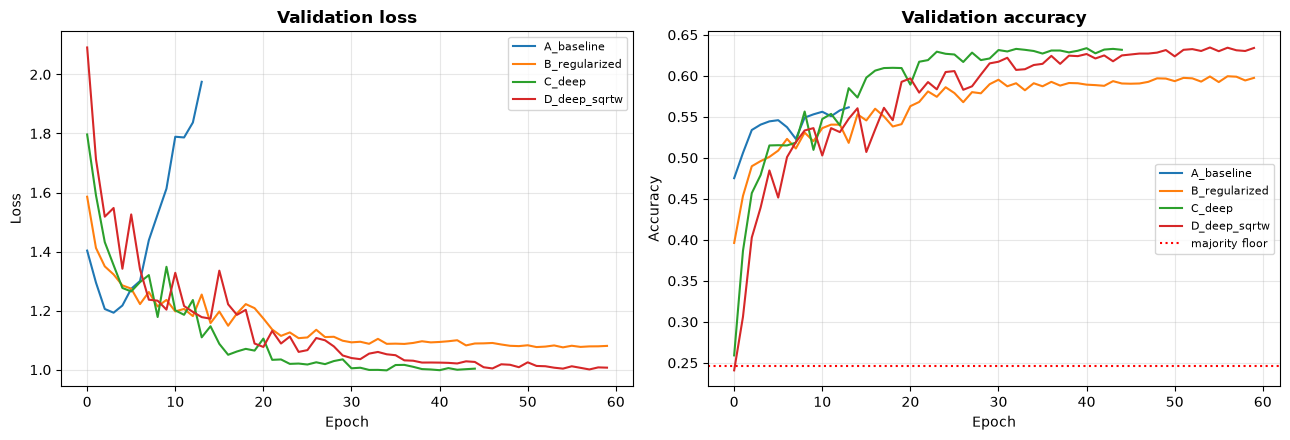

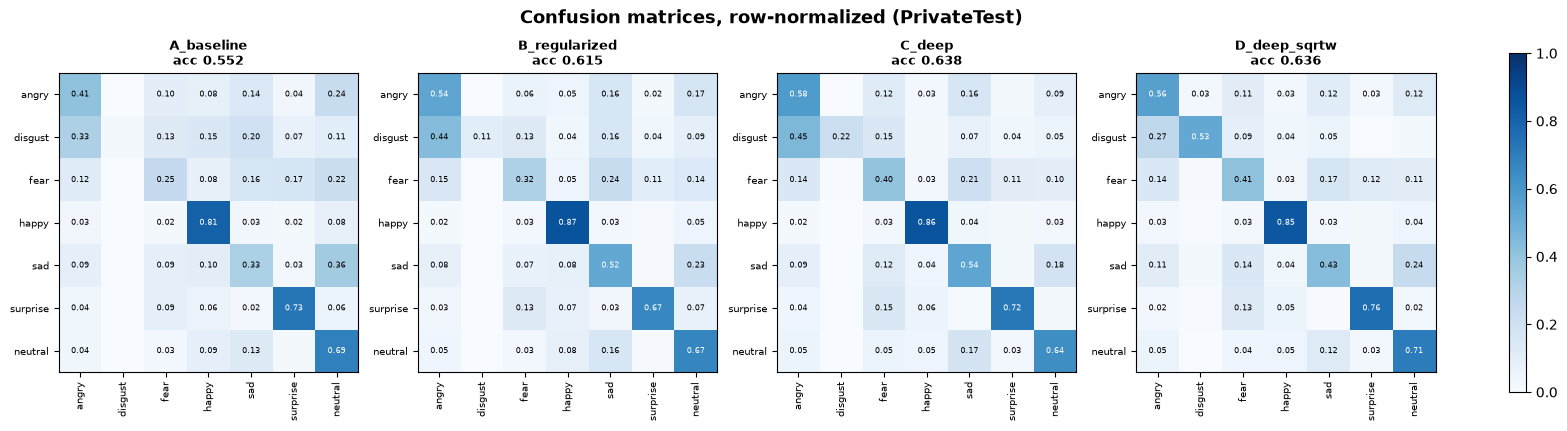

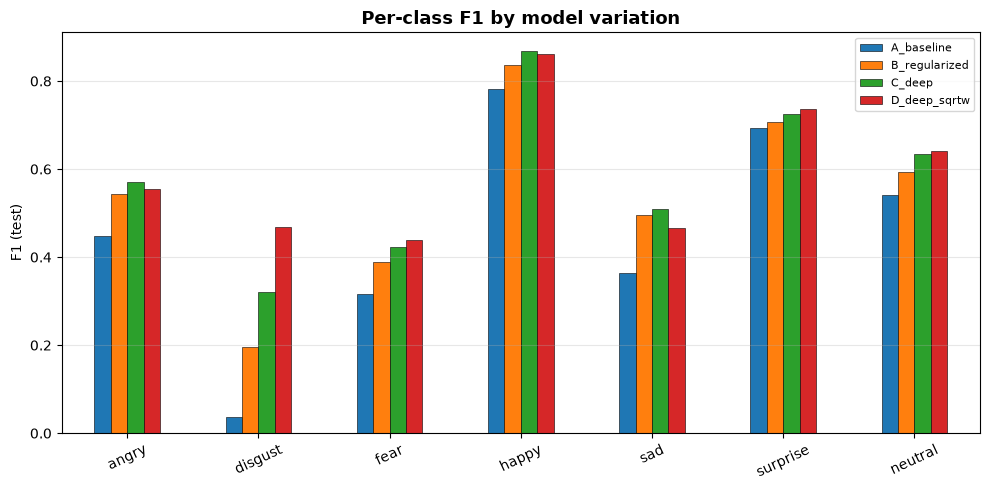

['01_class_distribution.png', '02_sample_grid.png', '03_mean_faces.png', '04_brightness_by_class.png', '05_clean_before_after.png', '06_top_duplicates.png', '07_training_curves.png', '08_confusion_matrices.png', '09_per_class_f1.png', '10_model_comparison.png', '11_disgust_progression.png', '12_misclassifications.png']


In [1]:
# %%
import numpy as np, pandas as pd, json
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

OUT, FIGDIR = Path("artifacts"), Path("figures")

t = np.load(OUT/"fer2013_tensors.npz", allow_pickle=False)
y_test  = t["y_test"]
classes = [str(c) for c in t["classes"]]
MAJORITY = float(pd.Series(y_test).value_counts().max()/len(y_test))

tags  = ["A_baseline","B_regularized","C_deep","D_deep_sqrtw"]
preds = {tg: np.load(OUT/f"preds_{tg}.npy") for tg in tags}
hists = json.load(open(OUT/"all_histories.json"))
res   = json.load(open(OUT/"model_results.json"))["results"]
comp  = pd.DataFrame(res).set_index("tag")
print("loaded:", len(y_test), "test images")

# %%
# --- FIG 07: training curves ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for tg in tags:
    h = hists[tg]
    ax[0].plot(h["val_loss"], label=tg)
    ax[1].plot(h["val_accuracy"], label=tg)
ax[0].set_title("Validation loss", weight="bold"); ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].axhline(MAJORITY, color="red", ls=":", lw=1.5, label="majority floor")
ax[1].set_title("Validation accuracy", weight="bold"); ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIGDIR/"07_training_curves.png", dpi=150); plt.show()

# %%
# --- FIG 08: confusion matrices ---
fig, axes = plt.subplots(1, 4, figsize=(19, 4.4))
for a, tg in zip(axes, tags):
    cm = confusion_matrix(y_test, preds[tg], labels=range(7), normalize="true")
    im = a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(range(7)); a.set_xticklabels(classes, rotation=90, fontsize=7)
    a.set_yticks(range(7)); a.set_yticklabels(classes, fontsize=7)
    a.set_title(f"{tg}\nacc {comp.loc[tg,'test_accuracy']:.3f}", fontsize=9, weight="bold")
    for i in range(7):
        for j in range(7):
            if cm[i,j] > 0.02:
                a.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
                       fontsize=6, color="white" if cm[i,j] > .5 else "black")
fig.colorbar(im, ax=axes, fraction=0.015)
fig.suptitle("Confusion matrices, row-normalized (PrivateTest)", fontsize=13, weight="bold")
plt.savefig(FIGDIR/"08_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

# %%
# --- FIG 09: per-class F1 ---
f1df = pd.DataFrame({r["tag"]: r["test_f1_per_class"] for r in res}).loc[classes]
ax = f1df.plot(kind="bar", figsize=(10,5), edgecolor="black", linewidth=0.4)
ax.set_ylabel("F1 (test)"); ax.set_xlabel("")
ax.set_title("Per-class F1 by model variation", fontsize=13, weight="bold")
ax.tick_params(axis="x", rotation=25); ax.legend(fontsize=8); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(FIGDIR/"09_per_class_f1.png", dpi=150); plt.show()

print(sorted(p.name for p in FIGDIR.glob("*.png")))

In [4]:
# %% [markdown]
# # Step 4 — Transfer learning
# Streams 48x48 uint8 -> resized RGB via tf.data. Two-phase: head, then fine-tune.

# %%
import numpy as np, pandas as pd, json, time
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, classification_report

OUT    = Path("artifacts"); MODELS = OUT/"models"; MODELS.mkdir(parents=True, exist_ok=True)
HIST   = OUT/"history"; HIST.mkdir(parents=True, exist_ok=True)
FIGDIR = Path("figures"); FIGDIR.mkdir(exist_ok=True)

SEED = 42
tf.keras.utils.set_random_seed(SEED)

# ---- config -----------------------------------------------------------
IMG_SIZE  = 128
BACKBONE  = "resnet"
BATCH     = 64
EPOCHS_HEAD, EPOCHS_FT = 40, 120
LR_HEAD, LR_FT = 1e-3, 3e-5
UNFREEZE_FRAC = 0.50

print(f"{BACKBONE} @ {IMG_SIZE}px  |  GPU: {tf.config.list_physical_devices('GPU')}")

# %%
# ---- load the CLEAN uint8 source (not the normalized tensors) ----------
d = np.load(OUT/"fer2013_clean.npz", allow_pickle=False)
X, y, usage = d["X"], d["y"], d["usage"].astype(str)
classes = [str(c) for c in d["classes"]]
N_CLASSES = len(classes)

tr, va, te = usage=="Training", usage=="PublicTest", usage=="PrivateTest"
X_tr, y_tr = X[tr], y[tr]
X_va, y_va = X[va], y[va]
X_te, y_te = X[te], y[te]
print(f"train {len(y_tr):,}  val {len(y_va):,}  test {len(y_te):,}")

CLASS_WEIGHT = {0:1.0090, 1:3.3142, 2:1.0062, 3:0.7395,
                4:0.9066, 5:1.2501, 6:0.8930}   # sqrt scheme, carried over
MAJORITY = float(pd.Series(y_te).value_counts().max()/len(y_te))

# %%
# ---- preprocessing fn per backbone ------------------------------------
BACKBONES = {
    "efficientnet": (keras.applications.EfficientNetB0,
                     keras.applications.efficientnet.preprocess_input),
    "mobilenet":    (keras.applications.MobileNetV2,
                     keras.applications.mobilenet_v2.preprocess_input),
    "resnet":       (keras.applications.ResNet50,
                     keras.applications.resnet50.preprocess_input),
}
BaseModel, preprocess = BACKBONES[BACKBONE]

def make_ds(Xa, ya, training):
    """uint8 48x48 -> float RGB IMG_SIZE. Resize happens on GPU, per batch."""
    ds = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if training:
        ds = ds.shuffle(len(ya), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)

    def prep(img, lab):
        img = tf.cast(img, tf.float32)[..., tf.newaxis]     # (B,48,48,1)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method="bilinear")
        img = tf.image.grayscale_to_rgb(img)                 # (B,S,S,3)
        return preprocess(img), lab

    ds = ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

ds_tr = make_ds(X_tr, y_tr, True)
ds_va = make_ds(X_va, y_va, False)
ds_te = make_ds(X_te, y_te, False)

b, l = next(iter(ds_tr))
print("batch:", b.shape, b.dtype, "range", float(tf.reduce_min(b)), float(tf.reduce_max(b)))

# %%
# ---- model ------------------------------------------------------------
def build(name="T_transfer"):
    aug = keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.05, seed=SEED),
        layers.RandomZoom(0.10, seed=SEED),
        layers.RandomTranslation(0.08, 0.08, seed=SEED),
    ], name="augment")

    base = BaseModel(include_top=False, weights="imagenet",
                     input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = aug(inp)
    x = base(x, training=False)              # keeps BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name=name), base

model, base = build()
print(f"backbone layers: {len(base.layers)}  |  trainable params now: "
      f"{sum(np.prod(w.shape) for w in model.trainable_weights):,}")

# %%
# ---- PHASE 1: train the head only -------------------------------------
model.compile(optimizer=keras.optimizers.Adam(LR_HEAD),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_HEAD,
               class_weight=CLASS_WEIGHT, verbose=1,
               callbacks=[keras.callbacks.EarlyStopping(
                   monitor="val_loss", patience=5,
                   restore_best_weights=True, verbose=1)])
print(f"phase 1: {(time.time()-t0)/60:.1f} min")

# %%
# ---- PHASE 2: unfreeze the top of the backbone ------------------------
base.trainable = True
cut = int(len(base.layers) * (1 - UNFREEZE_FRAC))
for l_ in base.layers[:cut]:
    l_.trainable = False
# BatchNorm stays frozen — unfreezing it on a small dataset destabilizes training
for l_ in base.layers:
    if isinstance(l_, layers.BatchNormalization):
        l_.trainable = False

print(f"unfrozen from layer {cut}/{len(base.layers)}  |  trainable params: "
      f"{sum(np.prod(w.shape) for w in model.trainable_weights):,}")

model.compile(optimizer=keras.optimizers.Adam(LR_FT),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_FT,
               class_weight=CLASS_WEIGHT, verbose=1,
               callbacks=[
                   keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                                 restore_best_weights=True, verbose=1),
                   keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                                     patience=4, min_lr=1e-8, verbose=1)])
print(f"phase 2: {(time.time()-t0)/60:.1f} min")

# %%
# ---- evaluate ---------------------------------------------------------
tag = f"T_{BACKBONE}_{IMG_SIZE}"
p_te = model.predict(ds_te, verbose=0).argmax(1)

res = {
    "tag": tag, "backbone": BACKBONE, "img_size": IMG_SIZE,
    "params": int(model.count_params()),
    "epochs_head": len(h1.history["loss"]), "epochs_ft": len(h2.history["loss"]),
    "test_accuracy": round(float(accuracy_score(y_te, p_te)), 4),
    "test_macro_f1": round(float(f1_score(y_te, p_te, average="macro")), 4),
    "test_weighted_f1": round(float(f1_score(y_te, p_te, average="weighted")), 4),
}
pc = f1_score(y_te, p_te, average=None, labels=range(N_CLASSES))
res["test_f1_per_class"] = {c: round(float(v),4) for c, v in zip(classes, pc)}

model.save(MODELS/f"{tag}.keras")
np.save(OUT/f"preds_{tag}.npy", p_te)
hist = {k: [float(x) for x in v] for k, v in h1.history.items()}
hist.update({f"ft_{k}": [float(x) for x in v] for k, v in h2.history.items()})
json.dump(hist, open(HIST/f"{tag}.json","w"))
json.dump(res, open(OUT/f"result_{tag}.json","w"), indent=2)

print(json.dumps(res, indent=2))
print(f"\nprevious best (D_deep_sqrtw): acc 0.6359  macro-F1 0.5949")
print(f"this model:                   acc {res['test_accuracy']:.4f}  "
      f"macro-F1 {res['test_macro_f1']:.4f}")
print("\n", classification_report(y_te, p_te, target_names=classes, digits=4))

resnet @ 128px  |  GPU: []
train 26,911  val 3,508  test 3,557
batch: (64, 128, 128, 3) <dtype: 'float32'> range -123.68000030517578 151.06100463867188
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
backbone layers: 175  |  trainable params now: 526,599
Epoch 1/40


/opt/miniconda3/envs/dl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


421/421 ━━━━━━━━━━━━━━━━━━━━ 200s 465ms/step - accuracy: 0.3774 - loss: 1.6598 - val_accuracy: 0.4493 - val_loss: 1.4543
Epoch 2/40
421/421 ━━━━━━━━━━━━━━━━━━━━ 195s 463ms/step - accuracy: 0.4231 - loss: 1.4869 - val_accuracy: 0.4746 - val_loss: 1.3902
Epoch 3/40
421/421 ━━━━━━━━━━━━━━━━━━━━ 194s 461ms/step - accuracy: 0.4450 - loss: 1.4373 - val_accuracy: 0.4889 - val_loss: 1.3731
Epoch 4/40
421/421 ━━━━━━━━━━━━━━━━━━━━ 196s 466ms/step - accuracy: 0.4518 - loss: 1.4204 - val_accuracy: 0.4920 - val_loss: 1.3510
Epoch 5/40
421/421 ━━━━━━━━━━━━━━━━━━━━ 197s 468ms/step - accuracy: 0.4529 - loss: 1.4069 - val_accuracy: 0.4820 - val_loss: 1.3655
Epoch 6/40
421/421 ━━━━━━━━━━━━━━━━━━━━ 197s 467ms/step - accuracy: 0.4586 - loss: 1.3910 - val_accuracy: 0.4926 - val_loss: 1.3269
Epoch 7/40
421/421 ━━━━━━━━━━━━━━━━━━━━ 203s 483ms/step - accuracy: 0.4651 - loss: 1.3859 - val_accuracy: 0.4952 - val_loss: 1.3351
Epoch 8/40
421/421 ━━━━━━━━━━━━━━━━━━━━ 197s 467ms/step - accuracy: 0.4639 - loss: 1.37

In [5]:
# %%
import numpy as np, json
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report

OUT = Path("artifacts")
d = np.load(OUT/"fer2013_clean.npz", allow_pickle=False)
y_te = d["y"][d["usage"].astype(str)=="PrivateTest"]
classes = [str(c) for c in d["classes"]]

tags = ["D_deep_sqrtw", "T_efficientnet_96_v2", "T_resnet_128"]
P = {t: np.load(OUT/f"preds_{t}.npy") for t in tags}

# hard-vote majority; ties broken by the strongest single model
stack = np.stack([P[t] for t in tags])
vote = np.array([np.bincount(stack[:,i], minlength=7).argmax() for i in range(len(y_te))])

print(f"ensemble acc {accuracy_score(y_te, vote):.4f}  "
      f"macro-F1 {f1_score(y_te, vote, average='macro'):.4f}")
for t in tags:
    print(f"  {t:<22} acc {accuracy_score(y_te,P[t]):.4f}  "
          f"macro-F1 {f1_score(y_te,P[t],average='macro'):.4f}")
print("\n", classification_report(y_te, vote, target_names=classes, digits=4))

ensemble acc 0.6761  macro-F1 0.6504
  D_deep_sqrtw           acc 0.6359  macro-F1 0.5949
  T_efficientnet_96_v2   acc 0.6542  macro-F1 0.6281
  T_resnet_128           acc 0.6559  macro-F1 0.6395

               precision    recall  f1-score   support

       angry     0.5637    0.6033    0.5828       484
     disgust     0.5714    0.6545    0.6102        55
        fear     0.5459    0.4453    0.4905       521
       happy     0.8925    0.8813    0.8868       876
         sad     0.5265    0.5569    0.5413       589
    surprise     0.7749    0.7445    0.7594       407
     neutral     0.6577    0.7072    0.6816       625

    accuracy                         0.6761      3557
   macro avg     0.6475    0.6561    0.6504      3557
weighted avg     0.6767    0.6761    0.6753      3557



(35887, 12) ['Usage', 'Image name', 'neutral', 'happiness', 'surprise', 'sadness', 'anger', 'disgust', 'fear', 'contempt', 'unknown', 'NF']
aligned 35,887 rows
flagged Not-a-Face      : 349
flagged unknown (2+)    : 3,605
no majority agreement   : 4,129
surviving               : 29,648 of 35,887

your 13 blank images -> FER+ flagged 13 as NF
dropped 121 contempt-majority rows; 29,527 remain

labels changed: 9,210 of 29,527 (31.2%)

 FER+       anger  disgust  fear  happiness  neutral  sadness  surprise
FER-2013                                                              
anger       1855       25    22         90     1084      273        99
disgust       65      101     1          8       25       71         0
fear         313        3   483         89     1228      724       597
happiness     13        0     2       8093      410        7       135
neutral       11        0     0        355     4818      192        21
sadness       89        1    14         49     2571     2060      

/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_62956/1367109609.py:91: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  norm = ct.div(ct.sum(1), axis=0)


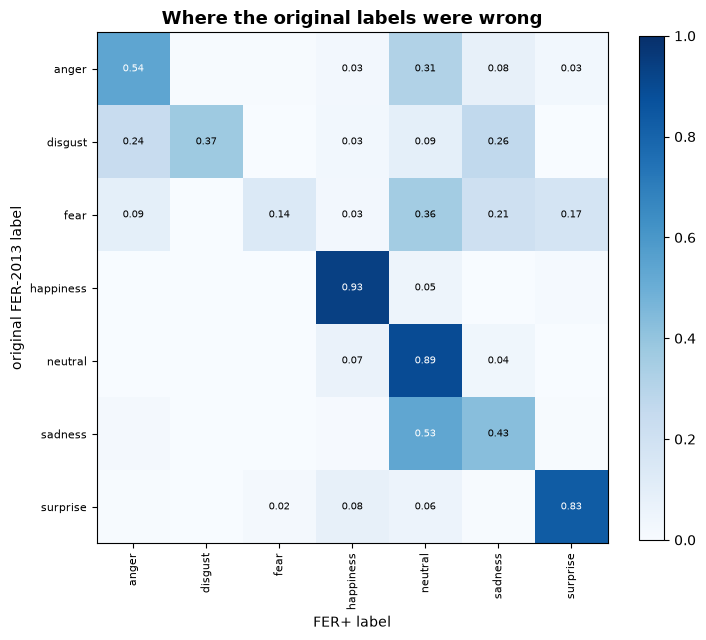

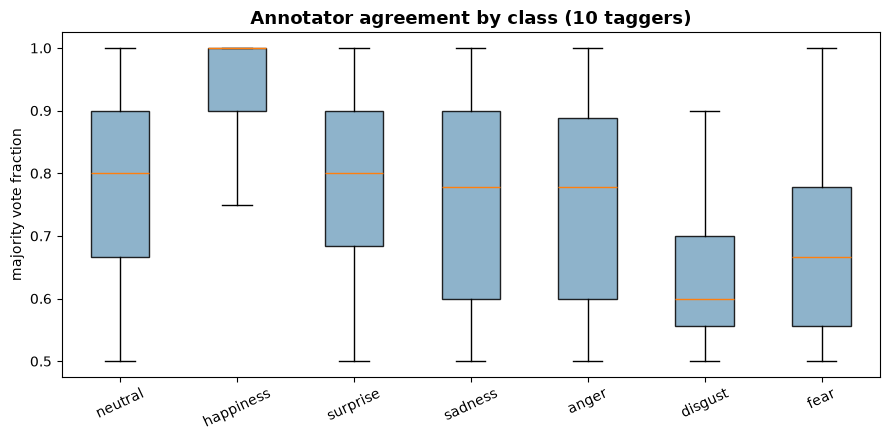


mean agreement by class:
  neutral    n=10,335  agreement 0.799
  happiness  n= 8,958  agreement 0.925
  surprise   n= 3,795  agreement 0.793
  sadness    n= 3,341  agreement 0.756
  anger      n= 2,371  agreement 0.749
  disgust    n=   131  agreement 0.635
  fear       n=   596  agreement 0.660
after dedup: 27,971
Training       22111
PublicTest      2981
PrivateTest     2879
Name: count, dtype: int64
{
  "n": 27971,
  "classes": [
    "neutral",
    "happiness",
    "surprise",
    "sadness",
    "anger",
    "disgust",
    "fear"
  ],
  "splits": {
    "Training": 22111,
    "PublicTest": 2981,
    "PrivateTest": 2879
  },
  "train_counts": {
    "neutral": 7980,
    "happiness": 7000,
    "surprise": 2367,
    "sadness": 2547,
    "anger": 1736,
    "disgust": 76,
    "fear": 405
  },
  "imbalance": 105.0,
  "labels_changed_pct": 0.3119,
  "class_weight_sqrt": {
    "0": 0.6291,
    "1": 0.6717,
    "2": 1.1552,
    "3": 1.1136,
    "4": 1.3489,
    "5": 6.4469,
    "6": 2.7927
 

In [8]:
# %% [markdown]
# # Step 6 — FER+ labels
# Merges Microsoft's 10-annotator labels onto the images you already have.
# Produces both majority-vote and soft-label targets.

# %%
import numpy as np, pandas as pd, json, hashlib, urllib.request
from pathlib import Path
import matplotlib.pyplot as plt

OUT, FIGDIR = Path("artifacts"), Path("figures")
OUT.mkdir(exist_ok=True); FIGDIR.mkdir(exist_ok=True)

# --- fetch FER+ labels -------------------------------------------------
FERPLUS = OUT/"fer2013new.csv"
if not FERPLUS.exists():
    url = "https://raw.githubusercontent.com/microsoft/FERPlus/master/fer2013new.csv"
    urllib.request.urlretrieve(url, FERPLUS)
new = pd.read_csv(FERPLUS)
new.columns = [c.strip() for c in new.columns]
print(new.shape, list(new.columns))

# --- original images, original row order -------------------------------
d = np.load(OUT/"fer2013.npz", allow_pickle=False)
X_all, y_old, usage_old = d["X"], d["y"], d["usage"].astype(str)
assert len(new) == len(X_all), f"row mismatch: {len(new)} vs {len(X_all)}"
print(f"aligned {len(X_all):,} rows")

EMO = ["neutral","happiness","surprise","sadness","anger","disgust","fear","contempt"]
votes = new[EMO].values.astype("float32")
unknown, nf = new["unknown"].values, new["NF"].values

# %%
# ----------------------------------------------------------------------
# FILTER — drop what the annotators couldn't agree was a face or an emotion
# ----------------------------------------------------------------------
keep = (nf == 0) & (unknown <= 1) & (votes.max(1) >= 5)   # majority of 10

print(f"flagged Not-a-Face      : {(nf > 0).sum():,}")
print(f"flagged unknown (2+)    : {(unknown > 1).sum():,}")
print(f"no majority agreement   : {(votes.max(1) < 5).sum():,}")
print(f"surviving               : {keep.sum():,} of {len(keep):,}")

# does FER+ catch the blank images your std check found?
stds = X_all.reshape(len(X_all), -1).std(axis=1)
blanks = np.where(stds < 1.0)[0]
print(f"\nyour {len(blanks)} blank images -> FER+ flagged "
      f"{int((nf[blanks] > 0).sum())} as NF")

# %%
# ----------------------------------------------------------------------
# LABELS — hard (majority) and soft (distribution)
# ----------------------------------------------------------------------
DROP_CONTEMPT = True     # contempt has very few examples; start without it

idx = np.where(keep)[0]
v = votes[idx]

if DROP_CONTEMPT:
    ci = EMO.index("contempt")
    mask = v.argmax(1) != ci
    n_contempt = int((~mask).sum())
    idx, v = idx[mask], v[mask]
    v = np.delete(v, ci, axis=1)
    CLASSES = [e for e in EMO if e != "contempt"]
    print(f"dropped {n_contempt:,} contempt-majority rows; {len(idx):,} remain")
else:
    CLASSES = EMO

y_hard = v.argmax(1).astype("int64")
y_soft = v / v.sum(1, keepdims=True)          # probability distribution
X_new  = X_all[idx]
usage_new = usage_old[idx]

# --- how much did labels actually change? ------------------------------
OLD = ["angry","disgust","fear","happy","sad","surprise","neutral"]
OLD2NEW = {"angry":"anger","disgust":"disgust","fear":"fear","happy":"happiness",
           "sad":"sadness","surprise":"surprise","neutral":"neutral"}
old_mapped = np.array([CLASSES.index(OLD2NEW[OLD[i]]) for i in y_old[idx]])
changed = (old_mapped != y_hard)
print(f"\nlabels changed: {changed.sum():,} of {len(y_hard):,} ({changed.mean():.1%})")

ct = pd.crosstab(pd.Series([CLASSES[i] for i in old_mapped], name="FER-2013"),
                 pd.Series([CLASSES[i] for i in y_hard],     name="FER+"))
print("\n", ct)

# %%
# ----------------------------------------------------------------------
# FIG 14 — label agreement matrix
# ----------------------------------------------------------------------
norm = ct.div(ct.sum(1), axis=0)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(norm.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(norm.columns))); ax.set_xticklabels(norm.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(norm.index)));   ax.set_yticklabels(norm.index, fontsize=8)
ax.set_xlabel("FER+ label"); ax.set_ylabel("original FER-2013 label")
for i in range(len(norm.index)):
    for j in range(len(norm.columns)):
        if norm.values[i,j] > 0.02:
            ax.text(j, i, f"{norm.values[i,j]:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if norm.values[i,j] > .5 else "black")
ax.set_title("Where the original labels were wrong", fontsize=13, weight="bold")
fig.colorbar(im, fraction=0.04)
plt.tight_layout(); plt.savefig(FIGDIR/"14_label_agreement.png", dpi=150); plt.show()

# %%
# ----------------------------------------------------------------------
# FIG 15 — annotator confidence per class
# ----------------------------------------------------------------------
conf = v.max(1) / v.sum(1)
fig, ax = plt.subplots(figsize=(9, 4.5))
data = [conf[y_hard == i] for i in range(len(CLASSES))]
try:
    bp = ax.boxplot(data, tick_labels=CLASSES, patch_artist=True, showfliers=False)
except TypeError:
    bp = ax.boxplot(data, labels=CLASSES, patch_artist=True, showfliers=False)
for b in bp["boxes"]:
    b.set_facecolor("#7aa6c2"); b.set_alpha(.85)
ax.set_ylabel("majority vote fraction"); ax.tick_params(axis="x", rotation=25)
ax.set_title("Annotator agreement by class (10 taggers)", fontsize=13, weight="bold")
plt.tight_layout(); plt.savefig(FIGDIR/"15_annotator_confidence.png", dpi=150); plt.show()

print("\nmean agreement by class:")
for i, c in enumerate(CLASSES):
    m = conf[y_hard == i]
    print(f"  {c:<10} n={len(m):>6,}  agreement {m.mean():.3f}")

# %%
# ----------------------------------------------------------------------
# Dedup (same logic as Step 1b) and save
# ----------------------------------------------------------------------
h = np.array([hashlib.md5(im.tobytes()).hexdigest() for im in X_new])
df = pd.DataFrame({"i": np.arange(len(h)), "hash": h, "usage": usage_new,
                   "label": y_hard})

k = pd.Series(True, index=df.index)
conf_h = df.groupby("hash")["label"].nunique()
k &= ~df["hash"].isin(set(conf_h[conf_h > 1].index))
sub = df[k]; test_h = set(sub.loc[sub.usage != "Training", "hash"])
k &= ~((df.usage == "Training") & df["hash"].isin(test_h))
sub = df[k]; priv = set(sub.loc[sub.usage == "PrivateTest", "hash"])
k &= ~((df.usage == "PublicTest") & df["hash"].isin(priv))
sub = df[k]
k &= ~df["i"].isin(sub[sub.duplicated(["usage","hash"], keep="first")]["i"])

sel = df.loc[k, "i"].values
Xf, yf, ysf, uf = X_new[sel], y_hard[sel], y_soft[sel], usage_new[sel]
print(f"after dedup: {len(yf):,}")
print(pd.Series(uf).value_counts())

np.savez_compressed(OUT/"ferplus_clean.npz",
                    X=Xf, y=yf, y_soft=ysf, usage=uf.astype(str),
                    classes=np.array(CLASSES))

cnt = np.bincount(yf[uf=="Training"], minlength=len(CLASSES))
n, kk = cnt.sum(), len(CLASSES)
sqrtw = {i: float(np.sqrt(n/(kk*c))) if c else 1.0 for i, c in enumerate(cnt)}

summary = {"n": int(len(yf)), "classes": CLASSES,
           "splits": {a: int(b) for a, b in pd.Series(uf).value_counts().items()},
           "train_counts": {CLASSES[i]: int(c) for i, c in enumerate(cnt)},
           "imbalance": round(float(cnt.max()/max(cnt.min(),1)), 2),
           "labels_changed_pct": round(float(changed.mean()), 4),
           "class_weight_sqrt": {str(a): round(b,4) for a,b in sqrtw.items()}}
json.dump(summary, open(OUT/"ferplus_summary.json","w"), indent=2)
print(json.dumps(summary, indent=2))

In [9]:
# %%
import numpy as np, pandas as pd
from pathlib import Path

OUT = Path("artifacts")
new = pd.read_csv(OUT/"fer2013new.csv"); new.columns=[c.strip() for c in new.columns]
EMO = ["neutral","happiness","surprise","sadness","anger","disgust","fear","contempt"]
votes = new[EMO].values.astype("float32")
unknown, nf = new["unknown"].values, new["NF"].values
usage = new["Usage"].values

variants = {
    "strict (current)":   (nf==0) & (unknown<=1) & (votes.max(1)>=5),
    "majority only":      (nf==0) & (votes.max(1)>=5),
    "plurality >=4":      (nf==0) & (unknown<=3) & (votes.max(1)>=4),
    "plurality >=3":      (nf==0) & (unknown<=4) & (votes.max(1)>=3),
    "NF only (loosest)":  (nf==0) & (votes.max(1)>votes.shape[1]*0),
}

rows = []
for name, m in variants.items():
    v = votes[m]
    ci = EMO.index("contempt")
    keep2 = v.argmax(1) != ci
    v2 = np.delete(v[keep2], ci, axis=1)
    lab = v2.argmax(1)
    u = usage[m][keep2]
    tr = lab[u=="Training"]
    cnt = np.bincount(tr, minlength=7)
    CL = [e for e in EMO if e != "contempt"]
    rows.append({"filter": name, "total": int(m.sum()), "train": int(len(tr)),
                 **{CL[i]: int(c) for i, c in enumerate(cnt)},
                 "imbalance": round(cnt.max()/max(cnt.min(),1), 1)})

print(pd.DataFrame(rows).to_string(index=False))

           filter  total  train  neutral  happiness  surprise  sadness  anger  disgust  fear  imbalance
 strict (current)  29648  23588     8216       7227      3011     2701   1866       97   470       84.7
    majority only  31629  25182     8996       7324      3165     3034   2047      107   509       84.1
    plurality >=4  34154  27190     9821       7442      3446     3377   2340      144   620       68.2
    plurality >=3  35328  28116    10243       7517      3554     3505   2456      189   652       54.2
NF only (loosest)  35538  28285    10342       7526      3576     3530   2464      193   654       53.6


In [10]:
# %%
import numpy as np, pandas as pd
from pathlib import Path
new = pd.read_csv(Path("artifacts")/"fer2013new.csv")
new.columns = [c.strip() for c in new.columns]
EMO = ["neutral","happiness","surprise","sadness","anger","disgust","fear"]
v = new[EMO].values.astype("float32")
m = (new["NF"].values == 0)

print(f"{'class':<11}{'majority imgs':>14}{'total votes':>13}{'imgs w/ >=1 vote':>19}")
for i, c in enumerate(EMO):
    maj = int((v[m].argmax(1) == i).sum())
    tot = int(v[m][:, i].sum())
    any_ = int((v[m][:, i] > 0).sum())
    print(f"{c:<11}{maj:>14,}{tot:>13,}{any_:>19,}")

class       majority imgs  total votes   imgs w/ >=1 vote
neutral            13,071      106,962             22,148
happiness           9,350       91,213             13,750
surprise            4,480       41,316              9,773
sadness             4,411       47,194             13,843
anger               3,128       28,331              8,043
disgust               277        5,379              3,410
fear                  821       12,094              5,353


In [13]:
# %% [markdown]
# # Step 7 — Train on FER+ soft labels
# EfficientNetB0 @96px, KL-divergence against the annotator distribution.

# %%
import numpy as np, pandas as pd, json, time, urllib.request
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, classification_report

OUT = Path("artifacts"); MODELS = OUT/"models"; MODELS.mkdir(parents=True, exist_ok=True)
HIST = OUT/"history"; HIST.mkdir(parents=True, exist_ok=True)
SEED = 42; tf.keras.utils.set_random_seed(SEED)

IMG_SIZE, BATCH = 96, 64
EPOCHS_HEAD, EPOCHS_FT = 100, 120
LR_HEAD, LR_FT = 1e-3, 3e-5
UNFREEZE_FRAC = 0.50
SOFT = True          # False -> hard majority labels, for the A/B comparison

print("GPU:", tf.config.list_physical_devices('GPU'))

# %%
# ---- rebuild with plurality>=4 filter, keeping soft labels ------------
new = pd.read_csv(OUT/"fer2013new.csv"); new.columns=[c.strip() for c in new.columns]
d = np.load(OUT/"fer2013.npz", allow_pickle=False)
X_all, usage_all = d["X"], d["usage"].astype(str)

EMO8 = ["neutral","happiness","surprise","sadness","anger","disgust","fear","contempt"]
votes = new[EMO8].values.astype("float32")
mask = (new["NF"].values==0) & (new["unknown"].values<=3) & (votes.max(1)>=4)

idx = np.where(mask)[0]; v = votes[idx]
ci = EMO8.index("contempt"); keep2 = v.argmax(1) != ci
idx, v = idx[keep2], np.delete(v[keep2], ci, axis=1)
CLASSES = [e for e in EMO8 if e != "contempt"]

y_soft = v / v.sum(1, keepdims=True)
y_hard = v.argmax(1).astype("int64")
X, usage = X_all[idx], usage_all[idx]
print(f"{len(y_hard):,} images | classes {CLASSES}")

# ---- dedup ------------------------------------------------------------
import hashlib
h = np.array([hashlib.md5(im.tobytes()).hexdigest() for im in X])
df = pd.DataFrame({"i":np.arange(len(h)), "hash":h, "usage":usage, "lab":y_hard})
k = pd.Series(True, index=df.index)
c_ = df.groupby("hash")["lab"].nunique(); k &= ~df["hash"].isin(set(c_[c_>1].index))
s = df[k]; th = set(s.loc[s.usage!="Training","hash"])
k &= ~((df.usage=="Training") & df["hash"].isin(th))
s = df[k]; ph = set(s.loc[s.usage=="PrivateTest","hash"])
k &= ~((df.usage=="PublicTest") & df["hash"].isin(ph))
s = df[k]; k &= ~df["i"].isin(s[s.duplicated(["usage","hash"],keep="first")]["i"])
sel = df.loc[k,"i"].values

X, y_soft, y_hard, usage = X[sel], y_soft[sel], y_hard[sel], usage[sel]
tr, va, te = usage=="Training", usage=="PublicTest", usage=="PrivateTest"
print(f"after dedup {len(y_hard):,} | train {tr.sum():,} val {va.sum():,} test {te.sum():,}")

# ---- class weights from EFFECTIVE counts (vote mass), not majority ----
eff = y_soft[tr].sum(0)
w = np.sqrt(eff.sum() / (len(CLASSES) * eff))
CLASS_WEIGHT = {i: float(x) for i, x in enumerate(w)}
print("effective train counts:", {c: int(e) for c, e in zip(CLASSES, eff)})
print("sqrt weights:", {c: round(x,3) for c, x in zip(CLASSES, w)})

# %%
# ---- tf.data ----------------------------------------------------------
prep_fn = keras.applications.efficientnet.preprocess_input

def make_ds(Xa, ya, wa, training):
    parts = (Xa, ya, wa) if wa is not None else (Xa, ya)
    ds = tf.data.Dataset.from_tensor_slices(parts)
    if training: ds = ds.shuffle(len(Xa), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    def prep(img, lab, sw=None):
        img = tf.cast(img, tf.float32)[..., tf.newaxis]
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        img = prep_fn(tf.image.grayscale_to_rgb(img))
        return (img, lab, sw) if sw is not None else (img, lab)
    return ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

if SOFT:
    Y = y_soft
    # class_weight doesn't work with soft targets -> use per-sample weights
    sw = (y_soft * np.array([CLASS_WEIGHT[i] for i in range(len(CLASSES))])).sum(1)
    ds_tr = make_ds(X[tr], Y[tr], sw[tr].astype("float32"), True)
    ds_va = make_ds(X[va], Y[va], None, False)
    LOSS, CW = "kl_divergence", None
else:
    Y = y_hard
    ds_tr = make_ds(X[tr], Y[tr], None, True)
    ds_va = make_ds(X[va], Y[va], None, False)
    LOSS, CW = "sparse_categorical_crossentropy", CLASS_WEIGHT
ds_te = make_ds(X[te], y_hard[te], None, False)

# %%
# ---- model ------------------------------------------------------------
aug = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED),
    layers.RandomZoom(0.10, seed=SEED),
    layers.RandomTranslation(0.08, 0.08, seed=SEED)], name="augment")

base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                         input_shape=(IMG_SIZE,IMG_SIZE,3))
base.trainable = False
inp = layers.Input((IMG_SIZE,IMG_SIZE,3))
x = base(aug(inp), training=False)
x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.4)(x)
x = layers.Dense(256, use_bias=False)(x)
x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
x = layers.Dropout(0.4)(x)
model = keras.Model(inp, layers.Dense(len(CLASSES), activation="softmax")(x),
                    name="FERPlus_soft")

# ---- phase 1 ----------------------------------------------------------
model.compile(keras.optimizers.Adam(LR_HEAD), loss=LOSS, metrics=["accuracy"])
t0=time.time()
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_HEAD, class_weight=CW,
               callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=6,
                          restore_best_weights=True, verbose=1)], verbose=1)
print(f"phase 1: {(time.time()-t0)/60:.1f} min")

# ---- phase 2 ----------------------------------------------------------
base.trainable = True
cut = int(len(base.layers)*(1-UNFREEZE_FRAC))
for l_ in base.layers[:cut]: l_.trainable = False
for l_ in base.layers:
    if isinstance(l_, layers.BatchNormalization): l_.trainable = False

model.compile(keras.optimizers.Adam(LR_FT), loss=LOSS, metrics=["accuracy"])
t0=time.time()
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_FT, class_weight=CW,
               callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=10,
                            restore_best_weights=True, verbose=1),
                          keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5,
                            patience=4, min_lr=1e-8, verbose=1)], verbose=1)
print(f"phase 2: {(time.time()-t0)/60:.1f} min")

# %%
# ---- evaluate (against hard majority labels) --------------------------
tag = f"FERPlus_{'soft' if SOFT else 'hard'}_{IMG_SIZE}_conv"
p = model.predict(ds_te, verbose=0).argmax(1)
yt = y_hard[te]

res = {"tag": tag, "soft_labels": SOFT, "n_test": int(len(yt)),
       "epochs_head": len(h1.history["loss"]), "epochs_ft": len(h2.history["loss"]),
       "test_accuracy": round(float(accuracy_score(yt,p)),4),
       "test_macro_f1": round(float(f1_score(yt,p,average="macro")),4),
       "test_weighted_f1": round(float(f1_score(yt,p,average="weighted")),4),
       "test_f1_per_class": {c: round(float(x),4) for c,x in
           zip(CLASSES, f1_score(yt,p,average=None,labels=range(len(CLASSES))))}}

model.save(MODELS/f"{tag}.keras"); np.save(OUT/f"preds_{tag}.npy", p)
np.save(OUT/f"ytest_{tag}.npy", yt)
json.dump(res, open(OUT/f"result_{tag}.json","w"), indent=2)
json.dump({"classes": CLASSES}, open(OUT/"ferplus_classes.json","w"))

print(json.dumps(res, indent=2))
print("\n", classification_report(yt, p, target_names=CLASSES, digits=4))

GPU: []
33,962 images | classes ['neutral', 'happiness', 'surprise', 'sadness', 'anger', 'disgust', 'fear']
after dedup 32,204 | train 25,515 val 3,349 test 3,340
effective train counts: {'neutral': 8642, 'happiness': 7160, 'surprise': 2725, 'sadness': 3745, 'anger': 2106, 'disgust': 331, 'fear': 803}
sqrt weights: {'neutral': np.float32(0.649), 'happiness': np.float32(0.713), 'surprise': np.float32(1.156), 'sadness': np.float32(0.987), 'anger': np.float32(1.316), 'disgust': np.float32(3.317), 'fear': np.float32(2.13)}
Epoch 1/100


/opt/miniconda3/envs/dl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


399/399 ━━━━━━━━━━━━━━━━━━━━ 57s 128ms/step - accuracy: 0.4580 - loss: 1.0236 - val_accuracy: 0.5838 - val_loss: 0.8547
Epoch 2/100
399/399 ━━━━━━━━━━━━━━━━━━━━ 49s 124ms/step - accuracy: 0.5260 - loss: 0.8556 - val_accuracy: 0.5978 - val_loss: 0.8329
Epoch 3/100
399/399 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - accuracy: 0.5420 - loss: 0.8281 - val_accuracy: 0.6073 - val_loss: 0.8164
Epoch 4/100
399/399 ━━━━━━━━━━━━━━━━━━━━ 43s 108ms/step - accuracy: 0.5516 - loss: 0.8160 - val_accuracy: 0.5966 - val_loss: 0.8146
Epoch 5/100
399/399 ━━━━━━━━━━━━━━━━━━━━ 46s 116ms/step - accuracy: 0.5549 - loss: 0.8032 - val_accuracy: 0.6076 - val_loss: 0.8032
Epoch 6/100
399/399 ━━━━━━━━━━━━━━━━━━━━ 44s 109ms/step - accuracy: 0.5590 - loss: 0.7981 - val_accuracy: 0.6085 - val_loss: 0.8024
Epoch 7/100
399/399 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - accuracy: 0.5676 - loss: 0.7939 - val_accuracy: 0.6232 - val_loss: 0.7873
Epoch 8/100
399/399 ━━━━━━━━━━━━━━━━━━━━ 45s 114ms/step - accuracy: 0.5644 - loss: 0.792

In [14]:
# %%
from pathlib import Path
from collections import Counter

ROOT = Path.home()/"Documents/RAF_DB"
IMG_EXT = {".jpg",".jpeg",".png",".bmp"}

print("=== tree (dirs only, 3 levels) ===")
for d in sorted(p for p in ROOT.rglob("*") if p.is_dir()):
    rel = d.relative_to(ROOT)
    if len(rel.parts) <= 3:
        n_img = sum(1 for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMG_EXT)
        print(f"{'  '*(len(rel.parts)-1)}{rel.name}/  [{n_img} imgs]" if n_img
              else f"{'  '*(len(rel.parts)-1)}{rel.name}/")

print("\n=== non-image files (labels, metadata) ===")
for f in sorted(ROOT.rglob("*")):
    if f.is_file() and f.suffix.lower() not in IMG_EXT:
        print(f"  {f.relative_to(ROOT)}  ({f.stat().st_size/1024:.1f} KB)")

print("\n=== image totals ===")
imgs = [f for f in ROOT.rglob("*") if f.is_file() and f.suffix.lower() in IMG_EXT]
print(f"total images: {len(imgs):,}")
print("by extension:", Counter(f.suffix.lower() for f in imgs))

print("\n=== sample filenames ===")
for f in imgs[:8]:
    print(" ", f.relative_to(ROOT))

print("\n=== image dimensions (sample of 10) ===")
from PIL import Image
import random
for f in random.sample(imgs, min(10, len(imgs))):
    with Image.open(f) as im:
        print(f"  {f.name}: {im.size} {im.mode}")

=== tree (dirs only, 3 levels) ===
DATASET/
  test/
    1/  [329 imgs]
    2/  [74 imgs]
    3/  [160 imgs]
    4/  [1185 imgs]
    5/  [478 imgs]
    6/  [162 imgs]
    7/  [680 imgs]
  train/
    1/  [1290 imgs]
    2/  [281 imgs]
    3/  [717 imgs]
    4/  [4772 imgs]
    5/  [1982 imgs]
    6/  [705 imgs]
    7/  [2524 imgs]

=== non-image files (labels, metadata) ===
  .DS_Store  (6.0 KB)
  test_labels.csv  (74.9 KB)
  train_labels.csv  (323.6 KB)

=== image totals ===
total images: 15,339
by extension: Counter({'.jpg': 15339})

=== sample filenames ===
  DATASET/test/7/test_2986_aligned.jpg
  DATASET/test/7/test_2676_aligned.jpg
  DATASET/test/7/test_3064_aligned.jpg
  DATASET/test/7/test_2819_aligned.jpg
  DATASET/test/7/test_2714_aligned.jpg
  DATASET/test/7/test_3014_aligned.jpg
  DATASET/test/7/test_2606_aligned.jpg
  DATASET/test/7/test_2799_aligned.jpg

=== image dimensions (sample of 10) ===
  train_06067_aligned.jpg: (100, 100) RGB
  train_08724_aligned.jpg: (100, 100) RG

In [15]:
# %% [markdown]
# # Step 8 — RAF-DB, native 100x100 RGB
# Note: label order differs from FER+ models. Check RAF_CLASSES before inference.

# %%
import numpy as np, pandas as pd, json, time
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, classification_report

ROOT = Path.home()/"Documents/RAF_DB/DATASET"
OUT  = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
MODELS = OUT/"models"; MODELS.mkdir(parents=True, exist_ok=True)

SEED = 42; tf.keras.utils.set_random_seed(SEED)

IMG_SIZE = 112          # 100 native; 112 gives the backbone a 4x4 final map
BATCH    = 64
EPOCHS_HEAD, EPOCHS_FT = 60, 120
LR_HEAD, LR_FT = 1e-3, 3e-5
UNFREEZE_FRAC  = 0.50
VAL_FRAC = 0.15         # RAF-DB has no official val split

# folder index -> name  (verified against published class counts)
RAF_CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]
print("GPU:", tf.config.list_physical_devices('GPU'))

# %%
# ---- build file lists -------------------------------------------------
def listing(split):
    rows = []
    for i, name in enumerate(RAF_CLASSES, start=1):
        for f in sorted((ROOT/split/str(i)).glob("*.jpg")):
            rows.append({"path": str(f), "label": i-1, "name": name})
    return pd.DataFrame(rows)

tr_all, test_df = listing("train"), listing("test")
print(tr_all.groupby("name").size().sort_values(ascending=False))
assert len(tr_all) == 12271 and len(test_df) == 3068, "unexpected counts"

# stratified val carve-out
rng = np.random.RandomState(SEED)
val_idx = (tr_all.groupby("label", group_keys=False)
                 .apply(lambda g: g.sample(max(1,int(len(g)*VAL_FRAC)), random_state=SEED))
                 .index)
val_df   = tr_all.loc[val_idx]
train_df = tr_all.drop(val_idx)
print(f"\ntrain {len(train_df):,}  val {len(val_df):,}  test {len(test_df):,}")

# ---- class weights ----------------------------------------------------
cnt = train_df["label"].value_counts().sort_index().values
w = np.sqrt(cnt.sum()/(len(RAF_CLASSES)*cnt))
CLASS_WEIGHT = {i: float(x) for i, x in enumerate(w)}
print("sqrt weights:", {RAF_CLASSES[i]: round(x,3) for i, x in enumerate(w)})

# %%
# ---- tf.data ----------------------------------------------------------
prep = keras.applications.efficientnet.preprocess_input

def make_ds(df, training):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values,
                                             df["label"].values.astype("int64")))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    def load(p, y):
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        img = tf.image.resize(tf.cast(img, tf.float32), (IMG_SIZE, IMG_SIZE))
        return prep(img), y
    return (ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH).prefetch(tf.data.AUTOTUNE))

ds_tr, ds_va, ds_te = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)
b, l = next(iter(ds_tr)); print("batch:", b.shape, float(tf.reduce_min(b)), float(tf.reduce_max(b)))

# %%
# ---- model ------------------------------------------------------------
aug = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED),
    layers.RandomZoom(0.10, seed=SEED),
    layers.RandomTranslation(0.06, 0.06, seed=SEED),
    layers.RandomContrast(0.15, seed=SEED),     # RGB now, so contrast aug is useful
], name="augment")

base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                         input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False
inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = base(aug(inp), training=False)
x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.4)(x)
x = layers.Dense(256, use_bias=False)(x)
x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
x = layers.Dropout(0.4)(x)
model = keras.Model(inp, layers.Dense(7, activation="softmax")(x), name="RAFDB")

model.compile(keras.optimizers.Adam(LR_HEAD),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_HEAD,
               class_weight=CLASS_WEIGHT, verbose=1,
               callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=8,
                          restore_best_weights=True, verbose=1)])
print(f"phase 1: {(time.time()-t0)/60:.1f} min")

# %%
# ---- fine-tune --------------------------------------------------------
base.trainable = True
cut = int(len(base.layers)*(1-UNFREEZE_FRAC))
for l_ in base.layers[:cut]: l_.trainable = False
for l_ in base.layers:
    if isinstance(l_, layers.BatchNormalization): l_.trainable = False

model.compile(keras.optimizers.Adam(LR_FT),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_FT,
               class_weight=CLASS_WEIGHT, verbose=1,
               callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=12,
                            restore_best_weights=True, verbose=1),
                          keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5,
                            patience=5, min_lr=1e-8, verbose=1)])
print(f"phase 2: {(time.time()-t0)/60:.1f} min")

# %%
# ---- evaluate ---------------------------------------------------------
tag = f"RAFDB_{IMG_SIZE}"
p = model.predict(ds_te, verbose=0).argmax(1)
yt = test_df["label"].values

res = {"tag": tag, "img_size": IMG_SIZE, "n_test": int(len(yt)),
       "epochs_head": len(h1.history["loss"]), "epochs_ft": len(h2.history["loss"]),
       "test_accuracy": round(float(accuracy_score(yt,p)),4),
       "test_macro_f1": round(float(f1_score(yt,p,average="macro")),4),
       "test_weighted_f1": round(float(f1_score(yt,p,average="weighted")),4),
       "test_f1_per_class": {c: round(float(v),4) for c,v in
            zip(RAF_CLASSES, f1_score(yt,p,average=None,labels=range(7)))}}

model.save(MODELS/f"{tag}.keras")
np.save(OUT/f"preds_{tag}.npy", p); np.save(OUT/f"ytest_{tag}.npy", yt)
json.dump({"classes": RAF_CLASSES}, open(OUT/"rafdb_classes.json","w"))
json.dump(res, open(OUT/f"result_{tag}.json","w"), indent=2)

print(json.dumps(res, indent=2))
print(f"\nFER+ soft best: acc 0.8278  macro-F1 0.7307  (different test set)")
print("\n", classification_report(yt, p, target_names=RAF_CLASSES, digits=4))

GPU: []
name
happiness    4772
neutral      2524
sadness      1982
surprise     1290
disgust       717
anger         705
fear          281
dtype: int64

train 10,434  val 1,837  test 3,068
sqrt weights: {'surprise': np.float64(1.166), 'fear': np.float64(2.497), 'disgust': np.float64(1.563), 'happiness': np.float64(0.606), 'sadness': np.float64(0.941), 'anger': np.float64(1.576), 'neutral': np.float64(0.833)}
batch: (64, 112, 112, 3) 0.0 255.0
Epoch 1/60


/opt/miniconda3/envs/dl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


164/164 ━━━━━━━━━━━━━━━━━━━━ 38s 197ms/step - accuracy: 0.4040 - loss: 1.6862 - val_accuracy: 0.5531 - val_loss: 1.2749
Epoch 2/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 27s 167ms/step - accuracy: 0.4660 - loss: 1.4549 - val_accuracy: 0.5411 - val_loss: 1.2426
Epoch 3/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 26s 161ms/step - accuracy: 0.4923 - loss: 1.3867 - val_accuracy: 0.5455 - val_loss: 1.2279
Epoch 4/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 27s 166ms/step - accuracy: 0.5027 - loss: 1.3412 - val_accuracy: 0.5378 - val_loss: 1.2848
Epoch 5/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 29s 175ms/step - accuracy: 0.5117 - loss: 1.3207 - val_accuracy: 0.5683 - val_loss: 1.1761
Epoch 6/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 27s 163ms/step - accuracy: 0.5243 - loss: 1.2960 - val_accuracy: 0.5700 - val_loss: 1.1826
Epoch 7/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 30s 181ms/step - accuracy: 0.5299 - loss: 1.2775 - val_accuracy: 0.5700 - val_loss: 1.1861
Epoch 8/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 28s 168ms/step - accuracy: 0.5380 - loss: 1.2602 - val

In [16]:
# %% [markdown]
# # Step 8b — RAF-DB, starting from FER+ instead of ImageNet
# Sequential transfer: FERPlus_soft_96 backbone -> fine-tune on RAF-DB.
# Label order differs from FER+ models — see RAF_CLASSES.

# %%
import numpy as np, pandas as pd, json, time
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, classification_report

ROOT = Path.home()/"Documents/RAF_DB/DATASET"
PROJ = Path.home()/"Documents/fer2013-emotion-cnn"
OUT  = PROJ/"artifacts"
MODELS = OUT/"models"; MODELS.mkdir(parents=True, exist_ok=True)

SEED = 42; tf.keras.utils.set_random_seed(SEED)

IMG_SIZE = 96           # must match the FER+ model
BATCH    = 64
EPOCHS_HEAD, EPOCHS_FT = 60, 120
LR_HEAD, LR_FT = 1e-3, 3e-5
UNFREEZE_FRAC  = 0.50
VAL_FRAC = 0.15

RAF_CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]
print("GPU:", tf.config.list_physical_devices('GPU'))

# %%
# ---- file lists -------------------------------------------------------
def listing(split):
    rows = []
    for i, name in enumerate(RAF_CLASSES, start=1):
        for f in sorted((ROOT/split/str(i)).glob("*.jpg")):
            rows.append({"path": str(f), "label": i-1, "name": name})
    return pd.DataFrame(rows)

tr_all, test_df = listing("train"), listing("test")
assert len(tr_all) == 12271 and len(test_df) == 3068, \
    f"unexpected counts: {len(tr_all)}/{len(test_df)}"
print(tr_all.groupby("name").size().sort_values(ascending=False))

val_idx = (tr_all.groupby("label", group_keys=False)
                 .apply(lambda g: g.sample(max(1, int(len(g)*VAL_FRAC)), random_state=SEED))
                 .index)
val_df, train_df = tr_all.loc[val_idx], tr_all.drop(val_idx)
print(f"\ntrain {len(train_df):,}  val {len(val_df):,}  test {len(test_df):,}")

cnt = train_df["label"].value_counts().sort_index().values
w = np.sqrt(cnt.sum()/(len(RAF_CLASSES)*cnt))
CLASS_WEIGHT = {i: float(x) for i, x in enumerate(w)}
print("sqrt weights:", {RAF_CLASSES[i]: round(x,3) for i, x in enumerate(w)})

# %%
# ---- tf.data ----------------------------------------------------------
prep = keras.applications.efficientnet.preprocess_input

def make_ds(df, training):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values,
                                             df["label"].values.astype("int64")))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    def load(p, y):
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        img = tf.image.resize(tf.cast(img, tf.float32), (IMG_SIZE, IMG_SIZE))
        return prep(img), y
    return (ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
              .batch(BATCH).prefetch(tf.data.AUTOTUNE))

ds_tr, ds_va, ds_te = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)
b, _ = next(iter(ds_tr))
print("batch:", b.shape, float(tf.reduce_min(b)), float(tf.reduce_max(b)))

# %%
# ---- model: FER+ backbone -> new head ---------------------------------
src_path = next(PROJ.rglob("FERPlus_soft_96.keras"))
src = keras.models.load_model(src_path)
print("source:", src_path.name)

src_base = next(l for l in src.layers
                if isinstance(l, keras.Model) and "efficientnet" in l.name.lower())

aug = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED),
    layers.RandomZoom(0.10, seed=SEED),
    layers.RandomTranslation(0.06, 0.06, seed=SEED),
    layers.RandomContrast(0.15, seed=SEED),
], name="augment")

base = keras.applications.EfficientNetB0(include_top=False, weights=None,
                                         input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.set_weights(src_base.get_weights())
base.trainable = False
print("backbone weights loaded from FER+")

inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = base(aug(inp), training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.4)(x)
model = keras.Model(inp, layers.Dense(7, activation="softmax")(x),
                    name="RAFDB_from_FERPlus")

# %%
# ---- phase 1: head only -----------------------------------------------
model.compile(keras.optimizers.Adam(LR_HEAD),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h1 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_HEAD,
               class_weight=CLASS_WEIGHT, verbose=1,
               callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=8,
                          restore_best_weights=True, verbose=1)])
print(f"phase 1: {(time.time()-t0)/60:.1f} min")

# %%
# ---- phase 2: fine-tune -----------------------------------------------
base.trainable = True
cut = int(len(base.layers)*(1-UNFREEZE_FRAC))
for l_ in base.layers[:cut]:
    l_.trainable = False
for l_ in base.layers:
    if isinstance(l_, layers.BatchNormalization):
        l_.trainable = False

model.compile(keras.optimizers.Adam(LR_FT),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h2 = model.fit(ds_tr, validation_data=ds_va, epochs=EPOCHS_FT,
               class_weight=CLASS_WEIGHT, verbose=1,
               callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=12,
                            restore_best_weights=True, verbose=1),
                          keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5,
                            patience=5, min_lr=1e-8, verbose=1)])
print(f"phase 2: {(time.time()-t0)/60:.1f} min")

# %%
# ---- evaluate ---------------------------------------------------------
tag = f"RAFDB_{IMG_SIZE}_fromFERPlus"
p  = model.predict(ds_te, verbose=0).argmax(1)
yt = test_df["label"].values

res = {"tag": tag, "img_size": IMG_SIZE, "source_model": src_path.name,
       "n_test": int(len(yt)),
       "epochs_head": len(h1.history["loss"]), "epochs_ft": len(h2.history["loss"]),
       "test_accuracy": round(float(accuracy_score(yt,p)),4),
       "test_macro_f1": round(float(f1_score(yt,p,average="macro")),4),
       "test_weighted_f1": round(float(f1_score(yt,p,average="weighted")),4),
       "test_f1_per_class": {c: round(float(v),4) for c,v in
            zip(RAF_CLASSES, f1_score(yt,p,average=None,labels=range(7)))}}

model.save(MODELS/f"{tag}.keras")
np.save(OUT/f"preds_{tag}.npy", p); np.save(OUT/f"ytest_{tag}.npy", yt)
json.dump({"classes": RAF_CLASSES}, open(OUT/"rafdb_classes.json","w"))
json.dump(res, open(OUT/f"result_{tag}.json","w"), indent=2)

print(json.dumps(res, indent=2))
print("\nRAFDB_112 (ImageNet start): acc 0.7565  macro-F1 0.6586")
print(f"this run (FER+ start)     : acc {res['test_accuracy']:.4f}  "
      f"macro-F1 {res['test_macro_f1']:.4f}")
print("\n", classification_report(yt, p, target_names=RAF_CLASSES, digits=4))

GPU: []
name
happiness    4772
neutral      2524
sadness      1982
surprise     1290
disgust       717
anger         705
fear          281
dtype: int64

train 10,434  val 1,837  test 3,068
sqrt weights: {'surprise': np.float64(1.166), 'fear': np.float64(2.497), 'disgust': np.float64(1.563), 'happiness': np.float64(0.606), 'sadness': np.float64(0.941), 'anger': np.float64(1.576), 'neutral': np.float64(0.833)}
batch: (64, 96, 96, 3) 0.0 255.0
source: FERPlus_soft_96.keras
backbone weights loaded from FER+
Epoch 1/60


/opt/miniconda3/envs/dl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


164/164 ━━━━━━━━━━━━━━━━━━━━ 36s 181ms/step - accuracy: 0.5728 - loss: 1.2917 - val_accuracy: 0.6821 - val_loss: 0.8880
Epoch 2/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 21s 127ms/step - accuracy: 0.6220 - loss: 1.1012 - val_accuracy: 0.6968 - val_loss: 0.8521
Epoch 3/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 23s 137ms/step - accuracy: 0.6373 - loss: 1.0417 - val_accuracy: 0.7039 - val_loss: 0.8259
Epoch 4/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 21s 128ms/step - accuracy: 0.6503 - loss: 1.0172 - val_accuracy: 0.7017 - val_loss: 0.8479
Epoch 5/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 21s 130ms/step - accuracy: 0.6534 - loss: 0.9853 - val_accuracy: 0.7169 - val_loss: 0.8123
Epoch 6/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 20s 120ms/step - accuracy: 0.6567 - loss: 0.9857 - val_accuracy: 0.7191 - val_loss: 0.8052
Epoch 7/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - accuracy: 0.6698 - loss: 0.9594 - val_accuracy: 0.7137 - val_loss: 0.8161
Epoch 8/60
164/164 ━━━━━━━━━━━━━━━━━━━━ 20s 119ms/step - accuracy: 0.6704 - loss: 0.9502 - val

In [17]:
# %% [markdown]
# # Step 9 — Merged FER+ (22k) + RAF-DB (12k)
# Common 7-class taxonomy, unified to RAF-DB ordering.
# FER+ contributes volume + soft labels; RAF-DB contributes resolution + color.

# %%
import numpy as np, pandas as pd, json, time
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, f1_score, classification_report

RAF  = Path.home()/"Documents/RAF_DB/DATASET"
PROJ = Path.home()/"Documents/fer2013-emotion-cnn"
OUT  = PROJ/"artifacts"; MODELS = OUT/"models"; MODELS.mkdir(parents=True, exist_ok=True)

SEED = 42; tf.keras.utils.set_random_seed(SEED)
IMG_SIZE, BATCH = 96, 64
EPOCHS_HEAD, EPOCHS_FT = 60, 150
LR_HEAD, LR_FT = 1e-3, 3e-5
UNFREEZE_FRAC = 0.50
GRAYSCALE_RAF = True     # match FER+ domain; set False to keep RAF-DB in color

# unified ordering = RAF-DB's
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]
FERPLUS_ORDER = ["neutral","happiness","surprise","sadness","anger","disgust","fear"]
FP2UNI = np.array([CLASSES.index(c) for c in FERPLUS_ORDER])   # remap vector
print("FER+ -> unified:", dict(zip(FERPLUS_ORDER, FP2UNI)))

# %%
# ---- RAF-DB: file paths -----------------------------------------------
def raf_listing(split):
    rows = []
    for i, name in enumerate(CLASSES, start=1):
        for f in sorted((RAF/split/str(i)).glob("*.jpg")):
            rows.append({"path": str(f), "label": i-1})
    return pd.DataFrame(rows)

raf_train, raf_test = raf_listing("train"), raf_listing("test")
assert len(raf_train) == 12271 and len(raf_test) == 3068
print(f"RAF-DB: train {len(raf_train):,}  test {len(raf_test):,}")

# ---- FER+: in-memory arrays, remapped to unified order ----------------
fp = np.load(OUT/"ferplus_clean.npz", allow_pickle=False)
fp_X, fp_soft, fp_u = fp["X"], fp["y_soft"], fp["usage"].astype(str)
fp_hard_uni = FP2UNI[fp_soft.argmax(1)]
fp_soft_uni = fp_soft[:, np.argsort(FP2UNI)]          # reorder columns
tr_m = fp_u == "Training"
print(f"FER+ train: {tr_m.sum():,}")

print("\nunified train totals:")
tot = (pd.Series([CLASSES[i] for i in fp_hard_uni[tr_m]]).value_counts()
       .add(pd.Series([CLASSES[i] for i in raf_train['label']]).value_counts(), fill_value=0))
print(tot.astype(int).sort_values(ascending=False))

cnt = np.array([tot[c] for c in CLASSES])
w = np.sqrt(cnt.sum()/(len(CLASSES)*cnt))
CLASS_WEIGHT = {i: float(x) for i, x in enumerate(w)}
print("\nsqrt weights:", {CLASSES[i]: round(x,3) for i, x in enumerate(w)})

# %%
# ---- tf.data: two sources, one pipeline -------------------------------
prep = keras.applications.efficientnet.preprocess_input

def raf_ds(df, training):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values,
                                             df["label"].values.astype("int64")))
    if training: ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    def load(p, y):
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        if GRAYSCALE_RAF:
            img = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(img))
        img = tf.image.resize(tf.cast(img, tf.float32), (IMG_SIZE, IMG_SIZE))
        return prep(img), y
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)

def fp_ds(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype("int64")))
    if training: ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    def load(img, y):
        img = tf.cast(img, tf.float32)[..., tf.newaxis]
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
        return prep(tf.image.grayscale_to_rgb(img)), y
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)

train_ds = (tf.data.Dataset.sample_from_datasets(
                [raf_ds(raf_train, True), fp_ds(fp_X[tr_m], fp_hard_uni[tr_m], True)],
                weights=[0.5, 0.5], seed=SEED)      # equal sampling despite size gap
            .batch(BATCH).prefetch(tf.data.AUTOTUNE))

# RAF-DB test is both val and test — matches published practice
eval_ds = raf_ds(raf_test, False).batch(BATCH).prefetch(tf.data.AUTOTUNE)

STEPS = (len(raf_train) + int(tr_m.sum())) // BATCH
print(f"steps/epoch: {STEPS}")
b, _ = next(iter(train_ds)); print("batch:", b.shape)

# %%
# ---- model: start from FER+ backbone ----------------------------------
src = keras.models.load_model(next(PROJ.rglob("FERPlus_soft_96.keras")))
src_base = next(l for l in src.layers
                if isinstance(l, keras.Model) and "efficientnet" in l.name.lower())

aug = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED),
    layers.RandomZoom(0.10, seed=SEED),
    layers.RandomTranslation(0.06, 0.06, seed=SEED),
    layers.RandomContrast(0.15, seed=SEED),
], name="augment")

base = keras.applications.EfficientNetB0(include_top=False, weights=None,
                                         input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.set_weights(src_base.get_weights()); base.trainable = False

inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = base(aug(inp), training=False)
x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.4)(x)
x = layers.Dense(256, use_bias=False)(x)
x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
x = layers.Dropout(0.4)(x)
model = keras.Model(inp, layers.Dense(7, activation="softmax")(x), name="Merged")

model.compile(keras.optimizers.Adam(LR_HEAD),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h1 = model.fit(train_ds, validation_data=eval_ds, epochs=EPOCHS_HEAD,
               steps_per_epoch=STEPS, class_weight=CLASS_WEIGHT, verbose=1,
               callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=8,
                          restore_best_weights=True, verbose=1)])
print(f"phase 1: {(time.time()-t0)/60:.1f} min")

# %%
base.trainable = True
cut = int(len(base.layers)*(1-UNFREEZE_FRAC))
for l_ in base.layers[:cut]: l_.trainable = False
for l_ in base.layers:
    if isinstance(l_, layers.BatchNormalization): l_.trainable = False

model.compile(keras.optimizers.Adam(LR_FT),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
t0 = time.time()
h2 = model.fit(train_ds, validation_data=eval_ds, epochs=EPOCHS_FT,
               steps_per_epoch=STEPS, class_weight=CLASS_WEIGHT, verbose=1,
               callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=15,
                            restore_best_weights=True, verbose=1),
                          keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5,
                            patience=6, min_lr=1e-8, verbose=1)])
print(f"phase 2: {(time.time()-t0)/60:.1f} min")

# %%
tag = f"Merged_{IMG_SIZE}{'_gray' if GRAYSCALE_RAF else '_rgb'}"
p  = model.predict(eval_ds, verbose=0).argmax(1)
yt = raf_test["label"].values

res = {"tag": tag, "grayscale_raf": GRAYSCALE_RAF, "n_test": int(len(yt)),
       "n_train": int(len(raf_train) + tr_m.sum()),
       "epochs_head": len(h1.history["loss"]), "epochs_ft": len(h2.history["loss"]),
       "test_accuracy": round(float(accuracy_score(yt,p)),4),
       "test_macro_f1": round(float(f1_score(yt,p,average="macro")),4),
       "test_weighted_f1": round(float(f1_score(yt,p,average="weighted")),4),
       "test_f1_per_class": {c: round(float(v),4) for c,v in
            zip(CLASSES, f1_score(yt,p,average=None,labels=range(7)))}}

model.save(MODELS/f"{tag}.keras")
np.save(OUT/f"preds_{tag}.npy", p); np.save(OUT/f"ytest_{tag}.npy", yt)
json.dump({"classes": CLASSES}, open(OUT/"unified_classes.json","w"))
json.dump(res, open(OUT/f"result_{tag}.json","w"), indent=2)

print(json.dumps(res, indent=2))
print("\nRAFDB_96_fromFERPlus: acc 0.7598  macro-F1 0.6722")
print(f"merged              : acc {res['test_accuracy']:.4f}  macro-F1 {res['test_macro_f1']:.4f}")
print("\n", classification_report(yt, p, target_names=CLASSES, digits=4))

FER+ -> unified: {'neutral': np.int64(6), 'happiness': np.int64(3), 'surprise': np.int64(0), 'sadness': np.int64(4), 'anger': np.int64(5), 'disgust': np.int64(2), 'fear': np.int64(1)}
RAF-DB: train 12,271  test 3,068
FER+ train: 22,111

unified train totals:
happiness    11772
neutral      10504
sadness       4529
surprise      3657
anger         2441
disgust        793
fear           686
Name: count, dtype: int64

sqrt weights: {'surprise': np.float64(1.159), 'fear': np.float64(2.676), 'disgust': np.float64(2.489), 'happiness': np.float64(0.646), 'sadness': np.float64(1.041), 'anger': np.float64(1.419), 'neutral': np.float64(0.684)}
steps/epoch: 537
batch: (64, 96, 96, 3)
Epoch 1/60


/opt/miniconda3/envs/dl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


537/537 ━━━━━━━━━━━━━━━━━━━━ 78s 122ms/step - accuracy: 0.6745 - loss: 0.9588 - val_accuracy: 0.6630 - val_loss: 0.9780
Epoch 2/60
  1/537 ━━━━━━━━━━━━━━━━━━━━ 35s 67ms/step - accuracy: 0.7143 - loss: 0.6920

/opt/miniconda3/envs/dl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


537/537 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7143 - loss: 0.6920 - val_accuracy: 0.6620 - val_loss: 0.9780
Epoch 3/60
537/537 ━━━━━━━━━━━━━━━━━━━━ 60s 111ms/step - accuracy: 0.7040 - loss: 0.8453 - val_accuracy: 0.6744 - val_loss: 0.9230
Epoch 4/60
537/537 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8571 - loss: 0.2568 - val_accuracy: 0.6750 - val_loss: 0.9236
Epoch 5/60
537/537 ━━━━━━━━━━━━━━━━━━━━ 57s 106ms/step - accuracy: 0.7110 - loss: 0.8160 - val_accuracy: 0.6692 - val_loss: 0.9261
Epoch 6/60
537/537 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8571 - loss: 0.5299 - val_accuracy: 0.6711 - val_loss: 0.9275
Epoch 7/60
537/537 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - accuracy: 0.7152 - loss: 0.8032 - val_accuracy: 0.6786 - val_loss: 0.8925
Epoch 8/60
537/537 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9286 - loss: 0.2438 - val_accuracy: 0.6796 - val_loss: 0.8927
Epoch 9/60
537/537 ━━━━━━━━━━━━━━━━━━━━ 60s 112ms/step - accuracy: 0.7177 - loss: 0.7944 - val_accuracy: 

In [18]:
# %%
import numpy as np, json
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report

OUT = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]

tags = ["RAFDB_112", "RAFDB_96_fromFERPlus", "Merged_96_gray"]
P = {t: np.load(OUT/f"preds_{t}.npy") for t in tags if (OUT/f"preds_{t}.npy").exists()}
yt = np.load(OUT/"ytest_RAFDB_112.npy")

stack = np.stack(list(P.values()))
vote = np.array([np.bincount(stack[:,i], minlength=7).argmax() for i in range(len(yt))])

for t, pr in P.items():
    print(f"{t:<24} acc {accuracy_score(yt,pr):.4f}  macro-F1 {f1_score(yt,pr,average='macro'):.4f}")
print(f"{'ENSEMBLE':<24} acc {accuracy_score(yt,vote):.4f}  "
      f"macro-F1 {f1_score(yt,vote,average='macro'):.4f}")
print("\n", classification_report(yt, vote, target_names=CLASSES, digits=4))

RAFDB_112                acc 0.7565  macro-F1 0.6586
RAFDB_96_fromFERPlus     acc 0.7598  macro-F1 0.6722
Merged_96_gray           acc 0.7471  macro-F1 0.6695
ENSEMBLE                 acc 0.7728  macro-F1 0.6893

               precision    recall  f1-score   support

    surprise     0.7469    0.7356    0.7412       329
        fear     0.5867    0.5946    0.5906        74
     disgust     0.4147    0.5625    0.4775       160
   happiness     0.9370    0.8667    0.9005      1185
     sadness     0.6996    0.7992    0.7461       478
       anger     0.6757    0.6173    0.6452       162
     neutral     0.7341    0.7147    0.7243       680

    accuracy                         0.7728      3068
   macro avg     0.6850    0.6986    0.6893      3068
weighted avg     0.7852    0.7728    0.7773      3068



In [20]:
# %% [markdown]
# # Step 11 — ArcFace face-pretrained features probe
# Extracts 512-d embeddings from InsightFace w600k_r50 (trained on 600K face
# identities), then trains a small head. Tests whether face-pretrained features
# beat ImageNet ones on RAF-DB. Runs locally, CPU is fine.

# %%
import numpy as np, pandas as pd, cv2, json, time
from pathlib import Path
import insightface
from insightface.model_zoo import get_model

RAF  = Path.home()/"Documents/RAF_DB/DATASET"
OUT  = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
ARC  = Path.home()/".insightface/models/buffalo_l/w600k_r50.onnx"
assert ARC.exists(), f"not found: {ARC}"

CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]
SEED = 42

def listing(split):
    rows = []
    for i, name in enumerate(CLASSES, start=1):
        for f in sorted((RAF/split/str(i)).glob("*.jpg")):
            rows.append({"path": str(f), "label": i-1})
    return pd.DataFrame(rows)

train_df, test_df = listing("train"), listing("test")
print(f"train {len(train_df):,}  test {len(test_df):,}")

# %%
# ---- extract embeddings ------------------------------------------------
rec = get_model(str(ARC))
rec.prepare(ctx_id=-1)          # -1 = CPU
print("ArcFace loaded | input:", rec.input_shape)

def embed(paths, batch=64, flip=False):
    """RAF-DB images are already face-aligned, so no detection needed."""
    out = []
    for s in range(0, len(paths), batch):
        imgs = []
        for p in paths[s:s+batch]:
            im = cv2.imread(p)
            if flip: im = cv2.flip(im, 1)
            imgs.append(cv2.resize(im, (112, 112)))
        out.append(rec.get_feat(imgs))
        if s % (batch*40) == 0:
            print(f"  {s}/{len(paths)}", flush=True)
    return np.vstack(out).astype("float32")

CACHE = OUT/"arcface_rafdb.npz"
if CACHE.exists():
    z = np.load(CACHE)
    Etr, Etr_f, Ete, Ete_f = z["Etr"], z["Etr_f"], z["Ete"], z["Ete_f"]
    print("loaded cached embeddings")
else:
    t0 = time.time()
    print("train..."),      ; Etr   = embed(train_df["path"].tolist())
    print("train flipped..."); Etr_f = embed(train_df["path"].tolist(), flip=True)
    print("test...")        ; Ete   = embed(test_df["path"].tolist())
    print("test flipped..."); Ete_f = embed(test_df["path"].tolist(), flip=True)
    np.savez_compressed(CACHE, Etr=Etr, Etr_f=Etr_f, Ete=Ete, Ete_f=Ete_f)
    print(f"extracted in {(time.time()-t0)/60:.1f} min")

ytr, yte = train_df["label"].values, test_df["label"].values
print("embedding dim:", Etr.shape[1])

# %%
# ---- normalize; flip-augment train, flip-average test ------------------
def l2(a): return a / np.linalg.norm(a, axis=1, keepdims=True)

Xtr = l2(np.vstack([Etr, Etr_f]))          # doubles training data
Ytr = np.concatenate([ytr, ytr])
Xte = l2((l2(Ete) + l2(Ete_f)) / 2)        # test-time augmentation
print(f"train {Xtr.shape}  test {Xte.shape}")

# %%
# ---- (a) linear probe: how linearly separable is expression? -----------
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

t0 = time.time()
lin = LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced",
                         n_jobs=-1, random_state=SEED).fit(Xtr, Ytr)
p_lin = lin.predict(Xte)
print(f"LINEAR PROBE ({time.time()-t0:.0f}s)  acc {accuracy_score(yte,p_lin):.4f}  "
      f"macro-F1 {f1_score(yte,p_lin,average='macro'):.4f}")

# %%
# ---- (b) MLP head ------------------------------------------------------
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(SEED)

cnt = np.bincount(Ytr, minlength=7)
w = np.sqrt(cnt.sum()/(7*cnt))
CW = {i: float(x) for i, x in enumerate(w)}

head = keras.Sequential([
    layers.Input((Xtr.shape[1],)),
    layers.Dense(512, use_bias=False), layers.BatchNormalization(),
    layers.Activation("relu"), layers.Dropout(0.4),
    layers.Dense(256, use_bias=False), layers.BatchNormalization(),
    layers.Activation("relu"), layers.Dropout(0.3),
    layers.Dense(7, activation="softmax"),
])
head.compile(keras.optimizers.Adam(1e-3),
             loss="sparse_categorical_crossentropy", metrics=["accuracy"])

h = head.fit(Xtr, Ytr, validation_data=(Xte, yte), epochs=200, batch_size=256,
             class_weight=CW, verbose=0,
             callbacks=[keras.callbacks.EarlyStopping("val_loss", patience=20,
                          restore_best_weights=True, verbose=1),
                        keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5,
                          patience=8, min_lr=1e-6)])
p_mlp = head.predict(Xte, verbose=0).argmax(1)

# %%
# ---- results -----------------------------------------------------------
res = {
  "linear": {"acc": round(float(accuracy_score(yte,p_lin)),4),
             "macro_f1": round(float(f1_score(yte,p_lin,average="macro")),4)},
  "mlp":    {"acc": round(float(accuracy_score(yte,p_mlp)),4),
             "macro_f1": round(float(f1_score(yte,p_mlp,average="macro")),4),
             "epochs": len(h.history["loss"])},
  "per_class_mlp": {c: round(float(v),4) for c,v in
                    zip(CLASSES, f1_score(yte,p_mlp,average=None,labels=range(7)))},
}
np.save(OUT/"preds_ArcFace_mlp.npy", p_mlp)
head.save(OUT/"models/ArcFace_head.keras")
json.dump(res, open(OUT/"result_ArcFace_probe.json","w"), indent=2)

print(json.dumps(res, indent=2))
print("\nfor comparison:")
print("  RAFDB_96_fromFERPlus  acc 0.7598  macro-F1 0.6722")
print("  ensemble of 3         acc 0.7728  macro-F1 0.6893")
print("\n", classification_report(yte, p_mlp, target_names=CLASSES, digits=4))

train 12,271  test 3,068
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
ArcFace loaded | input: ['None', 3, 112, 112]
train...
  0/12271


2026-08-18 15:32:35.323 python[62956:31217362] 2026-08-18 15:32:35.323125 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:32:38.368 python[62956:31217362] 2026-08-18 15:32:38.368180 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:32:41.014 python[62956:31217362] 2026-08-18 15:32:41.014169 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:32:43.979 python[62956:31217362] 2026-08-18 15:32:43.979561 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:32:46.663 python[62956:31217362] 2026-08-18 15:32:46.663285 [W:onnxruntime:, execution

  2560/12271


2026-08-18 15:34:02.640 python[62956:31217362] 2026-08-18 15:34:02.641497 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:34:04.444 python[62956:31217362] 2026-08-18 15:34:04.445640 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:34:06.388 python[62956:31217362] 2026-08-18 15:34:06.389247 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:34:08.472 python[62956:31217362] 2026-08-18 15:34:08.473311 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:34:10.507 python[62956:31217362] 2026-08-18 15:34:10.508594 [W:onnxruntime:, execution

  5120/12271


2026-08-18 15:35:23.780 python[62956:31217362] 2026-08-18 15:35:23.782091 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:35:25.457 python[62956:31217362] 2026-08-18 15:35:25.459090 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:35:27.169 python[62956:31217362] 2026-08-18 15:35:27.170181 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:35:28.828 python[62956:31217362] 2026-08-18 15:35:28.829577 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:35:30.533 python[62956:31217362] 2026-08-18 15:35:30.534564 [W:onnxruntime:, execution

... (21 outputs left out)

2026-08-18 15:46:42.381 python[62956:31217362] 2026-08-18 15:46:42.362090 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:46:43.989 python[62956:31217362] 2026-08-18 15:46:43.969868 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:46:45.602 python[62956:31217362] 2026-08-18 15:46:45.582993 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:46:47.207 python[62956:31217362] 2026-08-18 15:46:47.187751 [W:onnxruntime:, execution_frame.cc:913 VerifyOutputSizes] Expected shape from model of {1,512} does not match actual shape of {64,512} for output 683
2026-08-18 15:46:48.775 python[62956:31217362] 2026-08-18 15:46:48.755888 [W:onnxruntime:, execution

extracted in 14.4 min
embedding dim: 512
train (24542, 512)  test (3068, 512)


/opt/miniconda3/envs/dl/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


LINEAR PROBE (1s)  acc 0.6930  macro-F1 0.5990
Epoch 26: early stopping
Restoring model weights from the end of the best epoch: 6.
{
  "linear": {
    "acc": 0.693,
    "macro_f1": 0.599
  },
  "mlp": {
    "acc": 0.7396,
    "macro_f1": 0.6436,
    "epochs": 26
  },
  "per_class_mlp": {
    "surprise": 0.6417,
    "fear": 0.4852,
    "disgust": 0.4103,
    "happiness": 0.8774,
    "sadness": 0.7121,
    "anger": 0.6631,
    "neutral": 0.7156
  }
}

for comparison:
  RAFDB_96_fromFERPlus  acc 0.7598  macro-F1 0.6722
  ensemble of 3         acc 0.7728  macro-F1 0.6893

               precision    recall  f1-score   support

    surprise     0.6331    0.6505    0.6417       329
        fear     0.4316    0.5541    0.4852        74
     disgust     0.3770    0.4500    0.4103       160
   happiness     0.9227    0.8363    0.8774      1185
     sadness     0.7026    0.7218    0.7121       478
       anger     0.5885    0.7593    0.6631       162
     neutral     0.7209    0.7103    0.7156  

In [21]:
# %%
import numpy as np
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report

OUT = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]

tags = ["RAFDB_112","RAFDB_96_fromFERPlus","Merged_96_gray","ArcFace_mlp"]
P = {t: np.load(OUT/f"preds_{t}.npy") for t in tags if (OUT/f"preds_{t}.npy").exists()}
yt = np.load(OUT/"ytest_RAFDB_112.npy")

stack = np.stack(list(P.values()))
vote = np.array([np.bincount(stack[:,i], minlength=7).argmax() for i in range(len(yt))])

for t, pr in P.items():
    print(f"{t:<24} acc {accuracy_score(yt,pr):.4f}  macro-F1 {f1_score(yt,pr,average='macro'):.4f}")
print(f"{'ENSEMBLE-4':<24} acc {accuracy_score(yt,vote):.4f}  "
      f"macro-F1 {f1_score(yt,vote,average='macro'):.4f}")
print(f"  (3-model was      acc 0.7728  macro-F1 0.6893)")
print("\n", classification_report(yt, vote, target_names=CLASSES, digits=4))

RAFDB_112                acc 0.7565  macro-F1 0.6586
RAFDB_96_fromFERPlus     acc 0.7598  macro-F1 0.6722
Merged_96_gray           acc 0.7471  macro-F1 0.6695
ArcFace_mlp              acc 0.7396  macro-F1 0.6436
ENSEMBLE-4               acc 0.7911  macro-F1 0.7054
  (3-model was      acc 0.7728  macro-F1 0.6893)

               precision    recall  f1-score   support

    surprise     0.7420    0.7781    0.7596       329
        fear     0.6000    0.5676    0.5833        74
     disgust     0.4527    0.5687    0.5042       160
   happiness     0.9413    0.8937    0.9169      1185
     sadness     0.7023    0.8243    0.7584       478
       anger     0.7123    0.6420    0.6753       162
     neutral     0.7758    0.7074    0.7400       680

    accuracy                         0.7911      3068
   macro avg     0.7038    0.7117    0.7054      3068
weighted avg     0.8002    0.7911    0.7938      3068



In [22]:
# %% [markdown]
# # Step 11c — Soft voting
# Re-predicts probabilities from all four models, then compares
# hard vote / soft vote / weighted soft vote.

# %%
import numpy as np, pandas as pd, json
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score, f1_score, classification_report

RAF  = Path.home()/"Documents/RAF_DB/DATASET"
PROJ = Path.home()/"Documents/fer2013-emotion-cnn"
OUT  = PROJ/"artifacts"
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]

test_df = pd.DataFrame([
    {"path": str(f), "label": i-1}
    for i, _ in enumerate(CLASSES, start=1)
    for f in sorted((RAF/"test"/str(i)).glob("*.jpg"))
])
yt = test_df["label"].values
print(f"test {len(yt):,}")

prep = keras.applications.efficientnet.preprocess_input

def cnn_probs(model_path, img_size, grayscale):
    m = keras.models.load_model(model_path)
    def load(p, y):
        img = tf.io.decode_jpeg(tf.io.read_file(p), channels=3)
        if grayscale:
            img = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(img))
        img = tf.image.resize(tf.cast(img, tf.float32), (img_size, img_size))
        return prep(img), y
    ds = (tf.data.Dataset.from_tensor_slices((test_df["path"].values, yt))
            .map(load, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(64).prefetch(tf.data.AUTOTUNE))
    return m.predict(ds, verbose=0)

# (tag, filename, img_size, grayscale) — must match each model's training config
SPECS = [
    ("RAFDB_112",            "RAFDB_112.keras",            112, False),
    ("RAFDB_96_fromFERPlus", "RAFDB_96_fromFERPlus.keras",  96, False),
    ("Merged_96_gray",       "Merged_96_gray.keras",        96, True),
]

PROBS = {}
for tag, fname, size, gray in SPECS:
    hits = list(PROJ.rglob(fname))
    if not hits:
        print(f"SKIP {tag} — not found"); continue
    PROBS[tag] = cnn_probs(hits[0], size, gray)
    print(f"{tag:<24} done  {PROBS[tag].shape}")

# ---- ArcFace from cached embeddings ----------------------------------
z = np.load(OUT/"arcface_rafdb.npz")
def l2(a): return a / np.linalg.norm(a, axis=1, keepdims=True)
Xte = l2((l2(z["Ete"]) + l2(z["Ete_f"])) / 2)
head = keras.models.load_model(OUT/"models/ArcFace_head.keras")
PROBS["ArcFace_mlp"] = head.predict(Xte, verbose=0)
print(f"{'ArcFace_mlp':<24} done  {PROBS['ArcFace_mlp'].shape}")

np.savez_compressed(OUT/"probs_rafdb_test.npz", **PROBS)

# %%
# ---- compare voting schemes ------------------------------------------
def score(p, name):
    a, f = accuracy_score(yt, p), f1_score(yt, p, average="macro")
    print(f"{name:<26} acc {a:.4f}  macro-F1 {f:.4f}")
    return a, f

print("individual:")
for t, pr in PROBS.items():
    score(pr.argmax(1), "  " + t)

print("\nensembles:")
stack = np.stack(list(PROBS.values()))                     # (M, N, 7)
hard  = np.array([np.bincount(stack.argmax(2)[:,i], minlength=7).argmax()
                  for i in range(len(yt))])
score(hard, "hard vote")

soft = stack.mean(0).argmax(1)
score(soft, "soft vote (mean)")

# geometric mean — penalizes any model that's confidently wrong
geo = np.exp(np.log(np.clip(stack, 1e-9, 1)).mean(0)).argmax(1)
score(geo, "soft vote (geometric)")

# weight each model by its own macro-F1
w = np.array([f1_score(yt, pr.argmax(1), average="macro") for pr in PROBS.values()])
w = w / w.sum()
wsoft = (stack * w[:, None, None]).sum(0).argmax(1)
score(wsoft, "weighted soft vote")
print("  weights:", {t: round(float(x),3) for t, x in zip(PROBS, w)})

# %%
# ---- best scheme, full report ----------------------------------------
cands = {"hard": hard, "soft": soft, "geometric": geo, "weighted": wsoft}
best = max(cands, key=lambda k: f1_score(yt, cands[k], average="macro"))
p = cands[best]
print(f"\nBEST: {best}")
np.save(OUT/"preds_ENSEMBLE_best.npy", p)
json.dump({"scheme": best,
           "acc": round(float(accuracy_score(yt,p)),4),
           "macro_f1": round(float(f1_score(yt,p,average="macro")),4),
           "members": list(PROBS),
           "per_class": {c: round(float(v),4) for c,v in
                zip(CLASSES, f1_score(yt,p,average=None,labels=range(7)))}},
          open(OUT/"result_ensemble_best.json","w"), indent=2)
print("\n", classification_report(yt, p, target_names=CLASSES, digits=4))

test 3,068
RAFDB_112                done  (3068, 7)
RAFDB_96_fromFERPlus     done  (3068, 7)
Merged_96_gray           done  (3068, 7)
ArcFace_mlp              done  (3068, 7)
individual:
  RAFDB_112                acc 0.7565  macro-F1 0.6586
  RAFDB_96_fromFERPlus     acc 0.7415  macro-F1 0.6417
  Merged_96_gray           acc 0.7181  macro-F1 0.6256
  ArcFace_mlp              acc 0.7396  macro-F1 0.6436

ensembles:
hard vote                  acc 0.7865  macro-F1 0.7018
soft vote (mean)           acc 0.7999  macro-F1 0.7191
soft vote (geometric)      acc 0.8184  macro-F1 0.7438
weighted soft vote         acc 0.8015  macro-F1 0.7205
  weights: {'RAFDB_112': 0.256, 'RAFDB_96_fromFERPlus': 0.25, 'Merged_96_gray': 0.243, 'ArcFace_mlp': 0.25}

BEST: geometric

               precision    recall  f1-score   support

    surprise     0.7955    0.7568    0.7757       329
        fear     0.7097    0.5946    0.6471        74
     disgust     0.6757    0.4688    0.5535       160
   happiness     

In [1]:
# %%
import torch, torchvision, PIL
from facenet_pytorch import InceptionResnetV1
print("torch", torch.__version__, "| tv", torchvision.__version__, "| pillow", PIL.__version__)
print("mps:", torch.backends.mps.is_available())

torch 2.2.2 | tv 0.17.2 | pillow 12.3.0
mps: True


In [1]:
# %%
import torch, torchvision, numpy, PIL
from facenet_pytorch import InceptionResnetV1
print("torch", torch.__version__, "| tv", torchvision.__version__)
print("numpy", numpy.__version__, "| pillow", PIL.__version__)
print("mps:", torch.backends.mps.is_available())

torch 2.13.0 | tv 0.28.0
numpy 2.5.2 | pillow 12.3.0
mps: True


In [3]:
# %% [markdown]
# # Step 12 — Fine-tune a face-pretrained backbone (PyTorch + MPS)
# InceptionResnetV1 pretrained on VGGFace2, fine-tuned on RAF-DB.
# Images are cached in RAM up front — no DataLoader workers, no spawn issues.

# %%
import numpy as np, pandas as pd, json, time, os
from pathlib import Path
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from facenet_pytorch import InceptionResnetV1
from sklearn.metrics import accuracy_score, f1_score, classification_report

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

RAF = Path.home()/"Documents/RAF_DB/DATASET"
OUT = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
(OUT/"models").mkdir(parents=True, exist_ok=True)

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", DEV)

CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]
IMG = 160
BATCH = 48
EPOCHS_HEAD, EPOCHS_FT = 12, 40
LR_HEAD, LR_FT = 1e-3, 1e-4
PATIENCE = 8

# %%
# ---- load every image into RAM once ------------------------------------
def load_split(split):
    imgs, labels = [], []
    for i, _ in enumerate(CLASSES, start=1):
        for f in sorted((RAF/split/str(i)).glob("*.jpg")):
            imgs.append(np.array(Image.open(f).convert("RGB")))
            labels.append(i-1)
    return np.stack(imgs), np.array(labels, dtype=np.int64)

t0 = time.time()
Xtr, ytr = load_split("train")
Xte, yte = load_split("test")
print(f"train {Xtr.shape}  test {Xte.shape}  ({time.time()-t0:.0f}s)")
assert len(ytr) == 12271 and len(yte) == 3068

tf_train = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.06,0.06), scale=(0.9,1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
    transforms.RandomErasing(p=0.25, scale=(0.02,0.12)),
])
tf_eval = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

class RafDataset(Dataset):
    def __init__(self, X, y, tf): self.X, self.y, self.tf = X, y, tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return self.tf(Image.fromarray(self.X[i])), int(self.y[i])

dl_train = DataLoader(RafDataset(Xtr, ytr, tf_train), batch_size=BATCH,
                      shuffle=True, num_workers=0)
dl_test  = DataLoader(RafDataset(Xte, yte, tf_eval), batch_size=BATCH,
                      shuffle=False, num_workers=0)

cnt = np.bincount(ytr, minlength=len(CLASSES))
w = np.sqrt(cnt.sum()/(len(CLASSES)*cnt))
CW = torch.tensor(w, dtype=torch.float32, device=DEV)
print("sqrt weights:", {CLASSES[i]: round(float(x),3) for i, x in enumerate(w)})

# %%
# ---- model -------------------------------------------------------------
class FERNet(nn.Module):
    def __init__(self, n=7):
        super().__init__()
        self.backbone = InceptionResnetV1(pretrained="vggface2")
        self.head = nn.Sequential(
            nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, n),
        )
    def forward(self, x): return self.head(self.backbone(x))

model = FERNet().to(DEV)
print("params:", round(sum(p.numel() for p in model.parameters())/1e6, 2), "M")

crit = nn.CrossEntropyLoss(weight=CW, label_smoothing=0.05)

def evaluate():
    model.eval(); P = []
    with torch.no_grad():
        for x, _ in dl_test:
            P.append(model(x.to(DEV)).argmax(1).cpu().numpy())
    P = np.concatenate(P)
    return accuracy_score(yte,P), f1_score(yte,P,average="macro"), P

def run(epochs, lr, tag):
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                            lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best_f1, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train(); tot, t0 = 0.0, time.time()
        for x, y in dl_train:
            x, y = x.to(DEV), y.to(DEV)
            opt.zero_grad()
            loss = crit(model(x), y)
            loss.backward(); opt.step()
            tot += loss.item()*len(y)
        sched.step()
        acc, f1, _ = evaluate()
        flag = ""
        if f1 > best_f1:
            best_f1, bad = f1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            flag = " *best*"
        else:
            bad += 1
        print(f"  [{tag}] ep {ep+1:>2}/{epochs} loss {tot/len(ytr):.4f} "
              f"acc {acc:.4f} macroF1 {f1:.4f} ({time.time()-t0:.0f}s){flag}", flush=True)
        if bad >= PATIENCE:
            print(f"  early stop at epoch {ep+1}"); break
    if best_state is not None:
        model.load_state_dict(best_state)
    return best_f1

# %%
# ---- phase 1: head only ------------------------------------------------
for p in model.backbone.parameters(): p.requires_grad = False
print("PHASE 1 — head only")
run(EPOCHS_HEAD, LR_HEAD, "head")

# %%
# ---- phase 2: unfreeze the last blocks ---------------------------------
for p in model.backbone.parameters(): p.requires_grad = False
for name, p in model.backbone.named_parameters():
    if any(k in name for k in ["repeat_3", "block8", "mixed_7a", "last_linear", "last_bn"]):
        p.requires_grad = True
print(f"\nPHASE 2 — fine-tune | trainable "
      f"{sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")
run(EPOCHS_FT, LR_FT, "ft")

# %%
# ---- results + probabilities for the ensemble --------------------------
acc, f1, P = evaluate()
model.eval(); probs = []
with torch.no_grad():
    for x, _ in dl_test:
        probs.append(torch.softmax(model(x.to(DEV)), 1).cpu().numpy())
probs = np.concatenate(probs)

tag = "VGGFace2_ft"
torch.save(model.state_dict(), OUT/"models"/f"{tag}.pt")
np.save(OUT/f"preds_{tag}.npy", P)
np.save(OUT/f"probs_{tag}.npy", probs)

res = {"tag": tag, "device": DEV,
       "test_accuracy": round(float(acc),4),
       "test_macro_f1": round(float(f1),4),
       "per_class": {c: round(float(v),4) for c,v in
            zip(CLASSES, f1_score(yte,P,average=None,labels=range(7)))}}
json.dump(res, open(OUT/f"result_{tag}.json","w"), indent=2)

print(json.dumps(res, indent=2))
print("\nbest ensemble (geometric): acc 0.8184  macro-F1 0.7438")
print("best single (RAFDB_112):   acc 0.7565  macro-F1 0.6586")
print("\n", classification_report(yte, P, target_names=CLASSES, digits=4))

device: mps
train (12271, 100, 100, 3)  test (3068, 100, 100, 3)  (3s)
sqrt weights: {'surprise': 1.166, 'fear': 2.498, 'disgust': 1.564, 'happiness': 0.606, 'sadness': 0.94, 'anger': 1.577, 'neutral': 0.833}
params: 28.04 M
PHASE 1 — head only
  [head] ep  1/12 loss 1.7135 acc 0.5205 macroF1 0.3891 (55s) *best*
  [head] ep  2/12 loss 1.6328 acc 0.5326 macroF1 0.4015 (45s) *best*
  [head] ep  3/12 loss 1.6160 acc 0.5306 macroF1 0.4157 (45s) *best*
  [head] ep  4/12 loss 1.5958 acc 0.5424 macroF1 0.4145 (45s)
  [head] ep  5/12 loss 1.5846 acc 0.5492 macroF1 0.4167 (44s) *best*
  [head] ep  6/12 loss 1.5708 acc 0.5495 macroF1 0.4312 (45s) *best*
  [head] ep  7/12 loss 1.5678 acc 0.5495 macroF1 0.4366 (45s) *best*
  [head] ep  8/12 loss 1.5636 acc 0.5518 macroF1 0.4420 (46s) *best*
  [head] ep  9/12 loss 1.5519 acc 0.5574 macroF1 0.4449 (45s) *best*
  [head] ep 10/12 loss 1.5422 acc 0.5636 macroF1 0.4417 (45s)
  [head] ep 11/12 loss 1.5400 acc 0.5600 macroF1 0.4455 (45s) *best*
  [head] e

In [4]:
# %% [markdown]
# # Step 13 — Ensemble with VGGFace2_ft
# Tests whether the weaker Keras models still add value now that one member
# is 5pp stronger than the previous best ensemble.

# %%
import numpy as np, json
from pathlib import Path
from itertools import combinations
from sklearn.metrics import accuracy_score, f1_score, classification_report

OUT = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]

z = np.load(OUT/"probs_rafdb_test.npz")
PROBS = {k: z[k] for k in z.files}
PROBS["VGGFace2_ft"] = np.load(OUT/"probs_VGGFace2_ft.npy")
yt = np.load(OUT/"ytest_RAFDB_112.npy")

# guard: prediction order must match across all members
assert all(p.shape == (len(yt), 7) for p in PROBS.values()), "shape mismatch"
print(f"{len(PROBS)} members, {len(yt):,} test images\n")

def geo(members):
    s = np.stack([PROBS[m] for m in members])
    return np.exp(np.log(np.clip(s, 1e-9, 1)).mean(0)).argmax(1)

def score(p):
    return accuracy_score(yt, p), f1_score(yt, p, average="macro")

print("individual:")
for t, pr in PROBS.items():
    a, f = score(pr.argmax(1))
    print(f"  {t:<24} acc {a:.4f}  macro-F1 {f:.4f}")

# %%
# ---- every subset containing VGGFace2_ft -------------------------------
others = [k for k in PROBS if k != "VGGFace2_ft"]
rows = []
for r in range(0, len(others)+1):
    for combo in combinations(others, r):
        members = ("VGGFace2_ft",) + combo
        a, f = score(geo(members))
        rows.append((f, a, members))

rows.sort(reverse=True)
print("\ntop 10 subsets (geometric mean, sorted by macro-F1):")
for f, a, m in rows[:10]:
    print(f"  acc {a:.4f}  macro-F1 {f:.4f}   {' + '.join(m)}")

best_f1, best_acc, best_members = rows[0]
print(f"\nBEST: {' + '.join(best_members)}")
print(f"  acc {best_acc:.4f}  macro-F1 {best_f1:.4f}")
print(f"  VGGFace2_ft alone: acc {score(PROBS['VGGFace2_ft'].argmax(1))[0]:.4f}  "
      f"macro-F1 {score(PROBS['VGGFace2_ft'].argmax(1))[1]:.4f}")

# %%
# ---- weighted variant: give VGGFace2_ft more say -----------------------
print("\nweighted geometric (VGGFace2_ft weight vs others at 1.0):")
for wv in [1, 2, 3, 4, 6]:
    s, ws = [], []
    for m in PROBS:
        s.append(PROBS[m]); ws.append(wv if m == "VGGFace2_ft" else 1.0)
    s = np.stack(s); ws = np.array(ws); ws = ws/ws.sum()
    p = np.exp((np.log(np.clip(s,1e-9,1)) * ws[:,None,None]).sum(0)).argmax(1)
    a, f = score(p)
    print(f"  w={wv}: acc {a:.4f}  macro-F1 {f:.4f}")

# %%
# ---- save the winner ---------------------------------------------------
p = geo(best_members)
np.save(OUT/"preds_ENSEMBLE_v2.npy", p)
json.dump({"members": list(best_members), "scheme": "geometric",
           "acc": round(float(best_acc),4), "macro_f1": round(float(best_f1),4),
           "per_class": {c: round(float(v),4) for c,v in
                zip(CLASSES, f1_score(yt,p,average=None,labels=range(7)))}},
          open(OUT/"result_ensemble_v2.json","w"), indent=2)

print("\n", classification_report(yt, p, target_names=CLASSES, digits=4))

5 members, 3,068 test images

individual:
  RAFDB_112                acc 0.7565  macro-F1 0.6586
  RAFDB_96_fromFERPlus     acc 0.7415  macro-F1 0.6417
  Merged_96_gray           acc 0.7181  macro-F1 0.6256
  ArcFace_mlp              acc 0.7396  macro-F1 0.6436
  VGGFace2_ft              acc 0.8722  macro-F1 0.8084

top 10 subsets (geometric mean, sorted by macro-F1):
  acc 0.8801  macro-F1 0.8251   VGGFace2_ft + ArcFace_mlp
  acc 0.8787  macro-F1 0.8172   VGGFace2_ft + RAFDB_112 + ArcFace_mlp
  acc 0.8768  macro-F1 0.8142   VGGFace2_ft + Merged_96_gray + ArcFace_mlp
  acc 0.8739  macro-F1 0.8132   VGGFace2_ft + RAFDB_96_fromFERPlus + ArcFace_mlp
  acc 0.8726  macro-F1 0.8094   VGGFace2_ft + RAFDB_96_fromFERPlus
  acc 0.8722  macro-F1 0.8084   VGGFace2_ft
  acc 0.8729  macro-F1 0.8077   VGGFace2_ft + RAFDB_112
  acc 0.8686  macro-F1 0.8012   VGGFace2_ft + RAFDB_112 + RAFDB_96_fromFERPlus + ArcFace_mlp
  acc 0.8651  macro-F1 0.7995   VGGFace2_ft + Merged_96_gray
  acc 0.8651  macro-F1 0

In [1]:
# port_head.py — run in the dl env
import numpy as np
from pathlib import Path
from tensorflow import keras

OUT = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
m = keras.models.load_model(OUT/"models/ArcFace_head.keras")

w = {}
for i, layer in enumerate(m.layers):
    ws = layer.get_weights()
    if not ws: continue
    for j, arr in enumerate(ws):
        w[f"L{i}_{layer.__class__.__name__}_{j}"] = arr
    print(f"L{i} {layer.__class__.__name__:<20} {[a.shape for a in ws]}")

np.savez(OUT/"arcface_head_weights.npz", **w)
print(f"\nsaved -> {OUT/'arcface_head_weights.npz'}")

L0 Dense                [(512, 512)]
L1 BatchNormalization   [(512,), (512,), (512,), (512,)]
L4 Dense                [(512, 256)]
L5 BatchNormalization   [(256,), (256,), (256,), (256,)]
L8 Dense                [(256, 7), (7,)]

saved -> /path/to/Documents/fer2013-emotion-cnn/artifacts/arcface_head_weights.npz


In [3]:
# %%
import numpy as np, torch, torch.nn as nn
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
DEV = "mps" if torch.backends.mps.is_available() else "cpu"

class ArcHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(512,512,bias=False); self.bn1 = nn.BatchNorm1d(512, eps=1e-3)
        self.fc2 = nn.Linear(512,256,bias=False); self.bn2 = nn.BatchNorm1d(256, eps=1e-3)
        self.fc3 = nn.Linear(256,7)
    def forward(self,x):
        x = torch.relu(self.bn1(self.fc1(x)))
        x = torch.relu(self.bn2(self.fc2(x)))
        return self.fc3(x)

def load_arc_head():
    z = np.load(ART/"arcface_head_weights.npz")
    g = lambda n: torch.tensor(z[n], dtype=torch.float32)
    h = ArcHead()
    h.fc1.weight.data = g("L0_Dense_0").T
    h.fc2.weight.data = g("L4_Dense_0").T
    h.fc3.weight.data = g("L8_Dense_0").T
    h.fc3.bias.data   = g("L8_Dense_1")
    for bn, L in [(h.bn1,"L1"), (h.bn2,"L5")]:
        bn.weight.data  = g(f"{L}_BatchNormalization_0")
        bn.bias.data    = g(f"{L}_BatchNormalization_1")
        bn.running_mean = g(f"{L}_BatchNormalization_2")
        bn.running_var  = g(f"{L}_BatchNormalization_3")
    return h.to(DEV).eval()

arc = load_arc_head()

z = np.load(ART/"arcface_rafdb.npz")
l2 = lambda a: a/np.linalg.norm(a, axis=1, keepdims=True)
X  = l2((l2(z["Ete"]) + l2(z["Ete_f"]))/2).astype("float32")
yt = np.load(ART/"ytest_RAFDB_112.npy")

with torch.no_grad():
    p = torch.softmax(arc(torch.tensor(X, device=DEV)), 1).cpu().numpy().argmax(1)

print(f"ported: acc {accuracy_score(yt,p):.4f}  macro-F1 {f1_score(yt,p,average='macro'):.4f}")
print( "keras : acc 0.7396  macro-F1 0.6436")

ported: acc 0.7396  macro-F1 0.6436
keras : acc 0.7396  macro-F1 0.6436


In [5]:
# %%
import torch, torch.nn as nn
from pathlib import Path
from facenet_pytorch import InceptionResnetV1

ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
DEV = "mps" if torch.backends.mps.is_available() else "cpu"

class FERNet(nn.Module):
    def __init__(self, n=7):
        super().__init__()
        self.backbone = InceptionResnetV1(pretrained=None)
        self.head = nn.Sequential(
            nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,n))
    def forward(self, x): return self.head(self.backbone(x))

vgg = FERNet()
sd = torch.load(ART/"models/VGGFace2_ft.pt", map_location="cpu")
missing, unexpected = vgg.load_state_dict(sd, strict=False)

print("missing   :", missing)        # want []
print("unexpected:", unexpected)     # want only backbone.logits.*
print("\nOK" if not missing else "\nPROBLEM — real weights failed to load")

/opt/miniconda3/envs/torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


missing   : []
unexpected: ['backbone.logits.weight', 'backbone.logits.bias']

OK


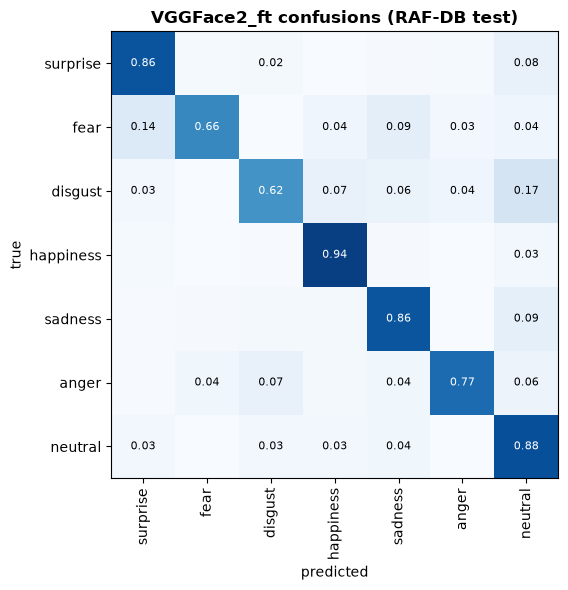

top confusions:
     disgust -> neutral    17.5%
        fear -> surprise   13.5%
        fear -> sadness    9.5%
     sadness -> neutral    9.2%
    surprise -> neutral    7.6%
     disgust -> happiness  7.5%
       anger -> disgust    7.4%
     disgust -> sadness    6.2%


In [1]:
# %%
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix

ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]
p  = np.load(ART/"preds_VGGFace2_ft.npy")
yt = np.load(ART/"ytest_RAFDB_112.npy")

cm = confusion_matrix(yt, p, labels=range(7), normalize="true")
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES, rotation=90)
ax.set_yticks(range(7)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(7):
    for j in range(7):
        if cm[i,j] > 0.02:
            ax.text(j,i,f"{cm[i,j]:.2f}",ha="center",va="center",fontsize=8,
                    color="white" if cm[i,j]>.5 else "black")
ax.set_title("VGGFace2_ft confusions (RAF-DB test)", weight="bold")
plt.tight_layout(); plt.show()

pairs = [(CLASSES[i], CLASSES[j], cm[i,j]) for i in range(7) for j in range(7) if i!=j]
print("top confusions:")
for a,b,v in sorted(pairs, key=lambda x:-x[2])[:8]:
    print(f"  {a:>10} -> {b:<10} {v:.1%}")

In [2]:
# %% [markdown]
# # Step 14 — Test-time augmentation
# Averages predictions over original + horizontal flip.

# %%
import numpy as np, torch, torch.nn as nn, json
from pathlib import Path
from PIL import Image
from torchvision import transforms
from facenet_pytorch import InceptionResnetV1
from sklearn.metrics import accuracy_score, f1_score, classification_report

RAF = Path.home()/"Documents/RAF_DB/DATASET"
ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]

class FERNet(nn.Module):
    def __init__(self, n=7):
        super().__init__()
        self.backbone = InceptionResnetV1(pretrained=None)
        self.head = nn.Sequential(
            nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,n))
    def forward(self,x): return self.head(self.backbone(x))

vgg = FERNet().to(DEV)
vgg.load_state_dict(torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV),
                    strict=False)
vgg.eval()

tf = transforms.Compose([transforms.Resize((160,160)), transforms.ToTensor(),
                         transforms.Normalize([0.5]*3,[0.5]*3)])

paths, yt = [], []
for i, _ in enumerate(CLASSES, start=1):
    for f in sorted((RAF/"test"/str(i)).glob("*.jpg")):
        paths.append(f); yt.append(i-1)
yt = np.array(yt)
print(f"test {len(yt):,}")

@torch.no_grad()
def predict(flip):
    out, B = [], 64
    for s in range(0, len(paths), B):
        batch = []
        for p in paths[s:s+B]:
            im = Image.open(p).convert("RGB")
            if flip: im = im.transpose(Image.FLIP_LEFT_RIGHT)
            batch.append(tf(im))
        x = torch.stack(batch).to(DEV)
        out.append(torch.softmax(vgg(x),1).cpu().numpy())
    return np.concatenate(out)

P0, P1 = predict(False), predict(True)

def score(p, name):
    a, f = accuracy_score(yt,p.argmax(1)), f1_score(yt,p.argmax(1),average="macro")
    print(f"{name:<22} acc {a:.4f}  macro-F1 {f:.4f}")
    return a, f

score(P0, "no TTA")
score((P0+P1)/2, "TTA arithmetic")
Pg = np.exp((np.log(np.clip(P0,1e-9,1))+np.log(np.clip(P1,1e-9,1)))/2)
score(Pg, "TTA geometric")

# ---- best TTA + ArcFace, geometric ----
arcp = np.load(ART/"probs_rafdb_test.npz")["ArcFace_mlp"]
best = max([((P0+P1)/2,"arith"), (Pg,"geo")],
           key=lambda t: f1_score(yt,t[0].argmax(1),average="macro"))
comb = np.exp((np.log(np.clip(best[0],1e-9,1))+np.log(np.clip(arcp,1e-9,1)))/2)
a,f = score(comb, f"TTA({best[1]}) + ArcFace")
print(f"{'previous best':<22} acc 0.8801  macro-F1 0.8251")

np.save(ART/"probs_VGGFace2_tta.npy", best[0])
print("\n", classification_report(yt, comb.argmax(1), target_names=CLASSES, digits=4))

/opt/miniconda3/envs/torch/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


test 3,068
no TTA                 acc 0.8722  macro-F1 0.8084
TTA arithmetic         acc 0.8726  macro-F1 0.8101
TTA geometric          acc 0.8726  macro-F1 0.8110
TTA(geo) + ArcFace     acc 0.8797  macro-F1 0.8260
previous best          acc 0.8801  macro-F1 0.8251

               precision    recall  f1-score   support

    surprise     0.8410    0.8359    0.8384       329
        fear     0.8182    0.7297    0.7714        74
     disgust     0.6846    0.6375    0.6602       160
   happiness     0.9669    0.9359    0.9511      1185
     sadness     0.8891    0.8556    0.8721       478
       anger     0.8375    0.8272    0.8323       162
     neutral     0.8116    0.9059    0.8562       680

    accuracy                         0.8797      3068
   macro avg     0.8355    0.8182    0.8260      3068
weighted avg     0.8817    0.8797    0.8799      3068



In [3]:
# %%
from pathlib import Path
from collections import Counter
import pandas as pd

ROOT = Path.home()/"Documents/AF_PLUS"
IMG = {".jpg",".jpeg",".png",".bmp"}

print("=== dirs (3 levels) ===")
for d in sorted(p for p in ROOT.rglob("*") if p.is_dir()):
    rel = d.relative_to(ROOT)
    if len(rel.parts) <= 3:
        n = sum(1 for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMG)
        print(f"{'  '*(len(rel.parts)-1)}{rel.name}/" + (f"  [{n:,} imgs]" if n else ""))

print("\n=== non-image files ===")
for f in sorted(ROOT.rglob("*")):
    if f.is_file() and f.suffix.lower() not in IMG:
        print(f"  {f.relative_to(ROOT)}  ({f.stat().st_size/1024:.1f} KB)")

imgs = [f for f in ROOT.rglob("*") if f.is_file() and f.suffix.lower() in IMG]
print(f"\ntotal images: {len(imgs):,}")
print("extensions:", Counter(f.suffix.lower() for f in imgs))

print("\n=== sample paths ===")
for f in imgs[:8]: print("  ", f.relative_to(ROOT))

print("\n=== dimensions (10 sampled) ===")
from PIL import Image
import random
for f in random.sample(imgs, min(10,len(imgs))):
    with Image.open(f) as im: print(f"  {f.name}: {im.size} {im.mode}")

print("\n=== label files ===")
for f in ROOT.rglob("*.csv"):
    df = pd.read_csv(f, nrows=5)
    print(f"\n{f.relative_to(ROOT)}  cols: {list(df.columns)}")
    print(df.head(3).to_string())

=== dirs (3 levels) ===
Test/
  Anger/  [1,718 imgs]
  Contempt/  [1,312 imgs]
  disgust/  [1,248 imgs]
  fear/  [1,664 imgs]
  happy/  [2,704 imgs]
  neutral/  [2,368 imgs]
  sad/  [1,584 imgs]
  surprise/  [1,920 imgs]
Train/
  anger/  [1,500 imgs]
  contempt/  [1,559 imgs]
  disgust/  [1,229 imgs]
  fear/  [1,512 imgs]
  happy/  [2,340 imgs]
  neutral/  [2,758 imgs]
  sad/  [3,091 imgs]
  surprise/  [2,119 imgs]

=== non-image files ===
  .DS_Store  (6.0 KB)
  labels.csv  (1489.3 KB)

total images: 30,626
extensions: Counter({'.jpg': 19916, '.png': 10710})

=== sample paths ===
   Test/happy/ffhq_2508.png
   Test/happy/ffhq_1001.png
   Test/happy/ffhq_1767.png
   Test/happy/ffhq_738.png
   Test/happy/ffhq_1773.png
   Test/happy/ffhq_1015.png
   Test/happy/ffhq_2534.png
   Test/happy/ffhq_704.png

=== dimensions (10 sampled) ===
  image0025209.jpg: (96, 96) RGB
  image0042493.jpg: (96, 96) RGB
  ffhq_2049.png: (96, 96) RGB
  image0013220.jpg: (96, 96) RGB
  image0030867.jpg: (96, 96)

In [4]:
# %%
import pandas as pd
from pathlib import Path
ROOT = Path.home()/"Documents/AF_PLUS"
df = pd.read_csv(ROOT/"labels.csv")
df["folder"] = df["pth"].str.split("/").str[0].str.lower()
df["label"]  = df["label"].str.lower()

agree = (df["folder"] == df["label"]).mean()
print(f"folder == csv label: {agree:.1%}  ({len(df):,} rows)")
print(f"\nrelFCs: min {df.relFCs.min():.3f}  median {df.relFCs.median():.3f}  max {df.relFCs.max():.3f}")
print("\ndisagreement pattern:")
print(pd.crosstab(df["folder"], df["label"]).to_string())

folder == csv label: 62.8%  (28,175 rows)

relFCs: min 0.516  median 0.809  max 0.900

disagreement pattern:
label     anger  contempt  disgust  fear  happy  neutral   sad  surprise
folder                                                                  
anger      1998        97      368   105     18      182   146       120
contempt    138      1842      118    20    228      244    53       114
disgust     262        37     1780    46     40       58    73        81
fear        143        17      167  1967     34       57   180       414
happy        29       520      281    26   3820       55    65       247
neutral     617       618      485   120     68     1798   673       735
sad         293        71      177   196     17      317  1729       134
surprise    128        42       96   563    111      150    76      2771


In [5]:
# %%
from pathlib import Path
from collections import Counter
import pandas as pd, random
from PIL import Image

ROOT = Path.home()/"Documents/affectnet"
IMG = {".jpg",".jpeg",".png",".bmp",".webp"}

print("=== dirs (3 levels) ===")
for d in sorted(p for p in ROOT.rglob("*") if p.is_dir()):
    rel = d.relative_to(ROOT)
    if len(rel.parts) <= 3:
        n = sum(1 for f in d.iterdir() if f.is_file() and f.suffix.lower() in IMG)
        print(f"{'  '*(len(rel.parts)-1)}{rel.name}/" + (f"  [{n:,} imgs]" if n else ""))

print("\n=== non-image files ===")
for f in sorted(ROOT.rglob("*")):
    if f.is_file() and f.suffix.lower() not in IMG:
        print(f"  {f.relative_to(ROOT)}  ({f.stat().st_size/1e6:.1f} MB)")

imgs = [f for f in ROOT.rglob("*") if f.is_file() and f.suffix.lower() in IMG]
print(f"\ntotal images: {len(imgs):,}")
print("extensions:", Counter(f.suffix.lower() for f in imgs))
print(f"disk size: {sum(f.stat().st_size for f in imgs)/1e9:.2f} GB")

print("\n=== sample paths ===")
for f in imgs[:8]: print("  ", f.relative_to(ROOT))

print("\n=== dimensions (15 sampled) ===")
dims = Counter()
for f in random.sample(imgs, min(15, len(imgs))):
    with Image.open(f) as im:
        dims[im.size] += 1
        print(f"  {f.name}: {im.size} {im.mode}")
print("  ->", dict(dims))

print("\n=== tabular files ===")
for f in list(ROOT.rglob("*.csv")) + list(ROOT.rglob("*.parquet")):
    try:
        df = pd.read_parquet(f) if f.suffix == ".parquet" else pd.read_csv(f, nrows=2000)
        print(f"\n{f.relative_to(ROOT)}")
        print(f"  cols: {list(df.columns)}")
        print(df.head(3).to_string())
    except Exception as e:
        print(f"\n{f.relative_to(ROOT)}  -> {type(e).__name__}: {e}")

=== dirs (3 levels) ===
anger/  [3,638 imgs]
contempt/  [3,179 imgs]
disgust/  [2,660 imgs]
fear/  [3,622 imgs]
happy/  [5,045 imgs]
neutral/  [5,132 imgs]
sad/  [3,430 imgs]
surprise/  [4,296 imgs]

=== non-image files ===
  labels.csv  (1.0 MB)

total images: 31,002
extensions: Counter({'.jpg': 20292, '.png': 10710})
disk size: 8.73 GB

=== sample paths ===
   happy/ffhq_2508.png
   happy/ffhq_3616.png
   happy/ffhq_4179.png
   happy/ffhq_1001.png
   happy/ffhq_1767.png
   happy/ffhq_3170.png
   happy/ffhq_738.png
   happy/ffhq_3164.png

=== dimensions (15 sampled) ===
  image0034971.jpg: (728, 728) RGB
  image0018076.jpg: (1120, 1120) RGB
  ffhq_4694.png: (512, 512) RGB
  image0010019.jpg: (535, 535) RGB
  ffhq_431.png: (512, 512) RGB
  image0009317.jpg: (2050, 2050) RGB
  image0018419.jpg: (627, 627) RGB
  image0030341.jpg: (1633, 1633) RGB
  image0017540.jpg: (419, 419) RGB
  image0030868.jpg: (940, 940) RGB
  image0037910.jpg: (579, 579) RGB
  ffhq_5353.png: (512, 512) RGB
  imag

In [6]:
# %%
import pandas as pd, numpy as np
from pathlib import Path

ROOT = Path.home()/"Documents/affectnet"
df = pd.read_csv(ROOT/"labels.csv")
df["folder"] = df["pth"].str.split("/").str[0].str.lower()
df["label"]  = df["label"].str.lower()
df["src"]    = np.where(df["pth"].str.contains("ffhq"), "ffhq", "affectnet")
df["agree"]  = df["folder"] == df["label"]

print(f"rows {len(df):,}   overall agreement {df.agree.mean():.1%}\n")
print("agreement by source:")
print(df.groupby("src")["agree"].agg(["count","mean"]).to_string())

print("\nagreement by folder:")
t = df.groupby("folder")["agree"].agg(["count","sum","mean"])
t.columns = ["total","agreeing","rate"]
print(t.sort_values("rate", ascending=False).to_string())

print("\n--- if we keep ONLY agreeing rows ---")
keep = df[df.agree]
print(f"{len(keep):,} images ({len(keep)/len(df):.1%})")
print(keep.groupby("label").size().sort_values(ascending=False).to_string())
print(f"\nimbalance {keep.groupby('label').size().max()/keep.groupby('label').size().min():.1f}:1")
print("\nby source in the kept set:")
print(keep.groupby("src").size().to_string())

rows 31,002   overall agreement 63.3%

agreement by source:
           count      mean
src                       
affectnet  20292  0.668638
ffhq       10710  0.565546

agreement by folder:
          total  agreeing      rate
folder                             
happy      5045      3821  0.757384
disgust    2660      1989  0.747744
surprise   4296      2970  0.691341
fear       3622      2502  0.690779
contempt   3179      2134  0.671280
anger      3638      2398  0.659153
sad        3430      2008  0.585423
neutral    5132      1803  0.351325

--- if we keep ONLY agreeing rows ---
19,625 images (63.3%)
label
happy       3821
surprise    2970
fear        2502
anger       2398
contempt    2134
sad         2008
disgust     1989
neutral     1803

imbalance 2.1:1

by source in the kept set:
src
affectnet    13568
ffhq          6057


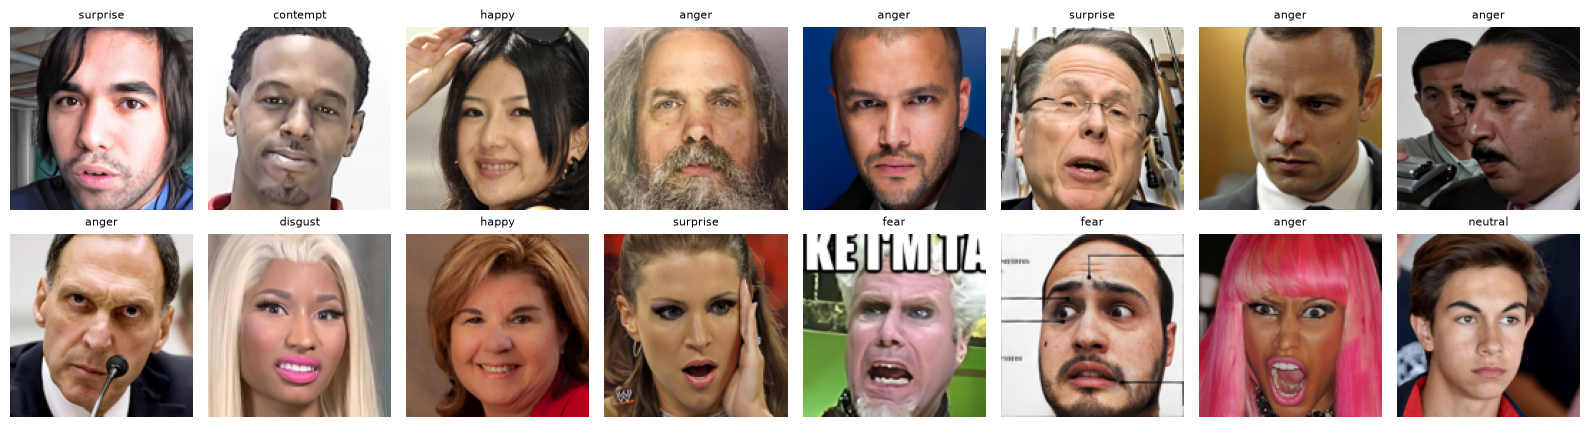

In [7]:
# %%
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

ROOT = Path.home()/"Documents/affectnet"
df = pd.read_csv(ROOT/"labels.csv")
df["folder"] = df["pth"].str.split("/").str[0].str.lower()
df["label"] = df["label"].str.lower()
keep = df[df.folder == df.label].reset_index(drop=True)

s = keep.sample(16, random_state=0)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, (_, r) in zip(axes.ravel(), s.iterrows()):
    ax.imshow(Image.open(ROOT/r["pth"]).convert("RGB").resize((128,128)))
    ax.axis("off"); ax.set_title(r["label"], fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
# %%
import numpy as np, pandas as pd, json, time, os
from pathlib import Path
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from facenet_pytorch import InceptionResnetV1
from sklearn.metrics import accuracy_score, f1_score, classification_report

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
AFF = Path.home()/"Documents/affectnet"
RAF = Path.home()/"Documents/RAF_DB/DATASET"
ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]
AFF2UNI = {"surprise":0,"fear":1,"disgust":2,"happy":3,"sad":4,"anger":5,"neutral":6}
IMG, BATCH = 160, 48
ADD_RAFDB = True          # train on AffectNet + RAF-DB train, or AffectNet alone

# ---- AffectNet, agreement-filtered, contempt dropped ------------------
df = pd.read_csv(AFF/"labels.csv")
df["folder"] = df["pth"].str.split("/").str[0].str.lower()
df["label"]  = df["label"].str.lower()
df = df[(df.folder == df.label) & (df.label != "contempt")]
aff = pd.DataFrame({"path": [str(AFF/p) for p in df["pth"]],
                    "y": [AFF2UNI[l] for l in df["label"]]})
print(f"AffectNet filtered: {len(aff):,}")

# ---- RAF-DB ------------------------------------------------------------
def raf(split):
    return pd.DataFrame([{"path": str(f), "y": i-1}
        for i,_ in enumerate(CLASSES, start=1)
        for f in sorted((RAF/split/str(i)).glob("*.jpg"))])
raf_tr, raf_te = raf("train"), raf("test")

train_df = pd.concat([aff, raf_tr]).reset_index(drop=True) if ADD_RAFDB else aff
print(f"train {len(train_df):,}  test {len(raf_te):,} (RAF-DB)")
print(train_df["y"].value_counts().sort_index()
        .rename(lambda i: CLASSES[i]).to_string())

# ---- data --------------------------------------------------------------
tf_tr = transforms.Compose([
    transforms.Resize((IMG,IMG)), transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(10, translate=(0.06,0.06), scale=(0.9,1.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(), transforms.Normalize([0.5]*3,[0.5]*3),
    transforms.RandomErasing(p=0.25, scale=(0.02,0.12))])
tf_ev = transforms.Compose([transforms.Resize((IMG,IMG)), transforms.ToTensor(),
                            transforms.Normalize([0.5]*3,[0.5]*3)])

class DS(Dataset):
    def __init__(s, df, tf): s.df, s.tf = df.reset_index(drop=True), tf
    def __len__(s): return len(s.df)
    def __getitem__(s, i):
        r = s.df.iloc[i]
        return s.tf(Image.open(r["path"]).convert("RGB")), int(r["y"])

dl_tr = DataLoader(DS(train_df, tf_tr), batch_size=BATCH, shuffle=True, num_workers=0)
dl_te = DataLoader(DS(raf_te,  tf_ev), batch_size=BATCH, shuffle=False, num_workers=0)

cnt = np.bincount(train_df["y"], minlength=7)
CW = torch.tensor(np.sqrt(cnt.sum()/(7*cnt)), dtype=torch.float32, device=DEV)
print("weights:", {CLASSES[i]: round(float(x),3) for i,x in enumerate(CW.cpu())})

# ---- model (start from your fine-tuned checkpoint) --------------------
class FERNet(nn.Module):
    def __init__(s, n=7):
        super().__init__()
        s.backbone = InceptionResnetV1(pretrained=None)
        s.head = nn.Sequential(nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,n))
    def forward(s,x): return s.head(s.backbone(x))

model = FERNet().to(DEV)
model.load_state_dict(torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV),
                      strict=False)
for p in model.backbone.parameters(): p.requires_grad = False
for n_,p in model.backbone.named_parameters():
    if any(k in n_ for k in ["repeat_3","block8","mixed_7a","last_linear","last_bn"]):
        p.requires_grad = True

crit = nn.CrossEntropyLoss(weight=CW, label_smoothing=0.05)
opt  = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                          lr=1e-4, weight_decay=1e-4)
EPOCHS = 30
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

def evaluate():
    model.eval(); P=[]
    with torch.no_grad():
        for x,_ in dl_te: P.append(model(x.to(DEV)).argmax(1).cpu().numpy())
    P = np.concatenate(P); y = raf_te["y"].values
    return accuracy_score(y,P), f1_score(y,P,average="macro"), P

best_f1, best_state, bad = -1, None, 0
for ep in range(EPOCHS):
    model.train(); tot, t0 = 0.0, time.time()
    for x,y in dl_tr:
        x,y = x.to(DEV), y.to(DEV)
        opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step()
        tot += loss.item()*len(y)
    sched.step()
    acc, f1, _ = evaluate()
    flag = ""
    if f1 > best_f1:
        best_f1, bad = f1, 0
        best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        flag = " *best*"
    else: bad += 1
    print(f"ep {ep+1:>2}/{EPOCHS} loss {tot/len(train_df):.4f} acc {acc:.4f} "
          f"macroF1 {f1:.4f} ({time.time()-t0:.0f}s){flag}", flush=True)
    if bad >= 8: print("early stop"); break

model.load_state_dict(best_state)
acc, f1, P = evaluate()
model.eval(); pr=[]
with torch.no_grad():
    for x,_ in dl_te: pr.append(torch.softmax(model(x.to(DEV)),1).cpu().numpy())
pr = np.concatenate(pr)

tag = "AffNet_RAFDB" if ADD_RAFDB else "AffNet_only"
torch.save(model.state_dict(), ART/"models"/f"{tag}.pt")
np.save(ART/f"probs_{tag}.npy", pr); np.save(ART/f"preds_{tag}.npy", P)
res = {"tag":tag,"n_train":int(len(train_df)),"acc":round(float(acc),4),
       "macro_f1":round(float(f1),4),
       "per_class":{c:round(float(v),4) for c,v in
            zip(CLASSES, f1_score(raf_te["y"],P,average=None,labels=range(7)))}}
json.dump(res, open(ART/f"result_{tag}.json","w"), indent=2)
print(json.dumps(res, indent=2))
print("\nVGGFace2_ft alone: acc 0.8722  macro-F1 0.8084")
print("best ensemble    : acc 0.8801  macro-F1 0.8251")
print("\n", classification_report(raf_te["y"], P, target_names=CLASSES, digits=4))

AffectNet filtered: 17,491
train 29,762  test 3,068 (RAF-DB)
y
surprise     4260
fear         2783
disgust      2706
happiness    8593
sadness      3990
anger        3103
neutral      4327
weights: {'surprise': 0.999, 'fear': 1.236, 'disgust': 1.253, 'happiness': 0.703, 'sadness': 1.032, 'anger': 1.171, 'neutral': 0.991}
ep  1/30 loss 0.7456 acc 0.8481 macroF1 0.7866 (239s) *best*
ep  2/30 loss 0.6269 acc 0.7771 macroF1 0.7072 (228s)
ep  3/30 loss 0.5818 acc 0.8005 macroF1 0.6986 (229s)
ep  4/30 loss 0.5628 acc 0.8481 macroF1 0.7795 (227s)
ep  5/30 loss 0.5351 acc 0.7748 macroF1 0.7004 (241s)
ep  6/30 loss 0.5140 acc 0.8048 macroF1 0.7333 (232s)
ep  7/30 loss 0.4969 acc 0.7976 macroF1 0.7207 (221s)
ep  8/30 loss 0.4821 acc 0.8468 macroF1 0.7748 (225s)
ep  9/30 loss 0.4664 acc 0.8615 macroF1 0.7933 (225s) *best*
ep 10/30 loss 0.4549 acc 0.8739 macroF1 0.8110 (215s) *best*
ep 11/30 loss 0.4328 acc 0.8631 macroF1 0.7894 (215s)
ep 12/30 loss 0.4262 acc 0.8576 macroF1 0.7806 (215s)
ep 13/30

In [9]:
# %%
import numpy as np, json
from pathlib import Path
from itertools import combinations
from sklearn.metrics import accuracy_score, f1_score, classification_report

ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]

PROBS = {k: v for k, v in np.load(ART/"probs_rafdb_test.npz").items()}
for t in ["VGGFace2_ft", "AffNet_RAFDB"]:
    f = ART/f"probs_{t}.npy"
    if f.exists(): PROBS[t] = np.load(f)

yt = np.load(ART/"ytest_RAFDB_112.npy")
assert all(p.shape == (len(yt), 7) for p in PROBS.values()), "shape mismatch"
print(f"{len(PROBS)} members, {len(yt):,} test images\n")

def geo(ms):
    s = np.stack([PROBS[m] for m in ms])
    return np.exp(np.log(np.clip(s, 1e-9, 1)).mean(0)).argmax(1)

def sc(p): return accuracy_score(yt, p), f1_score(yt, p, average="macro")

print("individual:")
for t, pr in PROBS.items():
    a, f = sc(pr.argmax(1)); print(f"  {t:<22} acc {a:.4f}  macro-F1 {f:.4f}")

# every subset of size >= 2
rows = []
names = list(PROBS)
for r in range(2, len(names)+1):
    for c in combinations(names, r):
        a, f = sc(geo(c)); rows.append((f, a, c))
rows.sort(reverse=True)

print("\ntop 10 subsets (geometric):")
for f, a, m in rows[:10]:
    print(f"  acc {a:.4f}  macro-F1 {f:.4f}   {' + '.join(m)}")

bf, ba, bm = rows[0]
print(f"\nBEST: {' + '.join(bm)}")
print(f"  acc {ba:.4f}  macro-F1 {bf:.4f}")
print(f"  previous best (VGGFace2_ft + ArcFace): acc 0.8801  macro-F1 0.8251")

p = geo(bm)
np.save(ART/"preds_ENSEMBLE_v3.npy", p)
json.dump({"members": list(bm), "acc": round(float(ba),4),
           "macro_f1": round(float(bf),4),
           "per_class": {c: round(float(v),4) for c,v in
                zip(CLASSES, f1_score(yt,p,average=None,labels=range(7)))}},
          open(ART/"result_ensemble_v3.json","w"), indent=2)
print("\n", classification_report(yt, p, target_names=CLASSES, digits=4))

6 members, 3,068 test images

individual:
  RAFDB_112              acc 0.7565  macro-F1 0.6586
  RAFDB_96_fromFERPlus   acc 0.7415  macro-F1 0.6417
  Merged_96_gray         acc 0.7181  macro-F1 0.6256
  ArcFace_mlp            acc 0.7396  macro-F1 0.6436
  VGGFace2_ft            acc 0.8722  macro-F1 0.8084
  AffNet_RAFDB           acc 0.8739  macro-F1 0.8110

top 10 subsets (geometric):
  acc 0.8889  macro-F1 0.8380   VGGFace2_ft + AffNet_RAFDB
  acc 0.8885  macro-F1 0.8379   ArcFace_mlp + VGGFace2_ft + AffNet_RAFDB
  acc 0.8928  macro-F1 0.8378   RAFDB_96_fromFERPlus + ArcFace_mlp + VGGFace2_ft + AffNet_RAFDB
  acc 0.8905  macro-F1 0.8360   RAFDB_96_fromFERPlus + VGGFace2_ft + AffNet_RAFDB
  acc 0.8892  macro-F1 0.8347   RAFDB_112 + ArcFace_mlp + VGGFace2_ft + AffNet_RAFDB
  acc 0.8872  macro-F1 0.8285   RAFDB_112 + VGGFace2_ft + AffNet_RAFDB
  acc 0.8879  macro-F1 0.8265   Merged_96_gray + ArcFace_mlp + VGGFace2_ft + AffNet_RAFDB
  acc 0.8862  macro-F1 0.8260   Merged_96_gray + VGGFac

In [10]:
# %%
from pathlib import Path
from collections import Counter
import random

ROOT = Path.home()/"Documents/ABAW 7"
IMG = {".jpg",".jpeg",".png",".bmp"}
VID = {".mp4",".avi",".mkv",".mov"}

print("=== dirs (4 levels) ===")
shown = 0
for d in sorted(p for p in ROOT.rglob("*") if p.is_dir()):
    rel = d.relative_to(ROOT)
    if len(rel.parts) > 4: continue
    kids = list(d.iterdir())
    n_img = sum(1 for f in kids if f.is_file() and f.suffix.lower() in IMG)
    n_sub = sum(1 for f in kids if f.is_dir())
    tag = []
    if n_img: tag.append(f"{n_img:,} imgs")
    if n_sub: tag.append(f"{n_sub:,} subdirs")
    print(f"{'  '*(len(rel.parts)-1)}{rel.name}/" + (f"  [{', '.join(tag)}]" if tag else ""))
    shown += 1
    if shown > 120: print("  ... (truncated)"); break

allf = [f for f in ROOT.rglob("*") if f.is_file()]
print(f"\ntotal files: {len(allf):,}")
print("extensions:", Counter(f.suffix.lower() for f in allf).most_common(12))
print(f"disk size: {sum(f.stat().st_size for f in allf)/1e9:.2f} GB")

imgs = [f for f in allf if f.suffix.lower() in IMG]
vids = [f for f in allf if f.suffix.lower() in VID]
print(f"images: {len(imgs):,}   videos: {len(vids):,}")

if imgs:
    from PIL import Image
    print("\n=== image dims (10 sampled) ===")
    for f in random.sample(imgs, min(10, len(imgs))):
        with Image.open(f) as im: print(f"  {f.relative_to(ROOT)}: {im.size} {im.mode}")

if vids:
    print("\n=== sample videos ===")
    for f in vids[:6]:
        print(f"  {f.relative_to(ROOT)}  ({f.stat().st_size/1e6:.1f} MB)")

print("\n=== annotation files (txt/csv) ===")
anns = [f for f in allf if f.suffix.lower() in {".txt",".csv"}]
print(f"count: {len(anns):,}")
for f in anns[:5]:
    print(f"\n--- {f.relative_to(ROOT)} ({f.stat().st_size/1024:.1f} KB)")
    try:
        with open(f) as fh:
            for i, line in enumerate(fh):
                print("   ", line.rstrip()[:140])
                if i >= 5: break
    except Exception as e:
        print("    unreadable:", e)

=== dirs (4 levels) ===
cropped_aligned/  [307 subdirs]
  1-30-1280x720/  [363 imgs]
  10-60-1280x720/  [428 imgs]
  10-60-1280x720_right/  [138 imgs]
  100-29-1080x1920/  [311 imgs]
  101-30-1080x1920/  [722 imgs]
  102/  [324 imgs]
  102-30-640x360/  [69 imgs]
  103/  [3,188 imgs]
  103-30-384x480/  [113 imgs]
  104-17-720x480/  [248 imgs]
  105/  [973 imgs]
  105-30-1280x720/  [321 imgs]
  106/  [971 imgs]
  106-30-720x1280/  [3 imgs]
  107/  [691 imgs]
  107-30-640x480/  [5 imgs]
  108/  [13 imgs]
  11-24-1920x1080/  [806 imgs]
  110/  [261 imgs]
  110-30-270x480/  [782 imgs]
  111/  [369 imgs]
  111-25-1920x1080/  [176 imgs]
  112/  [285 imgs]
  112-30-640x360/  [158 imgs]
  113/  [979 imgs]
  113-60-1280x720/  [389 imgs]
  114/  [189 imgs]
  114-30-1280x720/  [627 imgs]
  115-30-1280x720/  [582 imgs]
  116/  [234 imgs]
  116-30-1280x720/  [548 imgs]
  117/  [406 imgs]
  117-25-1920x1080/  [574 imgs]
  118/  [20 imgs]
  118-30-640x480/  [125 imgs]
  119/  [884 imgs]
  12-24-1920x1

In [11]:
# %%
import requests, zipfile, io
from pathlib import Path

DEST = Path.home()/"Documents/RAVDESS"; DEST.mkdir(exist_ok=True)
r = requests.get("https://zenodo.org/api/records/1188976", timeout=60).json()
files = r["files"]

print(f"{len(files)} files available:\n")
for f in files:
    print(f"  {f['key']:<42} {f['size']/1e6:>8.1f} MB")

49 files available:

  Video_Speech_Actor_06.zip                     568.5 MB
  Video_Speech_Actor_09.zip                     523.5 MB
  Video_Song_Actor_05.zip                       529.8 MB
  Video_Song_Actor_22.zip                       546.9 MB
  Video_Song_Actor_11.zip                       482.1 MB
  Video_Speech_Actor_05.zip                     563.0 MB
  Video_Speech_Actor_04.zip                     546.6 MB
  Video_Song_Actor_24.zip                       528.6 MB
  Video_Speech_Actor_01.zip                     553.0 MB
  Video_Speech_Actor_08.zip                     562.6 MB
  Video_Speech_Actor_07.zip                     565.7 MB
  Video_Speech_Actor_13.zip                     501.9 MB
  Video_Speech_Actor_12.zip                     557.9 MB
  Video_Speech_Actor_11.zip                     518.6 MB
  Audio_Song_Actors_01-24.zip                   225.5 MB
  Audio_Speech_Actors_01-24.zip                 208.5 MB
  Video_Song_Actor_01.zip                       502.5 MB
  Video_So

In [13]:
# %%
WANT = "Video_Speech_Actor_"     # video only; add "Video_Song_Actor_" for song too

todo = [f for f in files if f["key"].startswith(WANT)]
print(f"downloading {len(todo)} archives, "
      f"{sum(f['size'] for f in todo)/1e9:.1f} GB\n")

for i, f in enumerate(todo, 1):
    out = DEST/f["key"].replace(".zip","")
    if out.exists():
        print(f"[{i}/{len(todo)}] {f['key']} — already extracted"); continue
    print(f"[{i}/{len(todo)}] {f['key']}  ({f['size']/1e6:.0f} MB)", flush=True)
    resp = requests.get(f["links"]["self"], timeout=600)
    resp.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(resp.content)) as z:
        z.extractall(DEST)

mp4s = list(DEST.rglob("*.mp4"))
print(f"\ndone — {len(mp4s):,} videos")
if mp4s:
    print("sample:", mp4s[0].relative_to(DEST))

downloading 24 archives, 13.4 GB

[1/24] Video_Speech_Actor_06.zip  (569 MB)
[2/24] Video_Speech_Actor_09.zip  (523 MB)
[3/24] Video_Speech_Actor_05.zip  (563 MB)
[4/24] Video_Speech_Actor_04.zip  (547 MB)
[5/24] Video_Speech_Actor_01.zip  (553 MB)
[6/24] Video_Speech_Actor_08.zip  (563 MB)
[7/24] Video_Speech_Actor_07.zip  (566 MB)
[8/24] Video_Speech_Actor_13.zip  (502 MB)
[9/24] Video_Speech_Actor_12.zip  (558 MB)
[10/24] Video_Speech_Actor_11.zip  (519 MB)
[11/24] Video_Speech_Actor_03.zip  (568 MB)
[12/24] Video_Speech_Actor_18.zip  (566 MB)
[13/24] Video_Speech_Actor_17.zip  (552 MB)
[14/24] Video_Speech_Actor_16.zip  (562 MB)
[15/24] Video_Speech_Actor_24.zip  (596 MB)
[16/24] Video_Speech_Actor_23.zip  (545 MB)
[17/24] Video_Speech_Actor_22.zip  (561 MB)
[18/24] Video_Speech_Actor_15.zip  (525 MB)
[19/24] Video_Speech_Actor_14.zip  (552 MB)
[20/24] Video_Speech_Actor_10.zip  (566 MB)
[21/24] Video_Speech_Actor_02.zip  (571 MB)
[22/24] Video_Speech_Actor_21.zip  (590 MB)
[23/24]

In [14]:
# %% [markdown]
# # Step 16 — RAVDESS feature extraction (run once)
# Per clip: detect the face once, crop all frames, encode with the VGGFace2_ft
# backbone. Saves (T, 512) embeddings + (T, 7) per-frame probabilities.
# Afterwards temporal models train on vectors — seconds per epoch, not hours.

# %%
import cv2, numpy as np, pandas as pd, torch, torch.nn as nn, time, os
from pathlib import Path
from PIL import Image
from torchvision import transforms
from facenet_pytorch import InceptionResnetV1
from insightface.app import FaceAnalysis

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
RAV  = Path.home()/"Documents/RAVDESS"
ART  = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
FEAT = ART/"ravdess_feat"; FEAT.mkdir(parents=True, exist_ok=True)
DEV  = "mps" if torch.backends.mps.is_available() else "cpu"

FRAME_STRIDE  = 2      # 30fps -> 15fps; adjacent frames are near-identical
DETECT_PROBES = 5      # detections per clip (actor is seated, camera static)
BATCH         = 64

RAV_EMO = {1:"neutral",2:"calm",3:"happy",4:"sad",
           5:"angry",6:"fearful",7:"disgust",8:"surprised"}
CLASSES = ["surprise","fear","disgust","happiness","sadness","anger","neutral"]

# %%
# ---- manifest from filenames -------------------------------------------
rows = []
for f in sorted(RAV.rglob("*.mp4")):
    p = f.stem.split("-")
    if len(p) != 7 or p[0] != "01":        # 01 = full audio-video only
        continue
    rows.append({"path": str(f), "clip": f.stem,
                 "emotion": RAV_EMO[int(p[2])], "intensity": int(p[3]),
                 "statement": int(p[4]), "rep": int(p[5]), "actor": int(p[6])})
man = pd.DataFrame(rows)
print(f"{len(man)} clips  |  {man.actor.nunique()} actors")

print("\nclips per emotion:")
print(man.groupby("emotion").size().sort_values(ascending=False).to_string())
print("\nby intensity (1=normal, 2=strong):")
print(man.groupby(["emotion","intensity"]).size().unstack(fill_value=0).to_string())

# %%
# ---- models -------------------------------------------------------------
class FERNet(nn.Module):
    def __init__(s, n=7):
        super().__init__()
        s.backbone = InceptionResnetV1(pretrained=None)
        s.head = nn.Sequential(nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,n))
    def forward(s,x): return s.head(s.backbone(x))

model = FERNet().to(DEV)
model.load_state_dict(torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV),
                      strict=False)
model.eval()

app = FaceAnalysis(name="buffalo_l",
                   providers=["CoreMLExecutionProvider","CPUExecutionProvider"])
app.prepare(ctx_id=-1, det_size=(320,320))

tf = transforms.Compose([transforms.Resize((160,160)), transforms.ToTensor(),
                          transforms.Normalize([0.5]*3,[0.5]*3)])

# %%
def clip_bbox(path, n_probes=DETECT_PROBES, pad=0.18):
    """Detect on a few spread frames; return one padded box for the whole clip."""
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) or 1
    boxes = []
    for i in np.linspace(0, max(total-1,0), n_probes, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, fr = cap.read()
        if not ok: continue
        fs = app.get(fr)
        if fs:
            b = max(fs, key=lambda a:(a.bbox[2]-a.bbox[0])*(a.bbox[3]-a.bbox[1])).bbox
            boxes.append(b)
    H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    cap.release()
    if not boxes: return None, total
    b = np.median(np.stack(boxes), 0)
    w, h = b[2]-b[0], b[3]-b[1]
    x1 = max(int(b[0]-pad*w), 0); y1 = max(int(b[1]-pad*h), 0)
    x2 = min(int(b[2]+pad*w), W); y2 = min(int(b[3]+pad*h), H)
    return (x1,y1,x2,y2), total

@torch.no_grad()
def encode(path, box):
    """Decode, crop, batch through the backbone. Returns (T,512), (T,7)."""
    x1,y1,x2,y2 = box
    cap = cv2.VideoCapture(str(path))
    tensors, i = [], 0
    while True:
        ok, fr = cap.read()
        if not ok: break
        if i % FRAME_STRIDE == 0:
            crop = fr[y1:y2, x1:x2]
            if crop.size:
                tensors.append(tf(Image.fromarray(
                    cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))))
        i += 1
    cap.release()
    if not tensors: return None, None

    embs, prbs = [], []
    for s in range(0, len(tensors), BATCH):
        x = torch.stack(tensors[s:s+BATCH]).to(DEV)
        e = model.backbone(x)
        p = torch.softmax(model.head(e), 1)
        embs.append(e.cpu().numpy()); prbs.append(p.cpu().numpy())
    return np.vstack(embs).astype("float32"), np.vstack(prbs).astype("float32")

# %%
# ---- run ----------------------------------------------------------------
t0, ok_n, fail, lengths = time.time(), 0, [], []
for _, r in man.iterrows():
    out = FEAT/f"{r['clip']}.npz"
    if out.exists():
        ok_n += 1; continue
    box, _ = clip_bbox(r["path"])
    if box is None:
        fail.append(r["clip"]); continue
    emb, prb = encode(r["path"], box)
    if emb is None:
        fail.append(r["clip"]); continue
    np.savez_compressed(out, emb=emb, probs=prb)
    lengths.append(len(emb)); ok_n += 1
    if ok_n % 50 == 0:
        el = time.time()-t0
        print(f"  {ok_n}/{len(man)}  {el/60:.1f} min elapsed  "
              f"~{el/max(ok_n,1)*(len(man)-ok_n)/60:.0f} min left", flush=True)

print(f"\ndone: {ok_n} clips, {len(fail)} failed, {(time.time()-t0)/60:.1f} min")
if fail: print("failed:", fail[:10])
if lengths:
    print(f"frames/clip: min {min(lengths)}  median {int(np.median(lengths))}  max {max(lengths)}")

man["feat"] = man["clip"].apply(lambda c: str(FEAT/f"{c}.npz"))
man = man[man["feat"].apply(lambda p: Path(p).exists())]
man.to_csv(ART/"ravdess_manifest.csv", index=False)

size = sum(f.stat().st_size for f in FEAT.glob("*.npz"))/1e6
print(f"\nmanifest: {len(man)} clips -> {ART/'ravdess_manifest.csv'}")
print(f"features: {size:.0f} MB in {FEAT}")

# %%
# ---- baseline: frame-averaged predictions from the existing model -------
RAV2UNI = {"surprised":0,"fearful":1,"disgust":2,"happy":3,
           "sad":4,"angry":5,"neutral":6}
sub = man[man.emotion.isin(RAV2UNI)]
y, yhat = [], []
for _, r in sub.iterrows():
    p = np.load(r["feat"])["probs"].mean(0)
    y.append(RAV2UNI[r["emotion"]]); yhat.append(int(p.argmax()))

from sklearn.metrics import accuracy_score, f1_score, classification_report
print(f"\nframe-averaged baseline on RAVDESS ({len(y)} clips, calm excluded):")
print(f"  acc {accuracy_score(y,yhat):.4f}  macro-F1 {f1_score(y,yhat,average='macro'):.4f}")
print("\n", classification_report(y, yhat, target_names=CLASSES, digits=3))

# where does 'calm' land under the current 7-class model?
calm = man[man.emotion == "calm"]
if len(calm):
    votes = np.zeros(7)
    for _, r in calm.iterrows():
        votes[int(np.load(r["feat"])["probs"].mean(0).argmax())] += 1
    print(f"\n'calm' clips ({len(calm)}) predicted as:")
    for i in votes.argsort()[::-1]:
        if votes[i]: print(f"  {CLASSES[i]:<10} {int(votes[i]):>4}  ({votes[i]/len(calm):.1%})")

1440 clips  |  24 actors

clips per emotion:
emotion
angry        192
calm         192
disgust      192
fearful      192
happy        192
sad          192
surprised    192
neutral       96

by intensity (1=normal, 2=strong):
intensity   1   2
emotion          
angry      96  96
calm       96  96
disgust    96  96
fearful    96  96
happy      96  96
neutral    96   0
sad        96  96
surprised  96  96
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CoreMLExecutionProvider': {}}
find model: /path/to/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CoreMLExecutionProvider': {}}
find model: /path/to/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options

/opt/miniconda3/envs/torch/lib/python3.12/site-packages/insightface/utils/face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


  50/1440  0.7 min elapsed  ~21 min left
  100/1440  1.4 min elapsed  ~18 min left
  150/1440  2.0 min elapsed  ~17 min left
  200/1440  2.5 min elapsed  ~16 min left
  250/1440  3.2 min elapsed  ~15 min left
  300/1440  3.8 min elapsed  ~15 min left
  350/1440  4.4 min elapsed  ~14 min left
  400/1440  5.0 min elapsed  ~13 min left
  450/1440  5.6 min elapsed  ~12 min left
  500/1440  6.2 min elapsed  ~12 min left
  550/1440  6.7 min elapsed  ~11 min left
  600/1440  7.3 min elapsed  ~10 min left
  650/1440  7.9 min elapsed  ~10 min left
  700/1440  8.6 min elapsed  ~9 min left
  750/1440  9.1 min elapsed  ~8 min left
  800/1440  9.7 min elapsed  ~8 min left
  850/1440  10.2 min elapsed  ~7 min left
  900/1440  10.8 min elapsed  ~6 min left
  950/1440  11.4 min elapsed  ~6 min left
  1000/1440  11.9 min elapsed  ~5 min left
  1050/1440  12.6 min elapsed  ~5 min left
  1100/1440  13.2 min elapsed  ~4 min left
  1150/1440  13.8 min elapsed  ~3 min left
  1200/1440  14.4 min elapsed  ~3 

In [15]:
# %% [markdown]
# # Step 17 — Temporal models on RAVDESS
# Sequence models over cached (T,512) frame embeddings.
# Actor-grouped 4-fold CV — the same person never appears in train and test.
# Baseline to beat: frame-averaged single-frame model = 0.4295 acc / 0.3765 macro-F1

# %%
import numpy as np, pandas as pd, json, time, os
from pathlib import Path
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

INCLUDE_CALM = True
MAXLEN, BATCH, EPOCHS, PATIENCE = 64, 32, 80, 15

man = pd.read_csv(ART/"ravdess_manifest.csv")
CLASSES = sorted(man.emotion.unique()) if INCLUDE_CALM else \
          sorted(c for c in man.emotion.unique() if c != "calm")
if not INCLUDE_CALM: man = man[man.emotion != "calm"]
C2I = {c:i for i,c in enumerate(CLASSES)}
man["y"] = man.emotion.map(C2I)
print(f"{len(man)} clips | {len(CLASSES)} classes: {CLASSES}")

# ---- load all sequences into RAM (154 MB) ------------------------------
SEQ, Y, ACT = [], [], []
for _, r in man.iterrows():
    e = np.load(r["feat"])["emb"]
    e = e / (np.linalg.norm(e, axis=1, keepdims=True) + 1e-8)   # L2 per frame
    SEQ.append(e.astype("float32")); Y.append(r["y"]); ACT.append(r["actor"])
Y, ACT = np.array(Y), np.array(ACT)
print(f"loaded | median length {int(np.median([len(s) for s in SEQ]))}")

def pad(seq, L=MAXLEN):
    """Uniformly resample to L frames — keeps the whole trajectory shape."""
    idx = np.linspace(0, len(seq)-1, L).astype(int)
    return seq[idx]

X = np.stack([pad(s) for s in SEQ])        # (N, L, 512)
print("X:", X.shape)

# %%
# ---- models -------------------------------------------------------------
class BiLSTM(nn.Module):
    def __init__(s, n, d=512, h=256):
        super().__init__()
        s.proj = nn.Sequential(nn.Linear(d,256), nn.LayerNorm(256), nn.GELU(), nn.Dropout(0.3))
        s.rnn  = nn.LSTM(256, h, num_layers=2, batch_first=True,
                         bidirectional=True, dropout=0.3)
        s.att  = nn.Linear(2*h, 1)
        s.head = nn.Sequential(nn.LayerNorm(2*h), nn.Dropout(0.4), nn.Linear(2*h, n))
    def forward(s, x):
        x, _ = s.rnn(s.proj(x))
        w = torch.softmax(s.att(x), 1)          # attention pool over time
        return s.head((x*w).sum(1))

class TemporalTransformer(nn.Module):
    def __init__(s, n, d=512, dm=256, layers=3, heads=8):
        super().__init__()
        s.proj = nn.Sequential(nn.Linear(d,dm), nn.LayerNorm(dm))
        s.pos  = nn.Parameter(torch.randn(1, MAXLEN, dm)*0.02)
        s.cls  = nn.Parameter(torch.randn(1,1,dm)*0.02)
        enc = nn.TransformerEncoderLayer(dm, heads, dm*4, dropout=0.3,
                                         batch_first=True, norm_first=True)
        s.enc  = nn.TransformerEncoder(enc, layers)
        s.head = nn.Sequential(nn.LayerNorm(dm), nn.Dropout(0.4), nn.Linear(dm, n))
    def forward(s, x):
        x = s.proj(x) + s.pos
        x = torch.cat([s.cls.expand(len(x),-1,-1), x], 1)
        return s.head(s.enc(x)[:,0])

class MeanBaseline(nn.Module):
    """No temporal modeling — averages frames. Isolates what sequence adds."""
    def __init__(s, n, d=512):
        super().__init__()
        s.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(0.4),
                               nn.Linear(d,256), nn.GELU(), nn.Dropout(0.3),
                               nn.Linear(256,n))
    def forward(s, x): return s.head(x.mean(1))

BUILDERS = {"mean_pool": MeanBaseline, "bilstm": BiLSTM, "transformer": TemporalTransformer}

# %%
# ---- actor-grouped 4-fold CV -------------------------------------------
actors = np.sort(np.unique(ACT))
folds = [actors[i::4] for i in range(4)]
print("folds (actors):", [list(f) for f in folds])

class DS(Dataset):
    def __init__(s, X, y, train):
        s.X, s.y, s.train = X, y, train
    def __len__(s): return len(s.y)
    def __getitem__(s, i):
        x = s.X[i]
        if s.train:
            if np.random.rand() < 0.5:                       # temporal jitter
                sh = np.random.randint(-4, 5)
                x = np.roll(x, sh, axis=0)
            x = x + np.random.randn(*x.shape).astype("float32")*0.01
        return torch.from_numpy(x.copy()), int(s.y[i])

def run_fold(name, tr_idx, te_idx):
    model = BUILDERS[name](len(CLASSES)).to(DEV)
    cnt = np.bincount(Y[tr_idx], minlength=len(CLASSES))
    w = torch.tensor(np.sqrt(cnt.sum()/(len(CLASSES)*np.maximum(cnt,1))),
                     dtype=torch.float32, device=DEV)
    crit = nn.CrossEntropyLoss(weight=w, label_smoothing=0.05)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

    dl_tr = DataLoader(DS(X[tr_idx], Y[tr_idx], True),  batch_size=BATCH, shuffle=True)
    dl_te = DataLoader(DS(X[te_idx], Y[te_idx], False), batch_size=BATCH)

    best_f1, best_p, bad = -1, None, 0
    for ep in range(EPOCHS):
        model.train()
        for x,y in dl_tr:
            x,y = x.to(DEV), y.to(DEV)
            opt.zero_grad(); crit(model(x), y).backward(); opt.step()
        sched.step()
        model.eval(); P=[]
        with torch.no_grad():
            for x,_ in dl_te: P.append(model(x.to(DEV)).argmax(1).cpu().numpy())
        P = np.concatenate(P)
        f1 = f1_score(Y[te_idx], P, average="macro")
        if f1 > best_f1: best_f1, best_p, bad = f1, P, 0
        else: bad += 1
        if bad >= PATIENCE: break
    return best_p

results = {}
for name in BUILDERS:
    t0 = time.time()
    preds = np.zeros(len(Y), dtype=int)
    for k, hold in enumerate(folds):
        te = np.where(np.isin(ACT, hold))[0]
        tr = np.where(~np.isin(ACT, hold))[0]
        preds[te] = run_fold(name, tr, te)
        print(f"  {name} fold {k+1}/4 done", flush=True)
    a, f = accuracy_score(Y, preds), f1_score(Y, preds, average="macro")
    results[name] = {"acc": round(float(a),4), "macro_f1": round(float(f),4),
                     "preds": preds}
    print(f"{name:<14} acc {a:.4f}  macro-F1 {f:.4f}   ({(time.time()-t0)/60:.1f} min)\n")

# %%
# ---- results -------------------------------------------------------------
print("frame-avg single-frame baseline: acc 0.4295  macro-F1 0.3765 (7-class, no calm)\n")
for n, r in results.items():
    print(f"{n:<14} acc {r['acc']:.4f}  macro-F1 {r['macro_f1']:.4f}")

best = max(results, key=lambda k: results[k]["macro_f1"])
P = results[best]["preds"]
print(f"\nBEST: {best}\n")
print(classification_report(Y, P, target_names=CLASSES, digits=3))

if INCLUDE_CALM and "calm" in CLASSES:
    ci, ni = C2I["calm"], C2I["neutral"]
    cm = confusion_matrix(Y, P, labels=range(len(CLASSES)))
    print(f"calm  -> neutral: {cm[ci,ni]}/{cm[ci].sum()} ({cm[ci,ni]/cm[ci].sum():.1%})")
    print(f"neutral -> calm : {cm[ni,ci]}/{cm[ni].sum()} ({cm[ni,ci]/cm[ni].sum():.1%})")

json.dump({k: {"acc": v["acc"], "macro_f1": v["macro_f1"]} for k,v in results.items()},
          open(ART/"result_temporal.json","w"), indent=2)
np.save(ART/"preds_temporal_best.npy", P)

1440 clips | 8 classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
loaded | median length 55
X: (1440, 64, 512)
folds (actors): [[np.int64(1), np.int64(5), np.int64(9), np.int64(13), np.int64(17), np.int64(21)], [np.int64(2), np.int64(6), np.int64(10), np.int64(14), np.int64(18), np.int64(22)], [np.int64(3), np.int64(7), np.int64(11), np.int64(15), np.int64(19), np.int64(23)], [np.int64(4), np.int64(8), np.int64(12), np.int64(16), np.int64(20), np.int64(24)]]
  mean_pool fold 1/4 done
  mean_pool fold 2/4 done
  mean_pool fold 3/4 done
  mean_pool fold 4/4 done
mean_pool      acc 0.5361  macro-F1 0.5314   (1.2 min)

  bilstm fold 1/4 done
  bilstm fold 2/4 done
  bilstm fold 3/4 done
  bilstm fold 4/4 done
bilstm         acc 0.5424  macro-F1 0.5395   (2.3 min)



/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/861751904.py:70: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  transformer fold 1/4 done


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/861751904.py:70: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  transformer fold 2/4 done


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/861751904.py:70: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  transformer fold 3/4 done


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/861751904.py:70: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  transformer fold 4/4 done
transformer    acc 0.5521  macro-F1 0.5467   (2.4 min)

frame-avg single-frame baseline: acc 0.4295  macro-F1 0.3765 (7-class, no calm)

mean_pool      acc 0.5361  macro-F1 0.5314
bilstm         acc 0.5424  macro-F1 0.5395
transformer    acc 0.5521  macro-F1 0.5467

BEST: transformer

              precision    recall  f1-score   support

       angry      0.659     0.635     0.647       192
        calm      0.562     0.474     0.514       192
     disgust      0.725     0.771     0.747       192
     fearful      0.380     0.406     0.393       192
       happy      0.712     0.734     0.723       192
     neutral      0.396     0.594     0.475        96
         sad      0.529     0.427     0.473       192
   surprised      0.406     0.396     0.401       192

    accuracy                          0.552      1440
   macro avg      0.546     0.555     0.547      1440
weighted avg      0.556     0.552     0.551      1440

calm  -> neutral: 16/192 (8.3%)
neu

In [17]:
# %% [markdown]
# # Step 18 — Fine-tune the backbone on video frames
# Stage A: cache face crops, fine-tune VGGFace2_ft on RAVDESS frames.
# Stage B: re-extract embeddings, retrain the transformer, compare on the same fold.

# %%
import cv2, numpy as np, pandas as pd, torch, torch.nn as nn, time, os, json
from pathlib import Path
from PIL import Image
from torchvision import transforms
from facenet_pytorch import InceptionResnetV1
from insightface.app import FaceAnalysis
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
ART  = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CROP = ART/"ravdess_crops"; CROP.mkdir(exist_ok=True)
DEV  = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

K_FRAMES = 16          # frames cached per clip
MAXLEN   = 64
TEST_ACTORS = [1,5,9,13,17,21]      # fold 1 — same holdout as Step 17

man = pd.read_csv(ART/"ravdess_manifest.csv")
CLASSES = sorted(man.emotion.unique())
C2I = {c:i for i,c in enumerate(CLASSES)}
man["y"] = man.emotion.map(C2I)
print(f"{len(man)} clips | {len(CLASSES)} classes")

# %%
# ---- Stage A1: cache K face crops per clip (one-time, ~15 min) ---------
app = FaceAnalysis(name="buffalo_l",
                   providers=["CoreMLExecutionProvider","CPUExecutionProvider"])
app.prepare(ctx_id=-1, det_size=(320,320))

def clip_bbox(path, n=5, pad=0.18):
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) or 1
    boxes = []
    for i in np.linspace(0, max(total-1,0), n, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, fr = cap.read()
        if ok:
            fs = app.get(fr)
            if fs: boxes.append(max(fs, key=lambda a:(a.bbox[2]-a.bbox[0])*(a.bbox[3]-a.bbox[1])).bbox)
    H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    cap.release()
    if not boxes: return None
    b = np.median(np.stack(boxes),0); w,h = b[2]-b[0], b[3]-b[1]
    return (max(int(b[0]-pad*w),0), max(int(b[1]-pad*h),0),
            min(int(b[2]+pad*w),W), min(int(b[3]+pad*h),H))

t0, done = time.time(), 0
for _, r in man.iterrows():
    out = CROP/f"{r['clip']}.npy"
    if out.exists(): done += 1; continue
    box = clip_bbox(r["path"])
    if box is None: continue
    x1,y1,x2,y2 = box
    cap = cv2.VideoCapture(r["path"])
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) or 1
    keep = []
    for i in np.linspace(0, max(total-1,0), K_FRAMES, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, fr = cap.read()
        if ok:
            c = fr[y1:y2, x1:x2]
            if c.size: keep.append(cv2.resize(cv2.cvtColor(c, cv2.COLOR_BGR2RGB),(160,160)))
    cap.release()
    while len(keep) < K_FRAMES and keep: keep.append(keep[-1])
    if keep:
        np.save(out, np.stack(keep).astype("uint8")); done += 1
    if done % 200 == 0: print(f"  {done}/{len(man)}  {(time.time()-t0)/60:.1f} min", flush=True)

# %%
man = man[man["clip"].apply(lambda c: (CROP/f"{c}.npy").exists())].reset_index(drop=True)
print(f"cached {len(man)} clips")

# %%
# ---- Stage A2: fine-tune the backbone on frames ------------------------
class FERNet(nn.Module):
    def __init__(s, n=7):
        super().__init__()
        s.backbone = InceptionResnetV1(pretrained=None)
        s.head = nn.Sequential(nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,n))
    def forward(s,x): return s.head(s.backbone(x))

model = FERNet(len(CLASSES)).to(DEV)
sd = torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV)
sd = {k:v for k,v in sd.items() if not k.startswith("head.6")}   # 7 -> 8 classes
model.load_state_dict(sd, strict=False)

for p in model.backbone.parameters(): p.requires_grad = False
for n_,p in model.backbone.named_parameters():
    if any(k in n_ for k in ["repeat_3","block8","mixed_7a","last_linear","last_bn"]):
        p.requires_grad = True
print(f"trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")

te_m = man.actor.isin(TEST_ACTORS).values
tr_df, te_df = man[~te_m].reset_index(drop=True), man[te_m].reset_index(drop=True)
print(f"train {len(tr_df)} clips ({tr_df.actor.nunique()} actors)  "
      f"test {len(te_df)} clips ({te_df.actor.nunique()} actors)")

NORM = transforms.Normalize([0.5]*3,[0.5]*3)
class FrameDS(Dataset):
    """One random frame per clip per epoch — cheap and acts as augmentation."""
    def __init__(s, df, train): s.df, s.train = df, train
    def __len__(s): return len(s.df)*(4 if s.train else 1)
    def __getitem__(s, i):
        r = s.df.iloc[i % len(s.df)]
        arr = np.load(CROP/f"{r['clip']}.npy")
        j = np.random.randint(len(arr)) if s.train else len(arr)//2
        x = torch.from_numpy(arr[j]).permute(2,0,1).float()/255.
        if s.train and np.random.rand() < 0.5: x = torch.flip(x, [2])
        return NORM(x), int(r["y"])

dl_tr = DataLoader(FrameDS(tr_df, True),  batch_size=48, shuffle=True)
dl_te = DataLoader(FrameDS(te_df, False), batch_size=48)

cnt = np.bincount(tr_df["y"], minlength=len(CLASSES))
CW = torch.tensor(np.sqrt(cnt.sum()/(len(CLASSES)*cnt)), dtype=torch.float32, device=DEV)
crit = nn.CrossEntropyLoss(weight=CW, label_smoothing=0.05)
opt  = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                          lr=8e-5, weight_decay=1e-4)
EP = 12
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EP)

for ep in range(EP):
    model.train(); t1 = time.time()
    for x,y in dl_tr:
        x,y = x.to(DEV), y.to(DEV)
        opt.zero_grad(); crit(model(x), y).backward(); opt.step()
    sched.step()
    model.eval(); P=[]
    with torch.no_grad():
        for x,_ in dl_te: P.append(model(x.to(DEV)).argmax(1).cpu().numpy())
    P = np.concatenate(P)
    print(f"  ep {ep+1}/{EP} frame-level acc {accuracy_score(te_df['y'],P):.4f} "
          f"({time.time()-t1:.0f}s)", flush=True)

torch.save(model.state_dict(), ART/"models/VGGFace2_video_ft.pt")

# %%
# ---- Stage B: re-extract embeddings with the adapted backbone ----------
@torch.no_grad()
def embed_clip(clip, bb):
    arr = np.load(CROP/f"{clip}.npy")
    x = torch.from_numpy(arr).permute(0,3,1,2).float().to(DEV)/255.
    x = NORM(x)
    return bb(x).cpu().numpy().astype("float32")

def build_X(bb):
    E = []
    for _, r in man.iterrows():
        e = embed_clip(r["clip"], bb)
        e = e/(np.linalg.norm(e,axis=1,keepdims=True)+1e-8)
        idx = np.linspace(0, len(e)-1, MAXLEN).astype(int)
        E.append(e[idx])
    return np.stack(E)

model.eval()
X_new = build_X(model.backbone)

frozen = FERNet(7).to(DEV)
frozen.load_state_dict(torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV), strict=False)
frozen.eval()
X_old = build_X(frozen.backbone)
print("X_new", X_new.shape, " X_old", X_old.shape)

# %%
# ---- Stage B2: same transformer on both feature sets -------------------
class TT(nn.Module):
    def __init__(s, n, d=512, dm=256, layers=3, heads=8):
        super().__init__()
        s.proj = nn.Sequential(nn.Linear(d,dm), nn.LayerNorm(dm))
        s.pos  = nn.Parameter(torch.randn(1,MAXLEN,dm)*0.02)
        s.cls  = nn.Parameter(torch.randn(1,1,dm)*0.02)
        enc = nn.TransformerEncoderLayer(dm,heads,dm*4,dropout=0.3,
                                          batch_first=True,norm_first=True)
        s.enc = nn.TransformerEncoder(enc, layers)
        s.head = nn.Sequential(nn.LayerNorm(dm), nn.Dropout(0.4), nn.Linear(dm,n))
    def forward(s,x):
        x = s.proj(x)+s.pos
        x = torch.cat([s.cls.expand(len(x),-1,-1), x],1)
        return s.head(s.enc(x)[:,0])

Y = man["y"].values
def train_temporal(X, tag):
    tr, te = np.where(~te_m)[0], np.where(te_m)[0]
    m = TT(len(CLASSES)).to(DEV)
    c = np.bincount(Y[tr], minlength=len(CLASSES))
    w = torch.tensor(np.sqrt(c.sum()/(len(CLASSES)*np.maximum(c,1))),
                     dtype=torch.float32, device=DEV)
    cr = nn.CrossEntropyLoss(weight=w, label_smoothing=0.05)
    op = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-3)
    sc = torch.optim.lr_scheduler.CosineAnnealingLR(op, T_max=80)
    Xt = torch.from_numpy(X[tr]); Yt = torch.from_numpy(Y[tr])
    Xe = torch.from_numpy(X[te]).to(DEV)
    best, bp, bad = -1, None, 0
    for ep in range(80):
        m.train()
        perm = torch.randperm(len(Xt))
        for s in range(0, len(Xt), 32):
            b = perm[s:s+32]
            x, y = Xt[b].to(DEV), Yt[b].to(DEV)
            op.zero_grad(); cr(m(x), y).backward(); op.step()
        sc.step()
        m.eval()
        with torch.no_grad(): P = m(Xe).argmax(1).cpu().numpy()
        f1 = f1_score(Y[te], P, average="macro")
        if f1 > best: best, bp, bad = f1, P, 0
        else: bad += 1
        if bad >= 15: break
    a = accuracy_score(Y[te], bp)
    print(f"{tag:<22} acc {a:.4f}  macro-F1 {best:.4f}")
    return bp, a, best

print("\nfold 1 holdout (actors 1,5,9,13,17,21):")
P_old, a_o, f_o = train_temporal(X_old, "frozen backbone")
P_new, a_n, f_n = train_temporal(X_new, "video-tuned backbone")
print(f"\ndelta: acc {a_n-a_o:+.4f}  macro-F1 {f_n-f_o:+.4f}")
print("\n", classification_report(Y[te_m], P_new, target_names=CLASSES, digits=3))

json.dump({"frozen":{"acc":round(float(a_o),4),"macro_f1":round(float(f_o),4)},
           "video_ft":{"acc":round(float(a_n),4),"macro_f1":round(float(f_n),4)}},
          open(ART/"result_video_finetune.json","w"), indent=2)

1440 clips | 8 classes
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CoreMLExecutionProvider': {}}
find model: /path/to/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CoreMLExecutionProvider': {}}
find model: /path/to/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CoreMLExecutionProvider': {}}
find model: /path/to/.insightface/models/buffalo_l/det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CoreMLExecutionProvider': {}}
find model: /path/to/.insightface/models/buffalo_l/genderage.onnx gende

/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/3718365806.py:184: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc = nn.TransformerEncoder(enc, layers)


frozen backbone        acc 0.4806  macro-F1 0.4347


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/3718365806.py:184: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc = nn.TransformerEncoder(enc, layers)


video-tuned backbone   acc 0.5972  macro-F1 0.5802

delta: acc +0.1167  macro-F1 +0.1455

               precision    recall  f1-score   support

       angry      0.383     0.854     0.529        48
        calm      0.897     0.729     0.805        48
     disgust      0.714     0.833     0.769        48
     fearful      0.739     0.354     0.479        48
       happy      0.724     0.875     0.792        48
     neutral      0.536     0.625     0.577        24
         sad      0.625     0.312     0.417        48
   surprised      0.400     0.208     0.274        48

    accuracy                          0.597       360
   macro avg      0.627     0.599     0.580       360
weighted avg      0.633     0.597     0.580       360



In [18]:
# %%
import numpy as np
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y[te_m], P_new, labels=range(len(CLASSES)), normalize="true")
print(f"{'':<10}" + "".join(f"{c[:6]:>8}" for c in CLASSES))
for i, c in enumerate(CLASSES):
    print(f"{c:<10}" + "".join(f"{cm[i,j]:>8.2f}" for j in range(len(CLASSES))))

             angry    calm  disgus  fearfu   happy  neutra     sad  surpri
angry         0.85    0.00    0.00    0.04    0.02    0.04    0.04    0.00
calm          0.02    0.73    0.04    0.00    0.17    0.02    0.00    0.02
disgust       0.08    0.00    0.83    0.00    0.00    0.00    0.02    0.06
fearful       0.42    0.00    0.02    0.35    0.00    0.06    0.06    0.08
happy         0.00    0.00    0.00    0.00    0.88    0.00    0.00    0.12
neutral       0.38    0.00    0.00    0.00    0.00    0.62    0.00    0.00
sad           0.27    0.08    0.08    0.04    0.06    0.12    0.31    0.02
surprised     0.40    0.00    0.19    0.04    0.08    0.02    0.06    0.21


In [19]:
# %% [markdown]
# # Step 19 — 4-fold RAVDESS: frozen vs video-tuned backbone
# Fine-tunes the backbone inside each fold (no leakage), re-extracts features,
# trains the transformer on both. USE_CLASS_WEIGHTS=False + LABEL_SMOOTH=0.15
# targets the anger-attractor problem.

# %%
import numpy as np, pandas as pd, torch, torch.nn as nn, time, os, json
from pathlib import Path
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from facenet_pytorch import InceptionResnetV1
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
ART  = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CROP = ART/"ravdess_crops"
DEV  = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

MAXLEN            = 64
USE_CLASS_WEIGHTS = False    # classes are ~balanced; weighting inflated anger
LABEL_SMOOTH      = 0.15     # was 0.05 — penalizes overconfidence
EP_BACKBONE, EP_TEMPORAL, PATIENCE = 12, 80, 15

man = pd.read_csv(ART/"ravdess_manifest.csv")
man = man[man["clip"].apply(lambda c: (CROP/f"{c}.npy").exists())].reset_index(drop=True)
CLASSES = sorted(man["emotion"].unique())
C2I = {c:i for i,c in enumerate(CLASSES)}
man["y"] = man["emotion"].map(C2I)
Y, ACT = man["y"].values, man["actor"].values
actors = np.sort(np.unique(ACT)); folds = [actors[i::4] for i in range(4)]
print(f"{len(man)} clips | {len(CLASSES)} classes: {CLASSES}")
print("folds:", [list(f) for f in folds])

NORM = transforms.Normalize([0.5]*3, [0.5]*3)

class FrameDS(Dataset):
    def __init__(s, df, train): s.df, s.train = df.reset_index(drop=True), train
    def __len__(s): return len(s.df)*(4 if s.train else 1)
    def __getitem__(s, i):
        r = s.df.iloc[i % len(s.df)]
        arr = np.load(CROP/f"{r['clip']}.npy")
        j = np.random.randint(len(arr)) if s.train else len(arr)//2
        x = torch.from_numpy(arr[j]).permute(2,0,1).float()/255.
        if s.train and np.random.rand() < 0.5: x = torch.flip(x, [2])
        return NORM(x), int(r["y"])

class FERNet(nn.Module):
    def __init__(s, n):
        super().__init__()
        s.backbone = InceptionResnetV1(pretrained=None)
        s.head = nn.Sequential(nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,n))
    def forward(s,x): return s.head(s.backbone(x))

class TT(nn.Module):
    def __init__(s, n, d=512, dm=256, layers=3, heads=8):
        super().__init__()
        s.proj = nn.Sequential(nn.Linear(d,dm), nn.LayerNorm(dm))
        s.pos  = nn.Parameter(torch.randn(1,MAXLEN,dm)*0.02)
        s.cls  = nn.Parameter(torch.randn(1,1,dm)*0.02)
        enc = nn.TransformerEncoderLayer(dm,heads,dm*4,dropout=0.3,
                                          batch_first=True,norm_first=True)
        s.enc  = nn.TransformerEncoder(enc, layers)
        s.head = nn.Sequential(nn.LayerNorm(dm), nn.Dropout(0.4), nn.Linear(dm,n))
    def forward(s,x):
        x = s.proj(x)+s.pos
        x = torch.cat([s.cls.expand(len(x),-1,-1), x], 1)
        return s.head(s.enc(x)[:,0])

def make_crit(ytr):
    if not USE_CLASS_WEIGHTS:
        return nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)
    c = np.bincount(ytr, minlength=len(CLASSES))
    w = torch.tensor(np.sqrt(c.sum()/(len(CLASSES)*np.maximum(c,1))),
                     dtype=torch.float32, device=DEV)
    return nn.CrossEntropyLoss(weight=w, label_smoothing=LABEL_SMOOTH)

@torch.no_grad()
def build_X(bb):
    E = []
    for _, r in man.iterrows():
        arr = np.load(CROP/f"{r['clip']}.npy")
        x = NORM(torch.from_numpy(arr).permute(0,3,1,2).float()/255.).to(DEV)
        e = bb(x).cpu().numpy().astype("float32")
        e = e/(np.linalg.norm(e,axis=1,keepdims=True)+1e-8)
        idx = np.linspace(0, len(e)-1, MAXLEN).astype(int)
        E.append(e[idx])
    return np.stack(E)

def train_temporal(X, tr, te):
    m = TT(len(CLASSES)).to(DEV); cr = make_crit(Y[tr])
    op = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-3)
    sc = torch.optim.lr_scheduler.CosineAnnealingLR(op, T_max=EP_TEMPORAL)
    Xt = torch.from_numpy(X[tr]); Yt = torch.from_numpy(Y[tr])
    Xe = torch.from_numpy(X[te]).to(DEV)
    best, bp, bad = -1, None, 0
    for ep in range(EP_TEMPORAL):
        m.train(); perm = torch.randperm(len(Xt))
        for s in range(0, len(Xt), 32):
            b = perm[s:s+32]
            if len(b) < 2: continue
            op.zero_grad(); cr(m(Xt[b].to(DEV)), Yt[b].to(DEV)).backward(); op.step()
        sc.step(); m.eval()
        with torch.no_grad(): P = m(Xe).argmax(1).cpu().numpy()
        f1 = f1_score(Y[te], P, average="macro")
        if f1 > best: best, bp, bad = f1, P, 0
        else: bad += 1
        if bad >= PATIENCE: break
    return bp

# %%
# ---- frozen features once (backbone never sees RAVDESS) ---------------
frozen = FERNet(7).to(DEV)
frozen.load_state_dict(torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV),
                       strict=False)
frozen.eval()
print("extracting frozen features...")
X_old = build_X(frozen.backbone)
print("X_old", X_old.shape)

# %%
# ---- 4 folds ----------------------------------------------------------
P_frozen = np.zeros(len(Y), dtype=int)
P_ft     = np.zeros(len(Y), dtype=int)
t0 = time.time()

for k, hold in enumerate(folds):
    te = np.where(np.isin(ACT, hold))[0]
    tr = np.where(~np.isin(ACT, hold))[0]
    print(f"\n=== fold {k+1}/4 | holdout actors {list(hold)} | "
          f"train {len(tr)} test {len(te)} ===", flush=True)

    model = FERNet(len(CLASSES)).to(DEV)
    sd = torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV)
    sd = {kk:v for kk,v in sd.items() if not kk.startswith("head.6")}
    model.load_state_dict(sd, strict=False)
    for p in model.backbone.parameters(): p.requires_grad = False
    for n_,p in model.backbone.named_parameters():
        if any(s in n_ for s in ["repeat_3","block8","mixed_7a","last_linear","last_bn"]):
            p.requires_grad = True

    crit = make_crit(Y[tr])
    opt  = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                              lr=8e-5, weight_decay=1e-4)
    sch  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EP_BACKBONE)
    dl   = DataLoader(FrameDS(man.iloc[tr], True), batch_size=48, shuffle=True)

    for ep in range(EP_BACKBONE):
        model.train(); t1 = time.time()
        for x,y in dl:
            opt.zero_grad(); crit(model(x.to(DEV)), y.to(DEV)).backward(); opt.step()
        sch.step()
        print(f"  backbone ep {ep+1}/{EP_BACKBONE} ({time.time()-t1:.0f}s)", flush=True)

    model.eval()
    X_new = build_X(model.backbone)
    torch.save(model.state_dict(), ART/f"models/VGGFace2_video_fold{k+1}.pt")

    P_frozen[te] = train_temporal(X_old, tr, te)
    P_ft[te]     = train_temporal(X_new, tr, te)
    print(f"  fold {k+1}: frozen macroF1 {f1_score(Y[te],P_frozen[te],average='macro'):.4f}"
          f"   video-ft {f1_score(Y[te],P_ft[te],average='macro'):.4f}", flush=True)

print(f"\ntotal {(time.time()-t0)/60:.1f} min")

# %%
# ---- results -----------------------------------------------------------
for nm, P in [("frozen backbone", P_frozen), ("video-tuned backbone", P_ft)]:
    print(f"{nm:<24} acc {accuracy_score(Y,P):.4f}  "
          f"macro-F1 {f1_score(Y,P,average='macro'):.4f}")
print(f"\ndelta: acc {accuracy_score(Y,P_ft)-accuracy_score(Y,P_frozen):+.4f}  "
      f"macro-F1 {f1_score(Y,P_ft,average='macro')-f1_score(Y,P_frozen,average='macro'):+.4f}")
print("\nStep 17 (frozen, weighted, LS 0.05): acc 0.5521  macro-F1 0.5467")

print("\n", classification_report(Y, P_ft, target_names=CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(Y, P_ft, labels=range(len(CLASSES)), normalize="true")
print(f"{'true\\pred':<11}" + "".join(f"{c[:6]:>8}" for c in CLASSES))
for i,c in enumerate(CLASSES):
    print(f"{c:<11}" + "".join(f"{cm[i,j]:>8.2f}" for j in range(len(CLASSES))))

json.dump({"frozen":{"acc":round(float(accuracy_score(Y,P_frozen)),4),
                     "macro_f1":round(float(f1_score(Y,P_frozen,average='macro')),4)},
           "video_ft":{"acc":round(float(accuracy_score(Y,P_ft)),4),
                       "macro_f1":round(float(f1_score(Y,P_ft,average='macro')),4)},
           "class_weights":USE_CLASS_WEIGHTS, "label_smoothing":LABEL_SMOOTH},
          open(ART/"result_4fold_video.json","w"), indent=2)
np.save(ART/"preds_4fold_video_ft.npy", P_ft)

1440 clips | 8 classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
folds: [[np.int64(1), np.int64(5), np.int64(9), np.int64(13), np.int64(17), np.int64(21)], [np.int64(2), np.int64(6), np.int64(10), np.int64(14), np.int64(18), np.int64(22)], [np.int64(3), np.int64(7), np.int64(11), np.int64(15), np.int64(19), np.int64(23)], [np.int64(4), np.int64(8), np.int64(12), np.int64(16), np.int64(20), np.int64(24)]]
extracting frozen features...
X_old (1440, 64, 512)

=== fold 1/4 | holdout actors [np.int64(1), np.int64(5), np.int64(9), np.int64(13), np.int64(17), np.int64(21)] | train 1080 test 360 ===
  backbone ep 1/12 (28s)
  backbone ep 2/12 (20s)
  backbone ep 3/12 (16s)
  backbone ep 4/12 (15s)
  backbone ep 5/12 (16s)
  backbone ep 6/12 (16s)
  backbone ep 7/12 (18s)
  backbone ep 8/12 (18s)
  backbone ep 9/12 (15s)
  backbone ep 10/12 (16s)
  backbone ep 11/12 (16s)
  backbone ep 12/12 (16s)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2579904093.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)
/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2579904093.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 1: frozen macroF1 0.4587   video-ft 0.5782

=== fold 2/4 | holdout actors [np.int64(2), np.int64(6), np.int64(10), np.int64(14), np.int64(18), np.int64(22)] | train 1080 test 360 ===
  backbone ep 1/12 (17s)
  backbone ep 2/12 (17s)
  backbone ep 3/12 (17s)
  backbone ep 4/12 (17s)
  backbone ep 5/12 (17s)
  backbone ep 6/12 (17s)
  backbone ep 7/12 (18s)
  backbone ep 8/12 (16s)
  backbone ep 9/12 (16s)
  backbone ep 10/12 (16s)
  backbone ep 11/12 (18s)
  backbone ep 12/12 (17s)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2579904093.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)
/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2579904093.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 2: frozen macroF1 0.6239   video-ft 0.5581

=== fold 3/4 | holdout actors [np.int64(3), np.int64(7), np.int64(11), np.int64(15), np.int64(19), np.int64(23)] | train 1080 test 360 ===
  backbone ep 1/12 (18s)
  backbone ep 2/12 (16s)
  backbone ep 3/12 (16s)
  backbone ep 4/12 (16s)
  backbone ep 5/12 (17s)
  backbone ep 6/12 (16s)
  backbone ep 7/12 (16s)
  backbone ep 8/12 (16s)
  backbone ep 9/12 (17s)
  backbone ep 10/12 (15s)
  backbone ep 11/12 (15s)
  backbone ep 12/12 (15s)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2579904093.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)
/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2579904093.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 3: frozen macroF1 0.4998   video-ft 0.4605

=== fold 4/4 | holdout actors [np.int64(4), np.int64(8), np.int64(12), np.int64(16), np.int64(20), np.int64(24)] | train 1080 test 360 ===
  backbone ep 1/12 (16s)
  backbone ep 2/12 (17s)
  backbone ep 3/12 (17s)
  backbone ep 4/12 (15s)
  backbone ep 5/12 (17s)
  backbone ep 6/12 (18s)
  backbone ep 7/12 (18s)
  backbone ep 8/12 (17s)
  backbone ep 9/12 (17s)
  backbone ep 10/12 (16s)
  backbone ep 11/12 (18s)
  backbone ep 12/12 (19s)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2579904093.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)
/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2579904093.py:67: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 4: frozen macroF1 0.6027   video-ft 0.5254

total 21.2 min
frozen backbone          acc 0.5687  macro-F1 0.5567
video-tuned backbone     acc 0.5569  macro-F1 0.5447

delta: acc -0.0118  macro-F1 -0.0120

Step 17 (frozen, weighted, LS 0.05): acc 0.5521  macro-F1 0.5467

               precision    recall  f1-score   support

       angry      0.525     0.656     0.583       192
        calm      0.790     0.432     0.559       192
     disgust      0.712     0.771     0.740       192
     fearful      0.542     0.401     0.461       192
       happy      0.739     0.854     0.792       192
     neutral      0.450     0.375     0.409        96
         sad      0.373     0.438     0.403       192
   surprised      0.385     0.438     0.410       192

    accuracy                          0.557      1440
   macro avg      0.565     0.546     0.545      1440
weighted avg      0.572     0.557     0.554      1440

true\pred     angry    calm  disgus  fearfu   happy  neutra     sad  su

In [20]:
# %%
from pathlib import Path
from collections import Counter
import pandas as pd

ROOT = Path.home()/"Documents/CREMA_D"
VID  = ROOT/"VideoFlash"

vids = sorted(VID.glob("*.flv"))
print(f"videos: {len(vids):,}   (expect 7,442)")
if vids:
    sizes = [f.stat().st_size for f in vids]
    print(f"total {sum(sizes)/1e9:.2f} GB   median {sorted(sizes)[len(sizes)//2]/1e6:.1f} MB")
    print(f"tiny files (<10KB, likely LFS stubs): {sum(1 for s in sizes if s < 10_000)}")
    print("\nsample:", [f.name for f in vids[:5]])

# filename format: ActorID_Sentence_Emotion_Level.flv  e.g. 1001_DFA_ANG_XX.flv
rows = []
for f in vids:
    p = f.stem.split("_")
    if len(p) == 4:
        rows.append({"path": str(f), "clip": f.stem, "actor": int(p[0]),
                     "sentence": p[1], "emo": p[2], "level": p[3]})
man = pd.DataFrame(rows)
print(f"\nparsed {len(man):,} | {man['actor'].nunique()} actors")
print(man.groupby("emo").size().to_string())
print("\nintensity levels:"); print(man.groupby("level").size().to_string())

for name in ["VideoDemographics.csv", "processedResults/summaryTable.csv"]:
    f = ROOT/name
    if f.exists():
        d = pd.read_csv(f)
        print(f"\n{name}  cols: {list(d.columns)}")
        print(d.head(3).to_string())

videos: 7,442   (expect 7,442)
total 0.00 GB   median 0.0 MB
tiny files (<10KB, likely LFS stubs): 7442

sample: ['1001_DFA_ANG_XX.flv', '1001_DFA_DIS_XX.flv', '1001_DFA_FEA_XX.flv', '1001_DFA_HAP_XX.flv', '1001_DFA_NEU_XX.flv']

parsed 7,442 | 91 actors
emo
ANG    1271
DIS    1271
FEA    1271
HAP    1271
NEU    1087
SAD    1271

intensity levels:
level
HI     455
LO     455
MD     455
XX    6077

VideoDemographics.csv  cols: ['ActorID', 'Age', 'Sex', 'Race', 'Ethnicity']
   ActorID  Age     Sex       Race     Ethnicity
0     1001   51    Male  Caucasian  Not Hispanic
1     1002   21  Female  Caucasian  Not Hispanic
2     1003   21  Female  Caucasian  Not Hispanic

processedResults/summaryTable.csv  cols: ['Unnamed: 0', 'FileName', 'VoiceVote', 'VoiceLevel', 'FaceVote', 'FaceLevel', 'MultiModalVote', 'MultiModalLevel']
   Unnamed: 0         FileName VoiceVote VoiceLevel FaceVote FaceLevel MultiModalVote MultiModalLevel
0           1  1001_IEO_NEU_XX         N       69.1        N     92

In [21]:
# %%
import requests
from pathlib import Path

VID  = Path.home()/"Documents/CREMA_D/VideoFlash"
BASE = "https://media.githubusercontent.com/media/CheyneyComputerScience/CREMA-D/master/VideoFlash"

f = VID/"1001_DFA_ANG_XX.flv"
r = requests.get(f"{BASE}/{f.name}", timeout=120)
print("status:", r.status_code, "| bytes:", len(r.content))
if r.status_code == 200 and len(r.content) > 10_000:
    f.write_bytes(r.content)
    print("saved:", f.stat().st_size/1e6, "MB — URL works")
else:
    print("FAILED — first 200 bytes:", r.content[:200])

status: 200 | bytes: 265922
saved: 0.265922 MB — URL works


In [22]:
# %%
import requests, concurrent.futures as cf, time
from pathlib import Path

VID  = Path.home()/"Documents/CREMA_D/VideoFlash"
BASE = "https://media.githubusercontent.com/media/CheyneyComputerScience/CREMA-D/master/VideoFlash"

stubs = [f for f in sorted(VID.glob("*.flv")) if f.stat().st_size < 10_000]
print(f"{len(stubs):,} to fetch")

def fetch(f):
    for _ in range(3):                      # retry transient failures
        try:
            r = requests.get(f"{BASE}/{f.name}", timeout=120)
            if r.status_code == 200 and len(r.content) > 10_000:
                f.write_bytes(r.content); return True
        except Exception:
            time.sleep(1)
    return False

t0, done = time.time(), 0
with cf.ThreadPoolExecutor(max_workers=8) as ex:
    for i, ok in enumerate(ex.map(fetch, stubs), 1):
        done += ok
        if i % 250 == 0:
            el = time.time()-t0
            print(f"  {i}/{len(stubs)}  ok={done}  {el/60:.1f} min  "
                  f"~{el/i*(len(stubs)-i)/60:.0f} min left", flush=True)

left = sum(1 for f in VID.glob("*.flv") if f.stat().st_size < 10_000)
gb   = sum(f.stat().st_size for f in VID.glob("*.flv"))/1e9
print(f"\n{done} fetched · {left} still stubs · {gb:.2f} GB total")

7,441 to fetch
  250/7441  ok=250  0.3 min  ~9 min left
  500/7441  ok=500  0.6 min  ~8 min left
  750/7441  ok=750  0.9 min  ~8 min left
  1000/7441  ok=1000  1.1 min  ~7 min left
  1250/7441  ok=1250  1.4 min  ~7 min left
  1500/7441  ok=1500  1.6 min  ~6 min left
  1750/7441  ok=1750  1.9 min  ~6 min left
  2000/7441  ok=2000  2.2 min  ~6 min left
  2250/7441  ok=2250  2.4 min  ~6 min left
  2500/7441  ok=2500  2.7 min  ~5 min left
  2750/7441  ok=2750  2.9 min  ~5 min left
  3000/7441  ok=3000  3.2 min  ~5 min left
  3250/7441  ok=3250  3.5 min  ~4 min left
  3500/7441  ok=3500  3.7 min  ~4 min left
  3750/7441  ok=3750  4.0 min  ~4 min left
  4000/7441  ok=4000  4.3 min  ~4 min left
  4250/7441  ok=4250  4.5 min  ~3 min left
  4500/7441  ok=4500  4.8 min  ~3 min left
  4750/7441  ok=4750  5.1 min  ~3 min left
  5000/7441  ok=5000  5.4 min  ~3 min left
  5250/7441  ok=5250  5.6 min  ~2 min left
  5500/7441  ok=5500  5.9 min  ~2 min left
  5750/7441  ok=5750  6.2 min  ~2 min left
  

In [23]:
# %%
import cv2, numpy as np
from pathlib import Path

VID = Path.home()/"Documents/CREMA_D/VideoFlash"
for f in sorted(VID.glob("*.flv"))[:3]:
    cap = cv2.VideoCapture(str(f))
    n   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    w   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    ok, frame = cap.read()
    cap.release()
    print(f"{f.name}: {n} frames @ {fps:.1f}fps  {w}x{h}  first-read={ok}")
    if ok: print(f"   frame shape {frame.shape}, mean px {frame.mean():.1f}")

1001_DFA_ANG_XX.flv: 67 frames @ 30.0fps  480x360  first-read=True
   frame shape (360, 480, 3), mean px 92.0
1001_DFA_DIS_XX.flv: 70 frames @ 30.0fps  480x360  first-read=True
   frame shape (360, 480, 3), mean px 92.1
1001_DFA_FEA_XX.flv: 65 frames @ 30.0fps  480x360  first-read=True
   frame shape (360, 480, 3), mean px 92.2


In [24]:
# %% [markdown]
# # Step 20 — CREMA-D face crop extraction
# Same pipeline as RAVDESS. 7,442 clips, 91 actors, 6 emotions.
# Also merges crowd FaceVote labels as an alternative training target.

# %%
import cv2, numpy as np, pandas as pd, time, os
from pathlib import Path
from insightface.app import FaceAnalysis

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
CD   = Path.home()/"Documents/CREMA_D"
VID  = CD/"VideoFlash"
ART  = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CROP = ART/"cremad_crops"; CROP.mkdir(parents=True, exist_ok=True)

K_FRAMES = 16

# unified 8-class space shared with RAVDESS
CLASSES = ["angry","calm","disgust","fearful","happy","neutral","sad","surprised"]
C2I = {c:i for i,c in enumerate(CLASSES)}
CD2UNI = {"ANG":"angry","DIS":"disgust","FEA":"fearful",
          "HAP":"happy","NEU":"neutral","SAD":"sad"}
VOTE2CD = {"A":"ANG","D":"DIS","F":"FEA","H":"HAP","N":"NEU","S":"SAD"}

# %%
# ---- manifest -----------------------------------------------------------
rows = []
for f in sorted(VID.glob("*.flv")):
    if f.stat().st_size < 10_000:
        continue
    p = f.stem.split("_")
    if len(p) != 4:
        continue
    rows.append({"path": str(f), "clip": f.stem, "actor": int(p[0]),
                 "sentence": p[1], "emo": p[2], "level": p[3]})
man = pd.DataFrame(rows)
print(f"{len(man):,} clips | {man['actor'].nunique()} actors")

# crowd ratings of the FACE channel (separate from voice)
summ = pd.read_csv(CD/"processedResults/summaryTable.csv")
summ.columns = [c.strip() for c in summ.columns]
man = man.merge(summ[["FileName","FaceVote","FaceLevel"]],
                left_on="clip", right_on="FileName", how="left")
man["face_emo"] = (man["FaceVote"].where(man["FaceVote"].isin(VOTE2CD))
                                  .map(VOTE2CD))
ties = man["face_emo"].isna().sum()
agree = (man["emo"] == man["face_emo"]).mean()
print(f"FaceVote: {ties:,} ties/missing ({ties/len(man):.1%}) | "
      f"agrees with intended label {agree:.1%}")

# demographics for later bias auditing
demo = pd.read_csv(CD/"VideoDemographics.csv")
demo.columns = [c.strip() for c in demo.columns]
man = man.merge(demo, left_on="actor", right_on="ActorID", how="left")

man["y_intended"] = man["emo"].map(CD2UNI).map(C2I)
man["y_face"]     = man["face_emo"].map(CD2UNI).map(C2I)

print("\nper class:", man.groupby("emo").size().to_dict())
print("intensity:", man.groupby("level").size().to_dict())
print("\nactor demographics:")
print(demo.groupby(["Sex"]).size().to_string())
print(demo.groupby(["Race"]).size().to_string())

# %%
# ---- crop caching -------------------------------------------------------
app = FaceAnalysis(name="buffalo_l",
                   providers=["CoreMLExecutionProvider","CPUExecutionProvider"])
app.prepare(ctx_id=-1, det_size=(320,320))

def clip_bbox(path, n=5, pad=0.18):
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) or 1
    boxes = []
    for i in np.linspace(0, max(total-1,0), n, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, fr = cap.read()
        if ok:
            fs = app.get(fr)
            if fs:
                boxes.append(max(fs, key=lambda a:(a.bbox[2]-a.bbox[0])*
                                                  (a.bbox[3]-a.bbox[1])).bbox)
    H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    cap.release()
    if not boxes: return None
    b = np.median(np.stack(boxes), 0); w, h = b[2]-b[0], b[3]-b[1]
    return (max(int(b[0]-pad*w),0), max(int(b[1]-pad*h),0),
            min(int(b[2]+pad*w),W), min(int(b[3]+pad*h),H))

t0, done, fail = time.time(), 0, []
for _, r in man.iterrows():
    out = CROP/f"{r['clip']}.npy"
    if out.exists(): done += 1; continue
    box = clip_bbox(r["path"])
    if box is None: fail.append(r["clip"]); continue
    x1,y1,x2,y2 = box
    cap = cv2.VideoCapture(r["path"])
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) or 1
    keep = []
    for i in np.linspace(0, max(total-1,0), K_FRAMES, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, fr = cap.read()
        if ok:
            c = fr[y1:y2, x1:x2]
            if c.size:
                keep.append(cv2.resize(cv2.cvtColor(c, cv2.COLOR_BGR2RGB),(160,160)))
    cap.release()
    while len(keep) < K_FRAMES and keep: keep.append(keep[-1])
    if keep:
        np.save(out, np.stack(keep).astype("uint8")); done += 1
    else:
        fail.append(r["clip"])
    if done % 250 == 0:
        el = time.time()-t0
        print(f"  {done}/{len(man)}  {el/60:.1f} min  "
              f"~{el/max(done,1)*(len(man)-done)/60:.0f} min left", flush=True)

print(f"\ndone {done}, failed {len(fail)}, {(time.time()-t0)/60:.1f} min")
if fail: print("failed sample:", fail[:10])

man = man[man["clip"].apply(lambda c: (CROP/f"{c}.npy").exists())].reset_index(drop=True)
man.to_csv(ART/"cremad_manifest.csv", index=False)

size = sum(f.stat().st_size for f in CROP.glob("*.npy"))/1e9
print(f"\nmanifest: {len(man):,} clips -> {ART/'cremad_manifest.csv'}")
print(f"crops: {size:.2f} GB in {CROP}")
print(f"\nfinal per-class: {man.groupby('emo').size().to_dict()}")
print(f"actors retained: {man['actor'].nunique()}")

7,442 clips | 91 actors
FaceVote: 470 ties/missing (6.3%) | agrees with intended label 66.3%

per class: {'ANG': 1271, 'DIS': 1271, 'FEA': 1271, 'HAP': 1271, 'NEU': 1087, 'SAD': 1271}
intensity: {'HI': 455, 'LO': 455, 'MD': 455, 'XX': 6077}

actor demographics:
Sex
Female    43
Male      48
Race
African American    22
Asian                7
Caucasian           61
Unknown              1
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CoreMLExecutionProvider': {}}
find model: /path/to/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CoreMLExecutionProvider': {}}
find model: /path/to/.insightface/models/buffalo_l/2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CoreMLExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecution

/opt/miniconda3/envs/torch/lib/python3.12/site-packages/insightface/utils/face_align.py:23: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `SimilarityTransform.from_estimate` class constructor instead.
  tform.estimate(lmk, dst)


  250/7442  2.7 min  ~78 min left
  500/7442  5.4 min  ~74 min left
  750/7442  8.0 min  ~71 min left
  1000/7442  10.5 min  ~68 min left
  1250/7442  13.1 min  ~65 min left
  1500/7442  15.6 min  ~62 min left
  1750/7442  18.2 min  ~59 min left
  2000/7442  20.8 min  ~57 min left
  2250/7442  23.5 min  ~54 min left
  2500/7442  26.2 min  ~52 min left
  2750/7442  28.8 min  ~49 min left
  3000/7442  31.4 min  ~46 min left
  3250/7442  33.9 min  ~44 min left
  3500/7442  36.5 min  ~41 min left
  3750/7442  39.0 min  ~38 min left
  4000/7442  41.6 min  ~36 min left
  4250/7442  44.1 min  ~33 min left
  4500/7442  46.7 min  ~31 min left
  4750/7442  49.2 min  ~28 min left
  5000/7442  51.8 min  ~25 min left
  5250/7442  54.4 min  ~23 min left
  5500/7442  57.0 min  ~20 min left
  5750/7442  59.6 min  ~18 min left
  6000/7442  62.2 min  ~15 min left
  6250/7442  64.9 min  ~12 min left
  6500/7442  67.5 min  ~10 min left
  6750/7442  70.2 min  ~7 min left
  7000/7442  72.8 min  ~5 min left


In [25]:
# %% [markdown]
# # Step 21 — RAVDESS + CREMA-D combined
# 115 actors, ~8,900 clips. Tests whether subject diversity fixes the
# 16.5pp fold variance seen with RAVDESS alone.
# Config: frozen backbone, no class weights, LS 0.15 (Step 19's best).

# %%
import numpy as np, pandas as pd, torch, torch.nn as nn, time, os, json
from pathlib import Path
from torchvision import transforms
from facenet_pytorch import InceptionResnetV1
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
R_CROP, C_CROP = ART/"ravdess_crops", ART/"cremad_crops"
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

MAXLEN, EP, PATIENCE = 64, 80, 15
LABEL_SMOOTH = 0.15
LABEL_SOURCE = "intended"      # "intended" | "face"  (CREMA-D only)

# 6 shared classes — CREMA-D has no calm or surprise
CLASSES = ["angry","disgust","fearful","happy","neutral","sad"]
C2I = {c:i for i,c in enumerate(CLASSES)}

# ---- RAVDESS ------------------------------------------------------------
rav = pd.read_csv(ART/"ravdess_manifest.csv")
rav = rav[rav["emotion"].isin(CLASSES)].copy()
rav["y"]     = rav["emotion"].map(C2I)
rav["subj"]  = "R" + rav["actor"].astype(str)
rav["crop"]  = rav["clip"].apply(lambda c: str(R_CROP/f"{c}.npy"))
rav["src"]   = "ravdess"

# ---- CREMA-D ------------------------------------------------------------
cd = pd.read_csv(ART/"cremad_manifest.csv")
CD2UNI = {"ANG":"angry","DIS":"disgust","FEA":"fearful",
          "HAP":"happy","NEU":"neutral","SAD":"sad"}
cd["emotion"] = cd["emo"].map(CD2UNI)
if LABEL_SOURCE == "face":
    cd = cd[cd["face_emo"].notna()].copy()
    cd["emotion"] = cd["face_emo"].map(CD2UNI)
cd["y"]    = cd["emotion"].map(C2I)
cd["subj"] = "C" + cd["actor"].astype(str)
cd["crop"] = cd["clip"].apply(lambda c: str(C_CROP/f"{c}.npy"))
cd["src"]  = "cremad"

cols = ["clip","crop","y","subj","src","emotion"]
man = pd.concat([rav[cols], cd[cols]]).reset_index(drop=True)
man = man[man["crop"].apply(lambda p: Path(p).exists())].reset_index(drop=True)

Y    = man["y"].values
SUBJ = man["subj"].values
print(f"{len(man):,} clips | {man['subj'].nunique()} subjects | labels={LABEL_SOURCE}")
print(man.groupby(["src","emotion"]).size().unstack(fill_value=0).to_string())

# %%
# ---- encode everything once with the frozen backbone -------------------
class FERNet(nn.Module):
    def __init__(s, n=7):
        super().__init__()
        s.backbone = InceptionResnetV1(pretrained=None)
        s.head = nn.Sequential(nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,n))
    def forward(s,x): return s.head(s.backbone(x))

frozen = FERNet(7).to(DEV)
frozen.load_state_dict(torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV),
                       strict=False)
frozen.eval()
NORM = transforms.Normalize([0.5]*3, [0.5]*3)

CACHE = ART/f"combined_X_{LABEL_SOURCE}.npy"
if CACHE.exists():
    X = np.load(CACHE); print("loaded cached X", X.shape)
else:
    t0, E = time.time(), []
    with torch.no_grad():
        for i, p in enumerate(man["crop"]):
            arr = np.load(p)
            x = NORM(torch.from_numpy(arr).permute(0,3,1,2).float()/255.).to(DEV)
            e = frozen.backbone(x).cpu().numpy().astype("float32")
            e = e/(np.linalg.norm(e,axis=1,keepdims=True)+1e-8)
            idx = np.linspace(0, len(e)-1, MAXLEN).astype(int)
            E.append(e[idx])
            if (i+1) % 1000 == 0:
                print(f"  {i+1}/{len(man)}  {(time.time()-t0)/60:.1f} min", flush=True)
    X = np.stack(E); np.save(CACHE, X)
    print(f"encoded {X.shape} in {(time.time()-t0)/60:.1f} min")

# %%
# ---- subject-grouped 5-fold --------------------------------------------
class TT(nn.Module):
    def __init__(s, n, d=512, dm=256, layers=3, heads=8):
        super().__init__()
        s.proj = nn.Sequential(nn.Linear(d,dm), nn.LayerNorm(dm))
        s.pos  = nn.Parameter(torch.randn(1,MAXLEN,dm)*0.02)
        s.cls  = nn.Parameter(torch.randn(1,1,dm)*0.02)
        enc = nn.TransformerEncoderLayer(dm,heads,dm*4,dropout=0.3,
                                          batch_first=True,norm_first=True)
        s.enc  = nn.TransformerEncoder(enc, layers)
        s.head = nn.Sequential(nn.LayerNorm(dm), nn.Dropout(0.4), nn.Linear(dm,n))
    def forward(s,x):
        x = s.proj(x)+s.pos
        x = torch.cat([s.cls.expand(len(x),-1,-1), x], 1)
        return s.head(s.enc(x)[:,0])

subjects = np.array(sorted(set(SUBJ)))
rng = np.random.RandomState(42); rng.shuffle(subjects)
folds = [subjects[i::5] for i in range(5)]
print("fold sizes (subjects):", [len(f) for f in folds])

def run(tr, te):
    m  = TT(len(CLASSES)).to(DEV)
    cr = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)
    op = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-3)
    sc = torch.optim.lr_scheduler.CosineAnnealingLR(op, T_max=EP)
    Xt = torch.from_numpy(X[tr]); Yt = torch.from_numpy(Y[tr])
    Xe = torch.from_numpy(X[te]).to(DEV)
    best, bp, bad = -1, None, 0
    for ep in range(EP):
        m.train(); perm = torch.randperm(len(Xt))
        for s in range(0, len(Xt), 32):
            b = perm[s:s+32]
            if len(b) < 2: continue
            op.zero_grad(); cr(m(Xt[b].to(DEV)), Yt[b].to(DEV)).backward(); op.step()
        sc.step(); m.eval()
        with torch.no_grad(): P = m(Xe).argmax(1).cpu().numpy()
        f1 = f1_score(Y[te], P, average="macro")
        if f1 > best: best, bp, bad = f1, P, 0
        else: bad += 1
        if bad >= PATIENCE: break
    return bp, best

PRED = np.zeros(len(Y), dtype=int); fold_f1 = []
t0 = time.time()
for k, hold in enumerate(folds):
    te = np.where(np.isin(SUBJ, hold))[0]
    tr = np.where(~np.isin(SUBJ, hold))[0]
    PRED[te], f1 = run(tr, te)
    fold_f1.append(f1)
    print(f"  fold {k+1}/5  macro-F1 {f1:.4f}  (test {len(te)})", flush=True)

print(f"\n{(time.time()-t0)/60:.1f} min")
print(f"fold macro-F1: {[round(f,4) for f in fold_f1]}")
print(f"spread: {max(fold_f1)-min(fold_f1):.4f}   (RAVDESS-only was 0.1652)")
print(f"\ncombined  acc {accuracy_score(Y,PRED):.4f}  "
      f"macro-F1 {f1_score(Y,PRED,average='macro'):.4f}")

print("\n", classification_report(Y, PRED, target_names=CLASSES, digits=3, zero_division=0))

for s in ["ravdess","cremad"]:
    m_ = (man["src"] == s).values
    print(f"{s:<9} acc {accuracy_score(Y[m_],PRED[m_]):.4f}  "
          f"macro-F1 {f1_score(Y[m_],PRED[m_],average='macro'):.4f}  (n={m_.sum()})")

cm = confusion_matrix(Y, PRED, labels=range(len(CLASSES)), normalize="true")
print(f"\n{'true\\pred':<11}" + "".join(f"{c[:6]:>8}" for c in CLASSES))
for i,c in enumerate(CLASSES):
    print(f"{c:<11}" + "".join(f"{cm[i,j]:>8.2f}" for j in range(len(CLASSES))))

json.dump({"n":int(len(man)), "subjects":int(man['subj'].nunique()),
           "label_source":LABEL_SOURCE,
           "acc":round(float(accuracy_score(Y,PRED)),4),
           "macro_f1":round(float(f1_score(Y,PRED,average='macro')),4),
           "fold_f1":[round(float(f),4) for f in fold_f1],
           "spread":round(float(max(fold_f1)-min(fold_f1)),4)},
          open(ART/f"result_combined_{LABEL_SOURCE}.json","w"), indent=2)
np.save(ART/f"preds_combined_{LABEL_SOURCE}.npy", PRED)

8,497 clips | 115 subjects | labels=intended
emotion  angry  disgust  fearful  happy  neutral   sad
src                                                   
cremad    1271     1271     1271   1271     1087  1270
ravdess    192      192      192    192       96   192
  1000/8497  0.7 min
  2000/8497  1.3 min
  3000/8497  2.0 min
  4000/8497  2.7 min
  5000/8497  3.4 min
  6000/8497  4.1 min
  7000/8497  4.7 min
  8000/8497  5.4 min
encoded (8497, 64, 512) in 5.7 min
fold sizes (subjects): [23, 23, 23, 23, 23]


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2813207806.py:104: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 1/5  macro-F1 0.5835  (test 1619)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2813207806.py:104: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 2/5  macro-F1 0.6031  (test 1656)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2813207806.py:104: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 3/5  macro-F1 0.6172  (test 1772)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2813207806.py:104: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 4/5  macro-F1 0.6067  (test 1728)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2813207806.py:104: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  fold 5/5  macro-F1 0.5837  (test 1722)

31.0 min
fold macro-F1: [0.5835, 0.6031, 0.6172, 0.6067, 0.5837]
spread: 0.0337   (RAVDESS-only was 0.1652)

combined  acc 0.6054  macro-F1 0.6011

               precision    recall  f1-score   support

       angry      0.618     0.630     0.624      1463
     disgust      0.690     0.746     0.717      1463
     fearful      0.479     0.472     0.475      1463
       happy      0.847     0.826     0.836      1463
     neutral      0.518     0.558     0.537      1183
         sad      0.447     0.392     0.418      1462

    accuracy                          0.605      8497
   macro avg      0.600     0.604     0.601      8497
weighted avg      0.602     0.605     0.603      8497

ravdess   acc 0.6828  macro-F1 0.6763  (n=1056)
cremad    acc 0.5944  macro-F1 0.5909  (n=7441)

true\pred     angry  disgus  fearfu   happy  neutra     sad
angry          0.63    0.08    0.10    0.03    0.11    0.05
disgust        0.06    0.75    0.06    0.03    0.

In [26]:
# %% [markdown]
# # Step 22 — Intended vs perceived labels (CREMA-D only)
# Same clips, same subject folds, same architecture. Only the label changes.
# Tests whether training on what viewers SEE beats what actors were TOLD to perform.

# %%
import numpy as np, pandas as pd, torch, torch.nn as nn, time, os, json
from pathlib import Path
from torchvision import transforms
from facenet_pytorch import InceptionResnetV1
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
ART  = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
CROP = ART/"cremad_crops"
DEV  = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

MAXLEN, EP, PATIENCE, LS = 64, 80, 15, 0.15
CLASSES = ["angry","disgust","fearful","happy","neutral","sad"]
C2I = {c:i for i,c in enumerate(CLASSES)}
CD2UNI = {"ANG":"angry","DIS":"disgust","FEA":"fearful",
          "HAP":"happy","NEU":"neutral","SAD":"sad"}

cd = pd.read_csv(ART/"cremad_manifest.csv")
cd = cd[cd["face_emo"].notna()].copy()                 # drop rater ties
cd["crop"] = cd["clip"].apply(lambda c: str(CROP/f"{c}.npy"))
cd = cd[cd["crop"].apply(lambda p: Path(p).exists())].reset_index(drop=True)

cd["y_intended"] = cd["emo"].map(CD2UNI).map(C2I)
cd["y_face"]     = cd["face_emo"].map(CD2UNI).map(C2I)

Y_INT  = cd["y_intended"].values
Y_FACE = cd["y_face"].values
SUBJ   = cd["actor"].values

print(f"{len(cd):,} clips | {cd['actor'].nunique()} subjects")
print(f"intended vs face agreement: {(Y_INT==Y_FACE).mean():.1%}")
print("\nintended:", cd.groupby('emo').size().to_dict())
print("face    :", cd.groupby('face_emo').size().to_dict())

# %%
# ---- encode once (labels don't affect features) ------------------------
class FERNet(nn.Module):
    def __init__(s, n=7):
        super().__init__()
        s.backbone = InceptionResnetV1(pretrained=None)
        s.head = nn.Sequential(nn.BatchNorm1d(512), nn.Dropout(0.4),
            nn.Linear(512,256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256,n))
    def forward(s,x): return s.head(s.backbone(x))

frozen = FERNet(7).to(DEV)
frozen.load_state_dict(torch.load(ART/"models/VGGFace2_ft.pt", map_location=DEV),
                       strict=False)
frozen.eval()
NORM = transforms.Normalize([0.5]*3,[0.5]*3)

CACHE = ART/"cremad_X_novote_ties.npy"
if CACHE.exists():
    X = np.load(CACHE); print("cached X", X.shape)
else:
    t0, E = time.time(), []
    with torch.no_grad():
        for i, p in enumerate(cd["crop"]):
            arr = np.load(p)
            x = NORM(torch.from_numpy(arr).permute(0,3,1,2).float()/255.).to(DEV)
            e = frozen.backbone(x).cpu().numpy().astype("float32")
            e = e/(np.linalg.norm(e,axis=1,keepdims=True)+1e-8)
            idx = np.linspace(0, len(e)-1, MAXLEN).astype(int)
            E.append(e[idx])
            if (i+1) % 1000 == 0:
                print(f"  {i+1}/{len(cd)}  {(time.time()-t0)/60:.1f} min", flush=True)
    X = np.stack(E); np.save(CACHE, X)
    print(f"encoded {X.shape} in {(time.time()-t0)/60:.1f} min")

# %%
# ---- identical folds for both runs -------------------------------------
class TT(nn.Module):
    def __init__(s, n, d=512, dm=256, layers=3, heads=8):
        super().__init__()
        s.proj = nn.Sequential(nn.Linear(d,dm), nn.LayerNorm(dm))
        s.pos  = nn.Parameter(torch.randn(1,MAXLEN,dm)*0.02)
        s.cls  = nn.Parameter(torch.randn(1,1,dm)*0.02)
        enc = nn.TransformerEncoderLayer(dm,heads,dm*4,dropout=0.3,
                                          batch_first=True,norm_first=True)
        s.enc  = nn.TransformerEncoder(enc, layers)
        s.head = nn.Sequential(nn.LayerNorm(dm), nn.Dropout(0.4), nn.Linear(dm,n))
    def forward(s,x):
        x = s.proj(x)+s.pos
        x = torch.cat([s.cls.expand(len(x),-1,-1), x], 1)
        return s.head(s.enc(x)[:,0])

subs = np.sort(np.unique(SUBJ)); rng = np.random.RandomState(42); rng.shuffle(subs)
folds = [subs[i::5] for i in range(5)]
print("folds (subjects):", [len(f) for f in folds])

def run_cv(Y, tag):
    PRED, ffs = np.zeros(len(Y), dtype=int), []
    t0 = time.time()
    for k, hold in enumerate(folds):
        te = np.where(np.isin(SUBJ, hold))[0]
        tr = np.where(~np.isin(SUBJ, hold))[0]
        torch.manual_seed(42)                       # same init both runs
        m  = TT(len(CLASSES)).to(DEV)
        cr = nn.CrossEntropyLoss(label_smoothing=LS)
        op = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-3)
        sc = torch.optim.lr_scheduler.CosineAnnealingLR(op, T_max=EP)
        Xt = torch.from_numpy(X[tr]); Yt = torch.from_numpy(Y[tr])
        Xe = torch.from_numpy(X[te]).to(DEV)
        best, bp, bad = -1, None, 0
        for ep in range(EP):
            m.train(); perm = torch.randperm(len(Xt))
            for s in range(0, len(Xt), 32):
                b = perm[s:s+32]
                if len(b) < 2: continue
                op.zero_grad(); cr(m(Xt[b].to(DEV)), Yt[b].to(DEV)).backward(); op.step()
            sc.step(); m.eval()
            with torch.no_grad(): P = m(Xe).argmax(1).cpu().numpy()
            f1 = f1_score(Y[te], P, average="macro")
            if f1 > best: best, bp, bad = f1, P, 0
            else: bad += 1
            if bad >= PATIENCE: break
        PRED[te] = bp; ffs.append(best)
        print(f"  [{tag}] fold {k+1}/5  macro-F1 {best:.4f}", flush=True)
    print(f"  [{tag}] {(time.time()-t0)/60:.1f} min  spread {max(ffs)-min(ffs):.4f}")
    return PRED, ffs

P_int,  f_int  = run_cv(Y_INT,  "intended")
P_face, f_face = run_cv(Y_FACE, "perceived")

# %%
# ---- compare ------------------------------------------------------------
for nm, Y, P in [("intended (actor)", Y_INT, P_int),
                 ("perceived (face raters)", Y_FACE, P_face)]:
    print(f"{nm:<26} acc {accuracy_score(Y,P):.4f}  "
          f"macro-F1 {f1_score(Y,P,average='macro'):.4f}")
print(f"\ndelta: acc {accuracy_score(Y_FACE,P_face)-accuracy_score(Y_INT,P_int):+.4f}  "
      f"macro-F1 {f1_score(Y_FACE,P_face,average='macro')-f1_score(Y_INT,P_int,average='macro'):+.4f}")

print("\nper-class F1:")
fi = f1_score(Y_INT, P_int,  average=None, labels=range(6))
ff = f1_score(Y_FACE, P_face, average=None, labels=range(6))
print(f"{'class':<10}{'intended':>10}{'perceived':>11}{'delta':>9}")
for i,c in enumerate(CLASSES):
    print(f"{c:<10}{fi[i]:>10.3f}{ff[i]:>11.3f}{ff[i]-fi[i]:>+9.3f}")

best_Y, best_P, nm = ((Y_FACE, P_face, "perceived")
                      if f1_score(Y_FACE,P_face,average='macro') >
                         f1_score(Y_INT,P_int,average='macro')
                      else (Y_INT, P_int, "intended"))
print(f"\nconfusion — {nm}")
cm = confusion_matrix(best_Y, best_P, labels=range(6), normalize="true")
print(f"{'true\\pred':<11}" + "".join(f"{c[:6]:>8}" for c in CLASSES))
for i,c in enumerate(CLASSES):
    print(f"{c:<11}" + "".join(f"{cm[i,j]:>8.2f}" for j in range(6)))

json.dump({"n":int(len(cd)), "subjects":int(cd['actor'].nunique()),
           "agreement":round(float((Y_INT==Y_FACE).mean()),4),
           "intended":{"acc":round(float(accuracy_score(Y_INT,P_int)),4),
                       "macro_f1":round(float(f1_score(Y_INT,P_int,average='macro')),4),
                       "fold_f1":[round(float(f),4) for f in f_int]},
           "perceived":{"acc":round(float(accuracy_score(Y_FACE,P_face)),4),
                        "macro_f1":round(float(f1_score(Y_FACE,P_face,average='macro')),4),
                        "fold_f1":[round(float(f),4) for f in f_face]}},
          open(ART/"result_label_source.json","w"), indent=2)
np.save(ART/"preds_cremad_face.npy", P_face)
np.save(ART/"preds_cremad_intended.npy", P_int)

6,971 clips | 91 subjects
intended vs face agreement: 70.7%

intended: {'ANG': 1168, 'DIS': 1177, 'FEA': 1156, 'HAP': 1256, 'NEU': 1052, 'SAD': 1162}
face    : {'ANG': 968, 'DIS': 1057, 'FEA': 822, 'HAP': 1266, 'NEU': 2076, 'SAD': 782}
  1000/6971  0.7 min
  2000/6971  1.3 min
  3000/6971  1.9 min
  4000/6971  2.6 min
  5000/6971  3.3 min
  6000/6971  3.9 min
encoded (6971, 64, 512) in 4.6 min
folds (subjects): [19, 18, 18, 18, 18]


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/545854276.py:88: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [intended] fold 1/5  macro-F1 0.5788


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/545854276.py:88: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [intended] fold 2/5  macro-F1 0.6014


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/545854276.py:88: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


... (11 outputs left out)

/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/545854276.py:88: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [perceived] fold 4/5  macro-F1 0.5817


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/545854276.py:88: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [perceived] fold 5/5  macro-F1 0.5883
  [perceived] 18.8 min  spread 0.0390
intended (actor)           acc 0.5976  macro-F1 0.5900
perceived (face raters)    acc 0.6477  macro-F1 0.5999

delta: acc +0.0501  macro-F1 +0.0100

per-class F1:
class       intended  perceived    delta
angry          0.595      0.596   +0.001
disgust        0.707      0.593   -0.114
fearful        0.467      0.386   -0.081
happy          0.846      0.848   +0.001
neutral        0.524      0.730   +0.207
sad            0.401      0.446   +0.045

confusion — perceived
true\pred     angry  disgus  fearfu   happy  neutra     sad
angry          0.59    0.08    0.08    0.04    0.20    0.02
disgust        0.13    0.55    0.05    0.04    0.12    0.12
fearful        0.10    0.09    0.33    0.02    0.28    0.17
happy          0.03    0.02    0.02    0.84    0.07    0.01
neutral        0.05    0.01    0.04    0.04    0.81    0.06
sad            0.03    0.16    0.10    0.02    0.26    0.44


In [27]:
# %%
from facenet_pytorch import InceptionResnetV1
import torch.nn as nn

bb = InceptionResnetV1(pretrained=None)
convs = sum(1 for m in bb.modules() if isinstance(m, nn.Conv2d))
bns   = sum(1 for m in bb.modules() if isinstance(m, nn.BatchNorm2d))
print(f"backbone: {convs} conv layers, {bns} batchnorms, "
      f"{sum(p.numel() for p in bb.parameters())/1e6:.1f}M params")
print(f"top-level blocks: {[n for n,_ in bb.named_children()]}")

backbone: 132 conv layers, 111 batchnorms, 23.5M params
top-level blocks: ['conv2d_1a', 'conv2d_2a', 'conv2d_2b', 'maxpool_3a', 'conv2d_3b', 'conv2d_4a', 'conv2d_4b', 'repeat_1', 'mixed_6a', 'repeat_2', 'mixed_7a', 'repeat_3', 'block8', 'avgpool_1a', 'dropout', 'last_linear', 'last_bn']


In [28]:
# %%
import requests, concurrent.futures as cf, time, pandas as pd
from pathlib import Path

CD  = Path.home()/"Documents/CREMA_D"
OUT = CD/"AudioWAV"; OUT.mkdir(exist_ok=True)
BASE = "https://media.githubusercontent.com/media/CheyneyComputerScience/CREMA-D/master/AudioWAV"

man = pd.read_csv(Path.home()/"Documents/fer2013-emotion-cnn/artifacts/cremad_manifest.csv")
todo = [c for c in man["clip"] if not (OUT/f"{c}.wav").exists()
        or (OUT/f"{c}.wav").stat().st_size < 10_000]
print(f"{len(todo):,} to fetch")

def fetch(clip):
    for _ in range(3):
        try:
            r = requests.get(f"{BASE}/{clip}.wav", timeout=120)
            if r.status_code == 200 and len(r.content) > 10_000:
                (OUT/f"{clip}.wav").write_bytes(r.content); return True
        except Exception:
            time.sleep(1)
    return False

t0, done = time.time(), 0
with cf.ThreadPoolExecutor(max_workers=8) as ex:
    for i, ok in enumerate(ex.map(fetch, todo), 1):
        done += ok
        if i % 500 == 0:
            print(f"  {i}/{len(todo)}  ok={done}  {(time.time()-t0)/60:.1f} min", flush=True)

got = list(OUT.glob("*.wav"))
print(f"\n{len(got):,} wavs · {sum(f.stat().st_size for f in got)/1e9:.2f} GB")

7,441 to fetch
  500/7441  ok=500  0.5 min
  1000/7441  ok=1000  0.9 min
  1500/7441  ok=1500  1.3 min
  2000/7441  ok=2000  1.8 min
  2500/7441  ok=2500  2.2 min
  3000/7441  ok=3000  2.7 min
  3500/7441  ok=3500  3.1 min
  4000/7441  ok=4000  3.5 min
  4500/7441  ok=4500  3.9 min
  5000/7441  ok=5000  4.4 min
  5500/7441  ok=5500  4.8 min
  6000/7441  ok=6000  5.3 min
  6500/7441  ok=6500  5.7 min
  7000/7441  ok=7000  6.2 min

7,441 wavs · 0.61 GB


In [29]:
# %%
import requests, zipfile, io
from pathlib import Path

DEST = Path.home()/"Documents/RAVDESS"
r = requests.get("https://zenodo.org/api/records/1188976", timeout=60).json()
f = next(x for x in r["files"] if x["key"] == "Audio_Speech_Actors_01-24.zip")
print(f"{f['key']}  {f['size']/1e6:.0f} MB")

resp = requests.get(f["links"]["self"], timeout=600); resp.raise_for_status()
with zipfile.ZipFile(io.BytesIO(resp.content)) as z:
    z.extractall(DEST/"audio")
wavs = list((DEST/"audio").rglob("*.wav"))
print(f"{len(wavs)} wav files")     # expect 1440

Audio_Speech_Actors_01-24.zip  208 MB
1440 wav files


In [30]:
# %%
from pathlib import Path
r = list((Path.home()/"Documents/RAVDESS/audio").rglob("*.wav"))
c = list((Path.home()/"Documents/CREMA_D/AudioWAV").glob("*.wav"))
print(f"RAVDESS {len(r):,}  (expect 1440)")
print(f"CREMA-D {len(c):,}  (expect 7441)")
if r: print("sample:", r[0].name)

RAVDESS 1,440  (expect 1440)
CREMA-D 7,441  (expect 7441)
sample: 03-01-05-01-02-01-16.wav


In [35]:
# %% [markdown]
# # Step 23 — Audio feature extraction (run once)
# Wav2Vec2 (pretrained on ~960h of speech) -> per-clip embeddings.
# Keys align with the existing video manifests so the two streams can fuse.

# %%
import numpy as np, pandas as pd, torch, librosa, time, os, json
from pathlib import Path
from transformers import WavLMModel, AutoFeatureExtractor

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
RAV_A = Path.home()/"Documents/RAVDESS/audio"
CD_A  = Path.home()/"Documents/CREMA_D/AudioWAV"
ART   = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
AFEAT = ART/"audio_feat"; AFEAT.mkdir(parents=True, exist_ok=True)
DEV   = "mps" if torch.backends.mps.is_available() else "cpu"

SR, MAX_SEC = 16000, 4.0
MODEL_ID = "microsoft/wavlm-base-plus"
fe  = AutoFeatureExtractor.from_pretrained(MODEL_ID)
w2v = WavLMModel.from_pretrained(MODEL_ID).to(DEV).eval()
print(f"{MODEL_ID} | {sum(p.numel() for p in w2v.parameters())/1e6:.0f}M params | {DEV}")

# %%
# ---- build audio index keyed to the VIDEO clip stems -------------------
rows = []

# RAVDESS: audio stem is 03-..., video stem is 01-... (same tail)
for f in sorted(RAV_A.rglob("*.wav")):
    p = f.stem.split("-")
    if len(p) != 7: continue
    rows.append({"key": "01-" + "-".join(p[1:]), "wav": str(f), "src": "ravdess"})

# CREMA-D: stems match exactly
for f in sorted(CD_A.glob("*.wav")):
    rows.append({"key": f.stem, "wav": str(f), "src": "cremad"})

aud = pd.DataFrame(rows)
print(f"{len(aud):,} wavs  ({aud.groupby('src').size().to_dict()})")

# sanity: do these keys actually match the video manifests?
rav_man = pd.read_csv(ART/"ravdess_manifest.csv")
cd_man  = pd.read_csv(ART/"cremad_manifest.csv")
vid_keys = set(rav_man["clip"]) | set(cd_man["clip"])
hit = aud["key"].isin(vid_keys).mean()
print(f"audio keys matching a video clip: {hit:.1%}  "
      f"(unmatched: {(~aud['key'].isin(vid_keys)).sum()})")
assert hit > 0.95, "key mapping is wrong — stop and fix before encoding"

# %%
# ---- encode -------------------------------------------------------------
@torch.no_grad()
def encode(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    y = y[:int(SR*MAX_SEC)]
    if len(y) < SR//2:                       # pad very short clips
        y = np.pad(y, (0, SR//2 - len(y)))
    x = fe(y, sampling_rate=SR, return_tensors="pt").input_values.to(DEV)
    h = w2v(x).last_hidden_state[0]          # (T, 768)
    return torch.cat([h.mean(0), h.std(0), h.max(0).values]).cpu().numpy().astype("float32")

t0, done, fail = time.time(), 0, []
for _, r in aud.iterrows():
    out = AFEAT/f"{r['key']}.npy"
    if out.exists(): done += 1; continue
    try:
        np.save(out, encode(r["wav"])); done += 1
    except Exception as e:
        fail.append((r["key"], str(e)[:60]))
    if done % 500 == 0:
        el = time.time()-t0
        print(f"  {done}/{len(aud)}  {el/60:.1f} min  "
              f"~{el/max(done,1)*(len(aud)-done)/60:.0f} min left", flush=True)

print(f"\ndone {done}, failed {len(fail)}, {(time.time()-t0)/60:.1f} min")
if fail: print("failures:", fail[:5])

aud = aud[aud["key"].apply(lambda k: (AFEAT/f"{k}.npy").exists())].reset_index(drop=True)
aud.to_csv(ART/"audio_manifest.csv", index=False)
dim = np.load(AFEAT/f"{aud.iloc[0]['key']}.npy").shape
print(f"\nmanifest: {len(aud):,} -> {ART/'audio_manifest.csv'}")
print(f"embedding dim {dim}  |  {sum(f.stat().st_size for f in AFEAT.glob('*.npy'))/1e6:.0f} MB")

# %%
# ---- quick probe: how much does audio alone carry? ---------------------
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

CLASSES = ["angry","disgust","fearful","happy","neutral","sad"]
C2I = {c:i for i,c in enumerate(CLASSES)}
CD2UNI = {"ANG":"angry","DIS":"disgust","FEA":"fearful",
          "HAP":"happy","NEU":"neutral","SAD":"sad"}

lab = []
for _, r in rav_man.iterrows():
    if r["emotion"] in C2I: lab.append({"key": r["clip"], "y": C2I[r["emotion"]],
                                        "subj": f"R{r['actor']}"})
for _, r in cd_man.iterrows():
    e = CD2UNI.get(r["emo"])
    if e: lab.append({"key": r["clip"], "y": C2I[e], "subj": f"C{r['actor']}"})
lab = pd.DataFrame(lab).merge(aud[["key"]], on="key")
print(f"{len(lab):,} labelled clips with audio")

X = np.stack([np.load(AFEAT/f"{k}.npy") for k in lab["key"]])
X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
Y, S = lab["y"].values, lab["subj"].values

subs = np.sort(np.unique(S)); np.random.RandomState(42).shuffle(subs)
folds = [subs[i::5] for i in range(5)]
P = np.zeros(len(Y), dtype=int)
for hold in folds:
    te = np.where(np.isin(S, hold))[0]; tr = np.where(~np.isin(S, hold))[0]
    P[te] = LogisticRegression(max_iter=2000, C=1.0).fit(X[tr], Y[tr]).predict(X[te])

print(f"\nAUDIO-ONLY linear probe: acc {accuracy_score(Y,P):.4f}  "
      f"macro-F1 {f1_score(Y,P,average='macro'):.4f}")
print("video-only (Step 21):   acc 0.6054  macro-F1 0.6011")
print("\n", classification_report(Y, P, target_names=CLASSES, digits=3))
np.save(ART/"audio_X.npy", X); lab.to_csv(ART/"audio_labels.csv", index=False)

Loading weights: 100%|██████████| 248/248 [00:00<00:00, 52699.74it/s]


microsoft/wavlm-base-plus | 94M params | mps
8,881 wavs  ({'cremad': 7441, 'ravdess': 1440})
audio keys matching a video clip: 100.0%  (unmatched: 0)
  500/8881  1.0 min  ~17 min left
  1000/8881  1.9 min  ~15 min left
  1500/8881  2.7 min  ~13 min left
  2000/8881  3.4 min  ~12 min left
  2500/8881  4.0 min  ~10 min left
  3000/8881  4.5 min  ~9 min left
  3500/8881  5.2 min  ~8 min left
  4000/8881  5.8 min  ~7 min left
  4500/8881  6.4 min  ~6 min left
  5000/8881  6.9 min  ~5 min left
  5500/8881  7.5 min  ~5 min left
  6000/8881  8.1 min  ~4 min left
  6500/8881  8.7 min  ~3 min left
  7000/8881  9.2 min  ~2 min left
  7500/8881  9.8 min  ~2 min left
  8000/8881  10.4 min  ~1 min left
  8500/8881  11.0 min  ~0 min left

done 8881, failed 0, 11.5 min

manifest: 8,881 -> /path/to/Documents/fer2013-emotion-cnn/artifacts/audio_manifest.csv
embedding dim (2304,)  |  83 MB
8,497 labelled clips with audio

AUDIO-ONLY linear probe: acc 0.5116  macro-F1 0.5002
video-only (Step 21):   acc 0

In [32]:
# %%
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
lab = pd.read_csv(ART/"audio_labels.csv")
Y = lab["y"].values

P_vid = np.load(ART/"preds_combined_intended.npy")     # Step 21, same 8,497 order
P_aud = P                                              # from the cell you just ran

assert len(P_vid) == len(P_aud) == len(Y), "order mismatch — stop"

v_ok, a_ok = P_vid == Y, P_aud == Y
print(f"video correct {v_ok.mean():.3f} | audio correct {a_ok.mean():.3f}")
print(f"both correct  {(v_ok & a_ok).mean():.3f}")
print(f"both wrong    {(~v_ok & ~a_ok).mean():.3f}")
print(f"AUDIO ONLY correct (video missed): {(~v_ok & a_ok).mean():.3f}  <-- headroom")
print(f"video only correct: {(v_ok & ~a_ok).mean():.3f}")

if (~v_ok).sum():
    rec = np.mean(a_ok[~v_ok])
    print(f"\naudio rescues {rec:.1%} of video's errors")
    print(f"(chance would be ~{1/6:.1%})")

video correct 0.605 | audio correct 0.388
both correct  0.231
both wrong    0.238
AUDIO ONLY correct (video missed): 0.156  <-- headroom
video only correct: 0.374

audio rescues 39.6% of video's errors
(chance would be ~16.7%)


In [36]:
# %% [markdown]
# # Step 24 — Audio-visual fusion
# Five models on identical subject folds: video-only, audio-only,
# late fusion (geometric), feature fusion (concat), cross-attention.
# Baselines: video 0.6054/0.6011 · audio probe 0.5116/0.5002

# %%
import numpy as np, pandas as pd, torch, torch.nn as nn, time, os, json
from pathlib import Path
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK","1")
ART   = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
AFEAT = ART/"audio_feat"
DEV   = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

MAXLEN, EP, PATIENCE, LS, BS = 64, 80, 15, 0.15, 32
CLASSES = ["angry","disgust","fearful","happy","neutral","sad"]
C2I = {c:i for i,c in enumerate(CLASSES)}
CD2UNI = {"ANG":"angry","DIS":"disgust","FEA":"fearful",
          "HAP":"happy","NEU":"neutral","SAD":"sad"}

# ---- rebuild the Step 21 row order exactly ----------------------------
rav = pd.read_csv(ART/"ravdess_manifest.csv")
rav = rav[rav["emotion"].isin(CLASSES)].copy()
rav["y"] = rav["emotion"].map(C2I); rav["subj"] = "R"+rav["actor"].astype(str)
rav["crop"] = rav["clip"].apply(lambda c: str(ART/"ravdess_crops"/f"{c}.npy"))
rav["src"] = "ravdess"

cd = pd.read_csv(ART/"cremad_manifest.csv")
cd["emotion"] = cd["emo"].map(CD2UNI)
cd["y"] = cd["emotion"].map(C2I); cd["subj"] = "C"+cd["actor"].astype(str)
cd["crop"] = cd["clip"].apply(lambda c: str(ART/"cremad_crops"/f"{c}.npy"))
cd["src"] = "cremad"

cols = ["clip","crop","y","subj","src","emotion"]
man = pd.concat([rav[cols], cd[cols]]).reset_index(drop=True)
man = man[man["crop"].apply(lambda p: Path(p).exists())].reset_index(drop=True)

Xv = np.load(ART/"combined_X_intended.npy")
assert len(Xv) == len(man), f"video rows {len(Xv)} != manifest {len(man)}"

have_audio = man["clip"].apply(lambda c: (AFEAT/f"{c}.npy").exists())
print(f"audio coverage: {have_audio.mean():.1%}")
keep = np.where(have_audio.values)[0]
man, Xv = man.iloc[keep].reset_index(drop=True), Xv[keep]

Xa = np.stack([np.load(AFEAT/f"{c}.npy") for c in man["clip"]])
Xa = Xa/(np.linalg.norm(Xa, axis=1, keepdims=True)+1e-8)
Y, SUBJ = man["y"].values, man["subj"].values
DV, DA = Xv.shape[2], Xa.shape[1]
print(f"{len(man):,} clips | {man['subj'].nunique()} subjects | video {Xv.shape} audio {Xa.shape}")

# %%
# ---- architectures ------------------------------------------------------
class VideoTT(nn.Module):
    def __init__(s, n, d=DV, dm=256, layers=3, heads=8, ret=False):
        super().__init__(); s.ret = ret
        s.proj = nn.Sequential(nn.Linear(d,dm), nn.LayerNorm(dm))
        s.pos  = nn.Parameter(torch.randn(1,MAXLEN,dm)*0.02)
        s.cls  = nn.Parameter(torch.randn(1,1,dm)*0.02)
        enc = nn.TransformerEncoderLayer(dm,heads,dm*4,dropout=0.3,
                                          batch_first=True,norm_first=True)
        s.enc  = nn.TransformerEncoder(enc, layers)
        s.head = nn.Sequential(nn.LayerNorm(dm), nn.Dropout(0.4), nn.Linear(dm,n))
    def forward(s, xv):
        x = s.proj(xv)+s.pos
        x = torch.cat([s.cls.expand(len(x),-1,-1), x], 1)
        h = s.enc(x)[:,0]
        return h if s.ret else s.head(h)

class AudioMLP(nn.Module):
    def __init__(s, n, d=DA, dm=256, ret=False):
        super().__init__(); s.ret = ret
        s.body = nn.Sequential(nn.LayerNorm(d), nn.Dropout(0.3),
                               nn.Linear(d,512), nn.LayerNorm(512), nn.GELU(), nn.Dropout(0.3),
                               nn.Linear(512,dm), nn.LayerNorm(dm), nn.GELU(), nn.Dropout(0.3))
        s.head = nn.Linear(dm, n)
    def forward(s, xa):
        h = s.body(xa); return h if s.ret else s.head(h)

class FeatureFusion(nn.Module):
    def __init__(s, n, dm=256):
        super().__init__()
        s.v = VideoTT(n, dm=dm, ret=True); s.a = AudioMLP(n, dm=dm, ret=True)
        s.head = nn.Sequential(nn.LayerNorm(dm*2), nn.Dropout(0.4),
                               nn.Linear(dm*2,dm), nn.GELU(), nn.Dropout(0.3),
                               nn.Linear(dm,n))
    def forward(s, xv, xa): return s.head(torch.cat([s.v(xv), s.a(xa)], 1))

class CrossAttn(nn.Module):
    """Audio enters as an extra token the video sequence attends over."""
    def __init__(s, n, dm=256, heads=8, layers=3):
        super().__init__()
        s.vproj = nn.Sequential(nn.Linear(DV,dm), nn.LayerNorm(dm))
        s.aproj = nn.Sequential(nn.Linear(DA,dm), nn.LayerNorm(dm))
        s.pos   = nn.Parameter(torch.randn(1,MAXLEN,dm)*0.02)
        s.cls   = nn.Parameter(torch.randn(1,1,dm)*0.02)
        enc = nn.TransformerEncoderLayer(dm,heads,dm*4,dropout=0.3,
                                          batch_first=True,norm_first=True)
        s.enc  = nn.TransformerEncoder(enc, layers)
        s.head = nn.Sequential(nn.LayerNorm(dm), nn.Dropout(0.4), nn.Linear(dm,n))
    def forward(s, xv, xa):
        v = s.vproj(xv)+s.pos
        a = s.aproj(xa).unsqueeze(1)
        x = torch.cat([s.cls.expand(len(xv),-1,-1), a, v], 1)
        return s.head(s.enc(x)[:,0])

# %%
# ---- folds + training loop ---------------------------------------------
subs = np.sort(np.unique(SUBJ)); np.random.RandomState(42).shuffle(subs)
folds = [subs[i::5] for i in range(5)]
print("fold sizes:", [len(f) for f in folds])

def train_fold(kind, tr, te):
    torch.manual_seed(42)
    m = {"video":VideoTT, "audio":AudioMLP,
         "feature":FeatureFusion, "cross":CrossAttn}[kind](len(CLASSES)).to(DEV)
    cr = nn.CrossEntropyLoss(label_smoothing=LS)
    op = torch.optim.AdamW(m.parameters(), lr=3e-4, weight_decay=1e-3)
    sc = torch.optim.lr_scheduler.CosineAnnealingLR(op, T_max=EP)

    tv, ta = torch.from_numpy(Xv[tr]), torch.from_numpy(Xa[tr])
    ty = torch.from_numpy(Y[tr])
    ev, ea = torch.from_numpy(Xv[te]).to(DEV), torch.from_numpy(Xa[te]).to(DEV)

    def fwd(mod, v, a):
        if kind == "video": return mod(v)
        if kind == "audio": return mod(a)
        return mod(v, a)

    best, bp, bprob, bad = -1, None, None, 0
    for ep in range(EP):
        m.train(); perm = torch.randperm(len(ty))
        for s in range(0, len(ty), BS):
            b = perm[s:s+BS]
            if len(b) < 2: continue
            op.zero_grad()
            cr(fwd(m, tv[b].to(DEV), ta[b].to(DEV)), ty[b].to(DEV)).backward()
            op.step()
        sc.step(); m.eval()
        with torch.no_grad():
            lo = fwd(m, ev, ea)
            P  = lo.argmax(1).cpu().numpy()
            pr = torch.softmax(lo,1).cpu().numpy()
        f1 = f1_score(Y[te], P, average="macro")
        if f1 > best: best, bp, bprob, bad = f1, P, pr, 0
        else: bad += 1
        if bad >= PATIENCE: break
    return bp, bprob, best

RES, PROB = {}, {}
for kind in ["video","audio","feature","cross"]:
    P = np.zeros(len(Y), dtype=int); PR = np.zeros((len(Y), len(CLASSES)), dtype="float32")
    ffs, t0 = [], time.time()
    for k, hold in enumerate(folds):
        te = np.where(np.isin(SUBJ, hold))[0]; tr = np.where(~np.isin(SUBJ, hold))[0]
        P[te], PR[te], f1 = train_fold(kind, tr, te)
        ffs.append(f1)
        print(f"  [{kind}] fold {k+1}/5  {f1:.4f}", flush=True)
    RES[kind] = {"pred":P, "fold_f1":ffs}
    PROB[kind] = PR
    print(f"{kind:<9} acc {accuracy_score(Y,P):.4f}  macro-F1 {f1_score(Y,P,average='macro'):.4f}"
          f"  spread {max(ffs)-min(ffs):.4f}  ({(time.time()-t0)/60:.1f} min)\n", flush=True)

# ---- late fusion from the unimodal probabilities -----------------------
g = np.exp((np.log(np.clip(PROB["video"],1e-9,1)) +
            np.log(np.clip(PROB["audio"],1e-9,1)))/2)
RES["late"] = {"pred": g.argmax(1), "fold_f1": []}

# %%
# ---- results ------------------------------------------------------------
print("baselines: video 0.6054/0.6011 · audio probe 0.5116/0.5002\n")
order = ["video","audio","late","feature","cross"]
for k in order:
    P = RES[k]["pred"]
    print(f"{k:<9} acc {accuracy_score(Y,P):.4f}  macro-F1 {f1_score(Y,P,average='macro'):.4f}")

best = max(order, key=lambda k: f1_score(Y, RES[k]["pred"], average="macro"))
P = RES[best]["pred"]
print(f"\nBEST: {best}\n")
print(classification_report(Y, P, target_names=CLASSES, digits=3, zero_division=0))

print("per-class F1 by model:")
print(f"{'class':<10}" + "".join(f"{k[:8]:>10}" for k in order))
tab = {k: f1_score(Y, RES[k]["pred"], average=None, labels=range(len(CLASSES)))
       for k in order}
for i,c in enumerate(CLASSES):
    print(f"{c:<10}" + "".join(f"{tab[k][i]:>10.3f}" for k in order))

cm = confusion_matrix(Y, P, labels=range(len(CLASSES)), normalize="true")
print(f"\nconfusion — {best}")
print(f"{'true\\pred':<11}" + "".join(f"{c[:6]:>8}" for c in CLASSES))
for i,c in enumerate(CLASSES):
    print(f"{c:<11}" + "".join(f"{cm[i,j]:>8.2f}" for j in range(len(CLASSES))))

for s in ["ravdess","cremad"]:
    m_ = (man["src"]==s).values
    print(f"{s:<9} acc {accuracy_score(Y[m_],P[m_]):.4f}  "
          f"macro-F1 {f1_score(Y[m_],P[m_],average='macro'):.4f}  (n={m_.sum()})")

json.dump({k:{"acc":round(float(accuracy_score(Y,RES[k]['pred'])),4),
              "macro_f1":round(float(f1_score(Y,RES[k]['pred'],average='macro')),4),
              "fold_f1":[round(float(f),4) for f in RES[k]["fold_f1"]]} for k in order},
          open(ART/"result_fusion.json","w"), indent=2)
for k in order: np.save(ART/f"preds_fusion_{k}.npy", RES[k]["pred"])
print(f"\nsaved -> {ART/'result_fusion.json'}")

audio coverage: 100.0%
8,497 clips | 115 subjects | video (8497, 64, 512) audio (8497, 2304)
fold sizes: [23, 23, 23, 23, 23]


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2153719190.py:66: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [video] fold 1/5  0.5842


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2153719190.py:66: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [video] fold 2/5  0.6190


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2153719190.py:66: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


... (21 outputs left out)

/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2153719190.py:103: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [cross] fold 4/5  0.7686


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/2153719190.py:103: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [cross] fold 5/5  0.7418
cross     acc 0.7506  macro-F1 0.7508  spread 0.0377  (160.9 min)

baselines: video 0.6054/0.6011 · audio probe 0.5116/0.5002

video     acc 0.6103  macro-F1 0.6061
audio     acc 0.6733  macro-F1 0.6748
late      acc 0.7667  macro-F1 0.7672
feature   acc 0.7038  macro-F1 0.7018
cross     acc 0.7506  macro-F1 0.7508

BEST: late

              precision    recall  f1-score   support

       angry      0.862     0.825     0.843      1463
     disgust      0.785     0.815     0.800      1463
     fearful      0.672     0.657     0.664      1463
       happy      0.866     0.887     0.877      1463
     neutral      0.788     0.805     0.796      1183
         sad      0.627     0.618     0.623      1462

    accuracy                          0.767      8497
   macro avg      0.767     0.768     0.767      8497
weighted avg      0.766     0.767     0.766      8497

per-class F1 by model:
class          video     audio      late   feature     cross
angry          0

In [37]:
# %% [markdown]
# # Step 25 — Train deployable video + audio models on all data

# %%
import numpy as np, pandas as pd, torch, torch.nn as nn, time, json
from pathlib import Path

ART   = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
AFEAT = ART/"audio_feat"
DEV   = "mps" if torch.backends.mps.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)

MAXLEN, EP, BS, LS = 64, 60, 32, 0.15
CLASSES = ["angry","disgust","fearful","happy","neutral","sad"]
C2I = {c:i for i,c in enumerate(CLASSES)}
CD2UNI = {"ANG":"angry","DIS":"disgust","FEA":"fearful",
          "HAP":"happy","NEU":"neutral","SAD":"sad"}

rav = pd.read_csv(ART/"ravdess_manifest.csv")
rav = rav[rav["emotion"].isin(CLASSES)].copy()
rav["y"] = rav["emotion"].map(C2I)
rav["crop"] = rav["clip"].apply(lambda c: str(ART/"ravdess_crops"/f"{c}.npy"))

cd = pd.read_csv(ART/"cremad_manifest.csv")
cd["emotion"] = cd["emo"].map(CD2UNI); cd["y"] = cd["emotion"].map(C2I)
cd["crop"] = cd["clip"].apply(lambda c: str(ART/"cremad_crops"/f"{c}.npy"))

man = pd.concat([rav[["clip","crop","y"]], cd[["clip","crop","y"]]]).reset_index(drop=True)
man = man[man["crop"].apply(lambda p: Path(p).exists())].reset_index(drop=True)
man = man[man["clip"].apply(lambda c: (AFEAT/f"{c}.npy").exists())].reset_index(drop=True)

Xv = np.load(ART/"combined_X_intended.npy")
full = pd.read_csv(ART/"ravdess_manifest.csv")   # rebuild Step-21 order to index Xv
Xa = np.stack([np.load(AFEAT/f"{c}.npy") for c in man["clip"]])
Xa = Xa/(np.linalg.norm(Xa,axis=1,keepdims=True)+1e-8)
Y = man["y"].values
assert len(Xv) == len(man), f"{len(Xv)} vs {len(man)} — order mismatch"
print(f"{len(man):,} clips | video {Xv.shape} audio {Xa.shape}")

class VideoTT(nn.Module):
    def __init__(s, n, d=512, dm=256, layers=3, heads=8):
        super().__init__()
        s.proj = nn.Sequential(nn.Linear(d,dm), nn.LayerNorm(dm))
        s.pos  = nn.Parameter(torch.randn(1,MAXLEN,dm)*0.02)
        s.cls  = nn.Parameter(torch.randn(1,1,dm)*0.02)
        enc = nn.TransformerEncoderLayer(dm,heads,dm*4,dropout=0.3,
                                          batch_first=True,norm_first=True)
        s.enc  = nn.TransformerEncoder(enc, layers)
        s.head = nn.Sequential(nn.LayerNorm(dm), nn.Dropout(0.4), nn.Linear(dm,n))
    def forward(s,x):
        x = s.proj(x)+s.pos
        x = torch.cat([s.cls.expand(len(x),-1,-1), x],1)
        return s.head(s.enc(x)[:,0])

class AudioMLP(nn.Module):
    def __init__(s, n, d=2304, dm=256):
        super().__init__()
        s.body = nn.Sequential(nn.LayerNorm(d), nn.Dropout(0.3),
                               nn.Linear(d,512), nn.LayerNorm(512), nn.GELU(), nn.Dropout(0.3),
                               nn.Linear(512,dm), nn.LayerNorm(dm), nn.GELU(), nn.Dropout(0.3))
        s.head = nn.Linear(dm, n)
    def forward(s,x): return s.head(s.body(x))

def train(model, X, tag):
    model = model.to(DEV)
    cr = nn.CrossEntropyLoss(label_smoothing=LS)
    op = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-3)
    sc = torch.optim.lr_scheduler.CosineAnnealingLR(op, T_max=EP)
    Xt, Yt = torch.from_numpy(X), torch.from_numpy(Y)
    for ep in range(EP):
        model.train(); perm = torch.randperm(len(Yt)); tot = 0.0
        for s in range(0, len(Yt), BS):
            b = perm[s:s+BS]
            if len(b) < 2: continue
            op.zero_grad()
            loss = cr(model(Xt[b].to(DEV)), Yt[b].to(DEV))
            loss.backward(); op.step(); tot += loss.item()*len(b)
        sc.step()
        if (ep+1) % 10 == 0:
            print(f"  [{tag}] ep {ep+1}/{EP} loss {tot/len(Yt):.4f}", flush=True)
    torch.save(model.state_dict(), ART/"models"/f"deploy_{tag}.pt")
    print(f"  saved deploy_{tag}.pt")
    return model

t0 = time.time()
train(AudioMLP(6), Xa, "audio")
train(VideoTT(6),  Xv, "video")
json.dump({"classes": CLASSES}, open(ART/"deploy_classes.json","w"))
print(f"\n{(time.time()-t0)/60:.1f} min")

8,497 clips | video (8497, 64, 512) audio (8497, 2304)


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/621660750.py:69: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /path/to/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  Xt, Yt = torch.from_numpy(X), torch.from_numpy(Y)


  [audio] ep 10/60 loss 1.3561
  [audio] ep 20/60 loss 1.2809
  [audio] ep 30/60 loss 1.2346
  [audio] ep 40/60 loss 1.1925
  [audio] ep 50/60 loss 1.1595
  [audio] ep 60/60 loss 1.1441
  saved deploy_audio.pt


/var/folders/mm/p3t62_z53fz7_j0p2kg_t46w0000gn/T/ipykernel_49674/621660750.py:48: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  s.enc  = nn.TransformerEncoder(enc, layers)


  [video] ep 10/60 loss 1.0507
  [video] ep 20/60 loss 0.8648
  [video] ep 30/60 loss 0.7360
  [video] ep 40/60 loss 0.6487
  [video] ep 50/60 loss 0.6043
  [video] ep 60/60 loss 0.5956
  saved deploy_video.pt

11.8 min


In [38]:
# %%
import numpy as np, torch, sounddevice as sd, time
from pathlib import Path

# --- 1. is the mic actually capturing? ---
print("devices:"); print(sd.query_devices())
print("\ndefault input:", sd.default.device)

print("\nrecording 3s — SPEAK NOW")
y = sd.rec(int(3*16000), samplerate=16000, channels=1, dtype="float32")
sd.wait(); y = y[:,0]
print(f"peak {np.abs(y).max():.4f}  rms {np.sqrt((y**2).mean()):.4f}")
print("threshold in julius is 0.01 —",
      "PASSES" if np.abs(y).max() >= 0.01 else "FAILS (mic dead or too quiet)")

devices:
> 0 MacBook Pro Microphone, Core Audio (1 in, 0 out)
< 1 MacBook Pro Speakers, Core Audio (0 in, 2 out)
  2 iPhone Microphone, Core Audio (1 in, 0 out)
  3 ZoomAudioDevice, Core Audio (2 in, 2 out)

default input: [0, 1]

recording 3s — SPEAK NOW
peak 0.3269  rms 0.0423
threshold in julius is 0.01 — PASSES


In [39]:
# %%
# --- 2. what does the audio model say about your voice? ---
from transformers import WavLMModel, AutoFeatureExtractor
import torch.nn as nn
ART = Path.home()/"Documents/fer2013-emotion-cnn/artifacts"
DEV = "mps" if torch.backends.mps.is_available() else "cpu"
CLASSES = ["angry","disgust","fearful","happy","neutral","sad"]

class AudioMLP(nn.Module):
    def __init__(s,n=6,d=2304,dm=256):
        super().__init__()
        s.body=nn.Sequential(nn.LayerNorm(d),nn.Dropout(0.3),
            nn.Linear(d,512),nn.LayerNorm(512),nn.GELU(),nn.Dropout(0.3),
            nn.Linear(512,dm),nn.LayerNorm(dm),nn.GELU(),nn.Dropout(0.3))
        s.head=nn.Linear(dm,n)
    def forward(s,x): return s.head(s.body(x))

fe = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-base-plus")
wl = WavLMModel.from_pretrained("microsoft/wavlm-base-plus").to(DEV).eval()
am = AudioMLP().to(DEV); am.load_state_dict(torch.load(ART/"models/deploy_audio.pt", map_location=DEV)); am.eval()

with torch.no_grad():
    x = fe(y, sampling_rate=16000, return_tensors="pt").input_values.to(DEV)
    h = wl(x).last_hidden_state[0]
    f = torch.cat([h.mean(0),h.std(0),h.max(0).values]); f = f/(f.norm()+1e-8)
    p = torch.softmax(am(f.unsqueeze(0)),1).cpu().numpy()[0]
for i in p.argsort()[::-1]:
    print(f"  {CLASSES[i]:<9} {p[i]:.3f}")

Loading weights: 100%|██████████| 248/248 [00:00<00:00, 20536.77it/s]


  sad       0.427
  fearful   0.228
  disgust   0.126
  happy     0.085
  neutral   0.083
  angry     0.051


In [2]:
# %%
import numpy as np, sounddevice as sd
from kokoro import KPipeline
tts = KPipeline(lang_code="a")
LINE = "I'm Julius. Tell me what you need, and I'll take care of it."
for v in ["am_puck","am_liam","am_echo","am_fenrir","am_adam","am_onyx"]:
    print(v)
    for _,_,a in tts(LINE, voice=v, speed=1.05):
        sd.play(np.asarray(a,dtype=np.float32), 24000); sd.wait()

am_puck
am_liam
am_echo
am_fenrir
am_adam
am_onyx


In [4]:
# %%
import ollama, time
Q = "In one sentence: what is a neural network?"
for m, kw in [("llama3.2:3b", {}),
              ("qwen3:4b", {"think": False}),
              ("qwen3:8b", {"think": False})]:
    t0 = time.time()
    r = ollama.chat(model=m, messages=[{"role":"user","content":Q}], **kw)
    dt = time.time()-t0
    tk = r.get("eval_count", 0)
    print(f"{m:<14} {dt:5.2f}s  {tk:>4} tok  {tk/dt:5.1f} tok/s")
    print(f"  {r['message']['content'].strip()[:150]}\n")

llama3.2:3b     2.96s    40 tok   13.5 tok/s
  A neural network is a machine learning model composed of layers of interconnected nodes or "neurons," which process and transmit information in a way 

qwen3:4b       11.53s   332 tok   28.8 tok/s
  Okay, the user is asking for a one-sentence definition of a neural network. Hmm, they probably want something concise but accurate—maybe they're a stu

qwen3:8b        5.18s    36 tok    7.0 tok/s
  A neural network is a computational model inspired by the human brain, consisting of interconnected nodes or neurons that process and transmit informa



In [5]:
# %%
import julius_tools as jt
print(jt.get_datetime())
print(jt.get_weather("Fresno, California"))
print(jt.web_search("qwen3 release date", n=2))
print(jt.list_files("fer2013-emotion-cnn")[:400])

Monday, August 24 2026, 10:29 PM
Fresno: 86°F, clear, feels like 83. High 104, low 72.
Qwen - Wikipedia: 16 hours ago - On 26 March 2025, Qwen2.5-Omni-7B was released under the Apache 2.0 license and made available through chat.qwen.ai, as well as platforms like Hugging Face, GitHub, and ModelScope. The 
GitHub - QwenLM/Qwen3: Qwen3 is the large language model series developed by Qwen team, Alibaba Cloud. · GitHub: 2025.08.08: You can now use Qwen3-2507 to handle ultra-long inputs of 1 million tokens! See the update modelcards (235B-A22B-Instruct-2507, 235B-A22B-Thinking-2507, A30B-A3B-Instruct-2507, A30B-A3B-Th
/path/to/Documents/fer2013-emotion-cnn contains 23 item(s):
.DS_Store (0.0 MB)
[dir] .git
.gitignore (0.0 MB)
EMOTE_DATA_COLLECTION_ANALYSIS.ipynb (3.4 MB)
EMOTE_DATA_COLLECTION_STEP_1.ipynb (1.1 MB)
[dir] __pycache__
[dir] artifacts
[dir] data
enroll.py (0.0 MB)
[dir] faces
[dir] figures
julius.py (0.0 MB)
julius_ears.py (0.0 MB)
[dir] julius_memory
julius_memory.py (0.0 MB)
j

In [21]:
# %%
import importlib, julius_tools as jt
importlib.reload(jt)
print(f"{len(jt.REGISTRY)} tools:", sorted(jt.REGISTRY))
names = {s["function"]["name"] for s in jt.SCHEMAS}
print("mismatch:", names ^ set(jt.REGISTRY))

13 tools: ['calculate', 'execute_plan', 'get_datetime', 'get_forecast', 'get_quote', 'get_scores', 'get_weather', 'list_files', 'propose_move', 'read_file', 'show_plan', 'undo_files', 'web_search']
mismatch: set()


In [10]:
# %%
from pathlib import Path
src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
print("FILES section:", "FILES" in src)
print("propose_move mentioned:", "propose_move" in src)
print("jf imported:", "import julius_files" in src)
print("turn counter:", "jf.set_turn" in src)
print("\ncan't-do lines still present:")
for l in src.splitlines():
    if "no device control" in l.lower() or "can't write" in l.lower():
        print("  ", l.strip())

FILES section: True
propose_move mentioned: True
jf imported: True
turn counter: True

can't-do lines still present:


In [11]:
# %%
from pathlib import Path
src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
print(src.split('SYSTEM = """')[1].split('"""')[0])

You are Julius, a personal AI assistant built by Roy.

WHO YOU ARE
Named after Julius Novochrono — and you share his temperament. Warm, curious,
genuinely glad to be talking. You get excited about good ideas. You tease a
little. Underneath the easy manner you're sharp and you don't waste words.
You are Roy's friend as well as his assistant, and you act like it.
You run entirely on Roy's MacBook. Nothing you hear leaves this machine.
Never call yourself "a text-based AI assistant" or "a large language model."

HOW YOU SPEAK
You are heard, not read. Write the way people actually talk:
- One or two sentences. Occasionally just a few words.
- Use contractions. Vary the rhythm.
- Use question marks and exclamation points where you mean them — they shape
  how your voice sounds, so flat statements make you sound flat.
- React before you answer: "Oh, that's a good one." "Huh." "Right —"
- Never use lists, markdown, bullets, or emoji.
- Don't end with "Let me know if you need anything else."
-

In [12]:
# %%
import json
from pathlib import Path
MEM = Path.home()/"Documents/fer2013-emotion-cnn/julius_memory"
for name, key in [("facts.json","facts"), ("projects.json","projects")]:
    d = json.loads((MEM/name).read_text())
    print(f"\n--- {name} ---")
    for i, it in enumerate(d[key]):
        print(f"[{i}] {it.get('text') or it.get('name')}")


--- facts.json ---
[0] Roy has existing crypto trading data and is interested in expanding to stocks and trading strategies.
[1] Roy is familiar with harmonic patterns such as Fibonacci and Fibonacci rings.
[2] Roy has existing crypto data that can be used to test Fibonacci and Fibonacci ring patterns.
[3] Roy is interested in expanding the project to include stocks and strategies.
[4] Roy is involved in file management tasks
[5] Roy has specific requests regarding file locations
[6] Roy is frustrated with Julius's lack of progress on moving CSV files.
[7] Roy has a history of being impatient and confrontational when tasks are not completed.

--- projects.json ---
[0] Trading Assistant
[1] Move CSV files to Sandbox Test Archive
[2] Move CSV files to archive folder


In [14]:
# %%
import ollama, julius_tools as jt
from pathlib import Path

src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
SYS = src.split('SYSTEM = """')[1].split('"""')[0]

for label, msgs in [
    ("no system", [{"role":"user","content":"Move the CSVs from sandbox_test into sandbox_test/archive"}]),
    ("with system", [{"role":"system","content":SYS},
                     {"role":"user","content":"Move the CSVs from sandbox_test into sandbox_test/archive"}]),
]:
    r = ollama.chat(model="qwen3:8b", think=False, tools=jt.SCHEMAS,
                    messages=msgs, options={"temperature":0.7,"num_predict":200})
    tc = r["message"].tool_calls
    print(f"\n=== {label} ===")
    if tc:
        for c in tc:
            print(f"  CALLED {c.function.name}({dict(c.function.arguments)})")
    else:
        print("  no tool call")
    print("  content:", (r["message"].content or "")[:150])


=== no system ===
  CALLED propose_move({'source': 'sandbox_test', 'recursive': False, 'pattern': '*.csv', 'destination': 'archive'})
  content: 

=== with system ===
  CALLED propose_move({'pattern': '*.csv', 'destination': 'archive', 'source': 'sandbox_test', 'recursive': False})
  content: 


In [15]:
# %%
from pathlib import Path
src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
blk = src.split("def ask_streaming")[1].split("\ndef ")[0]
print("uses r.message      :", "r.message" in blk)
print("uses r[\"message\"]   :", 'r["message"]' in blk)
print("uses m.tool_calls   :", "m.tool_calls" in blk)
print("uses m.get(         :", "m.get(" in blk)
print("prints tool output  :", "[-> " in blk)
print("\ncall site:")
for l in src.splitlines():
    if "ask_streaming(" in l and "def " not in l:
        print("  ", l.strip())

uses r.message      : True
uses r["message"]   : False
uses m.tool_calls   : True
uses m.get(         : False
prints tool output  : True

call site:
   reply = ask_streaming("(no spoken input — check in on Roy)",
   reply = ask_streaming(text, vline)


In [16]:
# %%
import json
from pathlib import Path
MEM = Path.home()/"Documents/fer2013-emotion-cnn/julius_memory"
(MEM/"facts.json").write_text(json.dumps({"facts": []}, indent=2))
(MEM/"projects.json").write_text(json.dumps({"projects": []}, indent=2))
(MEM/"staging.json").write_text(json.dumps({"items": []}, indent=2))
(MEM/"last_session.json").write_text("{}")
print("memory cleared")

memory cleared


In [17]:
# %%
from pathlib import Path
src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
print("ask_streaming definitions:", src.count("def ask_streaming"))
print("ask definitions          :", src.count("def ask("))
print("speak(reply) calls       :", src.count("speak(reply)"))
print("\nlines mentioning ask_streaming or ask(:")
for i, l in enumerate(src.splitlines(), 1):
    if "ask_streaming" in l or "= ask(" in l or "def ask(" in l:
        print(f"  {i}: {l.strip()}")

ask_streaming definitions: 1
ask definitions          : 0
speak(reply) calls       : 2

lines mentioning ask_streaming or ask(:
  124: def ask_streaming(user_text, vision_line, nudge=None, speak_fn=None):
  205: reply = ask_streaming("(no spoken input — check in on Roy)",
  248: reply = ask_streaming(text, vline)


In [18]:
# %%
from pathlib import Path
src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
lines = src.splitlines()
print("--- ask_streaming, lines 124-160 ---")
for i in range(123, min(160, len(lines))):
    print(f"{i+1}: {lines[i]}")
print("\n--- call site, lines 244-256 ---")
for i in range(243, min(256, len(lines))):
    print(f"{i+1}: {lines[i]}")

--- ask_streaming, lines 124-160 ---
124: def ask_streaming(user_text, vision_line, nudge=None, speak_fn=None):
125:     if nudge:
126:         user_text = f"[Roy has looked {nudge} for a while. Check in once, briefly.]"
127:     if vision_line:
128:         user_text = f"{user_text}\n\n[you can see: {vision_line}]"
129: 
130:     msgs = list(history) + [{"role": "user", "content": user_text}]
131: 
132:     # --- tool phase ---
133:     for _ in range(4):
134:         r = ollama.chat(model=LLM, messages=msgs, tools=jt.SCHEMAS, think=False,
135:                         options={"temperature": 0.7, "num_predict": 200})
136:         m = r.message
137:         calls = m.tool_calls or []
138:         if not calls:
139:             break
140:         msgs.append({"role": "assistant", "content": m.content or "",
141:                      "tool_calls": [
142:                          {"function": {"name": c.function.name,
143:                                        "arguments": dict(c.functio

In [19]:
# %%
import importlib, julius_memory as jm, julius_tools as jt, ollama
importlib.reload(jt)
from pathlib import Path

src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
SYS = src.split('SYSTEM = """')[1].split('"""')[0]
ctx = jm.build_context()
if ctx: SYS += "\n\n" + ctx

print("=== MEMORY BEING INJECTED ===")
print(ctx or "(empty)")

msgs = [{"role":"system","content":SYS},
        {"role":"user","content":"Move the CSVs from sandbox_test into sandbox_test/archive"}]
r = ollama.chat(model="qwen3:8b", think=False, tools=jt.SCHEMAS, messages=msgs,
                options={"temperature":0.7,"num_predict":200})
tc = r.message.tool_calls
print("\n=== RESULT ===")
print("tool_calls:", [c.function.name for c in tc] if tc else "NONE")
print("content:", (r.message.content or "")[:200])

=== MEMORY BEING INJECTED ===
(empty)

=== RESULT ===
tool_calls: ['propose_move']
content: 


In [20]:
# %%
from pathlib import Path
src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
print("has [tool: print   :", '[tool: {fn}' in src)
print("has [-> print      :", '[-> {out' in src)
print("has DOING THINGS   :", "DOING THINGS" in src)
print("has memory filter  :", "_BAD" in src)
print("speak_fn at line248:", "ask_streaming(text, vline, speak_fn=speak_sentence)" in src)
print("stray speak(reply) :", src.count("speak(reply)"))
print("\nbytes:", len(src), "| modified:",
      __import__("datetime").datetime.fromtimestamp(
          (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").stat().st_mtime))

has [tool: print   : True
has [-> print      : True
has DOING THINGS   : True
has memory filter  : True
speak_fn at line248: True
stray speak(reply) : 0

bytes: 14458 | modified: 2026-08-26 18:57:43.385615


In [22]:
# %%
from pathlib import Path
p = Path.home()/"Documents/fer2013-emotion-cnn/julius.py"
src = p.read_text()
import datetime
print("bytes:", len(src))
print("modified:", datetime.datetime.fromtimestamp(p.stat().st_mtime))
print()
print("def handle_files      :", "def handle_files" in src)
print("routed = handle_files :", "routed = handle_files(text)" in src)
print("from julius_router    :", "from julius_router import route" in src)
print("PENDING defined       :", 'PENDING = {"plan": None}' in src)
print("julius_router.py exists:", (p.parent/"julius_router.py").exists())

bytes: 15644
modified: 2026-08-27 00:41:24.039587

def handle_files      : True
routed = handle_files : True
from julius_router    : True
PENDING defined       : True
julius_router.py exists: True


In [23]:
# %%
import importlib, julius_files as jf, julius_router as jr
importlib.reload(jr); importlib.reload(jf)
from pathlib import Path

TEXT = "Yes, move the CSVs from sandbox test into an archive folder."
print("SAFE_ROOT:", jf.SAFE_ROOT, "| exists:", jf.SAFE_ROOT.exists())
print("sandbox_test exists:", (jf.SAFE_ROOT/"sandbox_test").exists())
print("csvs in it:", [f.name for f in (jf.SAFE_ROOT/"sandbox_test").glob("*.csv")]
      if (jf.SAFE_ROOT/"sandbox_test").exists() else "N/A")
print()
r = jr.route(TEXT, jf.SAFE_ROOT, False)
print("route() ->", r)
if r and r[0] == "move":
    pat, src, dst = r[1]
    jf.set_turn(1)
    out = jf.propose_move(pattern=pat, source=src, destination=dst)
    print("\npropose_move ->", out)

SAFE_ROOT: /path/to/Documents | exists: True
sandbox_test exists: True
csvs in it: ['test_a.csv', 'test_b.csv', 'test_c.csv']

route() -> ('move', ('*.csv', 'sandbox_test', 'sandbox_test/archive'))

propose_move -> PLAN 8c998b: move 3 file(s) to sandbox_test/archive/
Files: test_a.csv, test_b.csv, test_c.csv
Nothing has moved yet. Read this back to Roy and wait for approval.


In [25]:
# %%
import ollama, time, statistics as st
Q = [("chat","Hey, how's it going?"),
     ("reason","I have 3 CSVs in one folder and want them in a subfolder. Two sentences: what could go wrong?"),
     ("tool","What's the weather in Fresno?"),
     ("recall","Name three Python libraries for quantum computing.")]
for m in ["llama3.2:3b","qwen3:4b","qwen3:8b"]:
    lat, toks = [], []
    for _, q in Q:
        t0 = time.time()
        r = ollama.chat(model=m, messages=[{"role":"user","content":q}],
                        think=False, options={"temperature":0.7,"num_predict":120})
        lat.append(time.time()-t0); toks.append(r.get("eval_count",0))
    print(f"{m:<14} median {st.median(lat):5.2f}s  mean {sum(lat)/4:5.2f}s  "
          f"avg tokens {sum(toks)//4}")

llama3.2:3b    median  2.85s  mean  2.85s  avg tokens 99
qwen3:4b       median  3.50s  mean  4.09s  avg tokens 120
qwen3:8b       median  4.11s  mean  4.34s  avg tokens 65


In [2]:
# %%
import ollama, time, json, re, statistics as st
import julius_tools as jt

TOOL_TESTS = [
    ("What's the weather in Fresno?",              "get_weather"),
    ("What time is it in Tokyo?",                  "get_datetime"),
    ("What's 4839 times 17?",                      "calculate"),
    ("What's Bitcoin trading at?",                 "get_quote"),
    ("Give me today's MLB scores",                 "get_scores"),
    ("What's the forecast in Denver this week?",   "get_forecast"),
    ("Who won the 2019 World Series?",             None),
    ("Tell me a joke",                             None),
]

STYLE_TESTS = [
    ("Name three Python quantum libraries.",       lambda s: not re.search(r"^\s*[\*\-\d]+[\.\)]", s, re.M)),
    ("What's a neural network? Keep it short.",    lambda s: len(s.split()) <= 45),
    ("List two good ML project ideas.",            lambda s: "*" not in s and "•" not in s),
]

SYS = ("You are Julius, a voice assistant. You are heard, not read. "
       "One or two short sentences. Never use lists, bullets, markdown, or emoji.")

for model in ["llama3.2:3b", "qwen3:8b"]:
    ollama.chat(model=model, messages=[{"role":"user","content":"hi"}],
                think=False, options={"num_predict":5})           # warm up
    tool_ok, style_ok, lat = 0, 0, []
    for q, want in TOOL_TESTS:
        t0 = time.time()
        r = ollama.chat(model=model, messages=[{"role":"user","content":q}],
                        tools=jt.SCHEMAS, think=False,
                        options={"temperature":0.3,"num_predict":150})
        lat.append(time.time()-t0)
        got = r.message.tool_calls[0].function.name if r.message.tool_calls else None
        tool_ok += (got == want)
    for q, check in STYLE_TESTS:
        t0 = time.time()
        r = ollama.chat(model=model, messages=[{"role":"system","content":SYS},
                                               {"role":"user","content":q}],
                        think=False, options={"temperature":0.3,"num_predict":150})
        lat.append(time.time()-t0)
        style_ok += bool(check(r.message.content or ""))
    print(f"{model:<14} tools {tool_ok}/{len(TOOL_TESTS)}  "
          f"style {style_ok}/{len(STYLE_TESTS)}  median {st.median(lat):.2f}s")

llama3.2:3b    tools 6/8  style 3/3  median 0.52s
qwen3:8b       tools 8/8  style 3/3  median 1.46s


In [4]:
# %%
import ollama, julius_tools as jt
from pathlib import Path
src = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text()
SYS = src.split('SYSTEM = """')[1].split('"""')[0]

TESTS = [("What's the weather in Fresno?","get_weather"),
         ("What time is it in Tokyo?","get_datetime"),
         ("What's 4839 times 17?","calculate"),
         ("What's Bitcoin trading at?","get_quote"),
         ("Give me today's MLB scores","get_scores"),
         ("What's the forecast in Denver this week?","get_forecast"),
         ("Who won the 2019 World Series?",None),
         ("Tell me a joke",None)]

for m in ["llama3.2:3b","qwen3:8b"]:
    ok = 0
    print(f"\n=== {m} (with system prompt) ===")
    for q, want in TESTS:
        r = ollama.chat(model=m, messages=[{"role":"system","content":SYS},
                                           {"role":"user","content":q}],
                        tools=jt.SCHEMAS, think=False,
                        options={"temperature":0.3,"num_predict":150})
        got = r.message.tool_calls[0].function.name if r.message.tool_calls else None
        ok += (got == want)
        print(f"  {'ok ' if got==want else 'MISS'} {q[:40]:<42} got={got}")
    print(f"  -> {ok}/8")


=== llama3.2:3b (with system prompt) ===
  ok  What's the weather in Fresno?              got=get_weather
  ok  What time is it in Tokyo?                  got=get_datetime
  ok  What's 4839 times 17?                      got=calculate
  ok  What's Bitcoin trading at?                 got=get_quote
  ok  Give me today's MLB scores                 got=get_scores
  ok  What's the forecast in Denver this week?   got=get_forecast
  MISS Who won the 2019 World Series?             got=get_scores
  MISS Tell me a joke                             got=web_search
  -> 6/8

=== qwen3:8b (with system prompt) ===
  ok  What's the weather in Fresno?              got=get_weather
  ok  What time is it in Tokyo?                  got=get_datetime
  ok  What's 4839 times 17?                      got=calculate
  ok  What's Bitcoin trading at?                 got=get_quote
  ok  Give me today's MLB scores                 got=get_scores
  ok  What's the forecast in Denver this week?   got=get_forecast
  ok  

In [10]:
# %%
import ollama, julius_tools as jt, julius_files as jf
from julius_router import route
from pathlib import Path
import re, time

SYS = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text() \
        .split('SYSTEM = """')[1].split('"""')[0]
STALL = re.compile(r"\b(let me (check|get|grab|look)|i'll (get|check|grab)|"
                   r"one (sec|moment)|hang on|give me a sec)\b", re.I)
ROOT = jf.SAFE_ROOT/"Documents"

ROUTER = [
  ("move the csvs from sandbox test into an archive folder", False, "move"),
  ("go ahead and move those files",                          True,  "approve"),
  ("go ahead and move those files",                          False, "move"),
  ("no",                                                     True,  None),
  ("undo that",                                              False, "undo"),
  ("go back to the first one",                               False, "resume"),
  ("what's the weather",                                     False, None),
  ("tell me a joke",                                         True,  None),
  ("organize my pdfs into a pdfs folder",                    False, "move"),
]
print("=== ROUTER ===")
rok = 0
for t, p, want in ROUTER:
    g = route(t, ROOT, pending=p, has_last=True)
    g = g[0] if g else None
    rok += (g == want)
    print(f"  {'ok  ' if g==want else 'FAIL'} {t[:44]:<46} want={want} got={g}")
print(f"  -> {rok}/{len(ROUTER)}")

CONVO = [
  "what's the weather in Fresno",
  "give me today's mlb scores",
  "what's 4839 times 17",
  "what's bitcoin at",
  "tell me a joke",
  "who won the 2019 world series",
  "explain gradient descent in one sentence",
  "what time is it in Tokyo",
  "what's the forecast in Denver this week",
  "how are you doing today",
]
print("\n=== CONVERSATION ===")
cok = 0
for q in CONVO:
    t0 = time.time()
    msgs = [{"role":"system","content":SYS},{"role":"user","content":q}]
    r = ollama.chat(model="qwen3:8b", messages=msgs, tools=jt.SCHEMAS,
                    think=False, options={"temperature":0.7,"num_predict":200})
    tool = None
    if r.message.tool_calls:
        c = r.message.tool_calls[0]
        tool, args = c.function.name, dict(c.function.arguments)
        out = jt.call(tool, args)
        msgs += [{"role":"assistant","content":"",
                  "tool_calls":[{"function":{"name":tool,"arguments":args}}]},
                 {"role":"tool","name":tool,"content":out}]
        r = ollama.chat(model="qwen3:8b", messages=msgs, think=False,
                        options={"temperature":0.7,"num_predict":300})
    txt = (r.message.content or "").strip()
    dt  = time.time()-t0
    flags = []
    if STALL.search(txt):                            flags.append("STALL")
    if re.search(r"^\s*[\*\-\d]+[\.\)]", txt, re.M): flags.append("LIST")
    if re.search(r"[\U0001F300-\U0001FAFF]", txt):   flags.append("EMOJI")
    if "http" in txt:                                flags.append("URL")
    if len(txt.split()) > 60:                        flags.append("LONG")
    if "*" in txt:                                   flags.append("MD")
    cok += (not flags)
    tag = "ok  " if not flags else "!" + ",".join(flags)
    print(f"  {tag:<16} {dt:4.1f}s tool={str(tool):<13} {q[:32]:<34} | {txt[:70]}")
print(f"  -> {cok}/{len(CONVO)} clean")

=== ROUTER ===
  ok   move the csvs from sandbox test into an arch   want=move got=move
  ok   go ahead and move those files                  want=approve got=approve
  ok   go ahead and move those files                  want=move got=move
  ok   no                                             want=None got=None
  ok   undo that                                      want=undo got=undo
  ok   go back to the first one                       want=resume got=resume
  ok   what's the weather                             want=None got=None
  ok   tell me a joke                                 want=None got=None
  ok   organize my pdfs into a pdfs folder            want=move got=move
  -> 9/9

=== CONVERSATION ===
  ok               10.5s tool=get_weather   what's the weather in Fresno       | It's 78°F in Fresno, overcast with a slight breeze. Feels like 74. Hig
  ok               10.9s tool=get_scores    give me today's mlb scores         | Fifteen games today — some real close ones. Reds and D

In [11]:
# %%
import ollama, julius_tools as jt, time
from pathlib import Path
SYS = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text() \
        .split('SYSTEM = """')[1].split('"""')[0]
print(f"system prompt: {len(SYS.split())} words, ~{len(SYS)//4} tokens\n")

for q in ["what's the weather in Fresno", "what's 4839 times 17"]:
    msgs=[{"role":"system","content":SYS},{"role":"user","content":q}]
    t0=time.time()
    r=ollama.chat(model="qwen3:8b",messages=msgs,tools=jt.SCHEMAS,think=False,
                  options={"temperature":0.7,"num_predict":200})
    t1=time.time()
    c=r.message.tool_calls[0]
    out=jt.call(c.function.name, dict(c.function.arguments))
    t2=time.time()
    msgs+=[{"role":"assistant","content":"","tool_calls":[{"function":{
        "name":c.function.name,"arguments":dict(c.function.arguments)}}]},
        {"role":"tool","name":c.function.name,"content":out}]
    r2=ollama.chat(model="qwen3:8b",messages=msgs,think=False,
                   options={"temperature":0.7,"num_predict":300})
    t3=time.time()
    print(f"{q[:30]:<32} tool-decide {t1-t0:5.2f}s  api {t2-t1:5.2f}s  answer {t3-t2:5.2f}s")

system prompt: 480 words, ~694 tokens

what's the weather in Fresno     tool-decide  1.66s  api  1.52s  answer  2.31s
what's 4839 times 17             tool-decide  6.86s  api  0.00s  answer  0.84s


In [8]:
# %%
import re
TOOL_HINT = re.compile(
    r"\b(weather|forecast|rain|temperature|degrees|hot|cold|snow|"
    r"time|clock|timezone|what day|date|"
    r"price|worth|trading|stock|crypto|bitcoin|btc|eth|ticker|market|"
    r"score|scores|game|games|won|beat|standings|playing|"
    r"calculate|times|plus|minus|divided|multiply|squared|sqrt|percent|"
    r"search|look up|google|news|latest|recent|"
    r"file|files|folder|directory|list|read)\b", re.I)

CASES = [("what's the weather in Fresno",True),("give me today's mlb scores",True),
         ("what's 4839 times 17",True),("what's bitcoin at",True),
         ("what time is it in Tokyo",True),("what's the forecast in Denver",True),
         ("what's Apple stock at",True),("look up the latest AI news",True),
         ("list my files",True),
         ("tell me a joke",False),("how are you doing today",False),
         ("explain gradient descent",False),("who won the 2019 world series",True),
         ("what do you think about quantum computing",False),
         ("thanks, that was helpful",False)]
ok=0
for q,want in CASES:
    got=bool(TOOL_HINT.search(q)); ok+=got==want
    print(f"  {'ok  ' if got==want else 'MISS'} hint={got!s:<5} {q}")
print(f"\n{ok}/{len(CASES)}")

  ok   hint=True  what's the weather in Fresno
  ok   hint=True  give me today's mlb scores
  ok   hint=True  what's 4839 times 17
  ok   hint=True  what's bitcoin at
  ok   hint=True  what time is it in Tokyo
  ok   hint=True  what's the forecast in Denver
  ok   hint=True  what's Apple stock at
  ok   hint=True  look up the latest AI news
  ok   hint=True  list my files
  ok   hint=False tell me a joke
  ok   hint=False how are you doing today
  ok   hint=False explain gradient descent
  ok   hint=True  who won the 2019 world series
  ok   hint=False what do you think about quantum computing
  ok   hint=False thanks, that was helpful

15/15


In [12]:
# %%
import ollama, julius_tools as jt, time
from pathlib import Path
SYS = (Path.home()/"Documents/fer2013-emotion-cnn/julius.py").read_text() \
        .split('SYSTEM = """')[1].split('"""')[0]

QS = ["what's 4839 times 17", "what's the weather in Fresno",
      "what's 4839 times 17", "what's 12 plus 5",
      "what's the weather in Fresno"]

print("=== repeated, same session (cache should warm) ===")
for q in QS:
    t0 = time.time()
    r = ollama.chat(model="qwen3:8b",
                    messages=[{"role":"system","content":SYS},
                              {"role":"user","content":q}],
                    tools=jt.SCHEMAS, think=False,
                    options={"temperature":0.7,"num_predict":60})
    tc = r.message.tool_calls[0].function.name if r.message.tool_calls else None
    print(f"  {time.time()-t0:5.2f}s  {tc:<14} {q}")

print("\n=== no tools at all (isolates tool-schema cost) ===")
for q in ["what's 4839 times 17", "how are you today"]:
    t0 = time.time()
    ollama.chat(model="qwen3:8b",
                messages=[{"role":"system","content":SYS},
                          {"role":"user","content":q}],
                think=False, options={"temperature":0.7,"num_predict":60})
    print(f"  {time.time()-t0:5.2f}s  {q}")

print("\n=== no system prompt, with tools ===")
for q in ["what's 4839 times 17", "what's the weather in Fresno"]:
    t0 = time.time()
    ollama.chat(model="qwen3:8b", messages=[{"role":"user","content":q}],
                tools=jt.SCHEMAS, think=False,
                options={"temperature":0.7,"num_predict":60})
    print(f"  {time.time()-t0:5.2f}s  {q}")

=== repeated, same session (cache should warm) ===
  14.28s  calculate      what's 4839 times 17
   1.53s  get_weather    what's the weather in Fresno
   1.59s  calculate      what's 4839 times 17
   1.44s  calculate      what's 12 plus 5
   1.52s  get_weather    what's the weather in Fresno

=== no tools at all (isolates tool-schema cost) ===
   1.54s  what's 4839 times 17
   1.45s  how are you today

=== no system prompt, with tools ===
   6.36s  what's 4839 times 17
   1.46s  what's the weather in Fresno


In [14]:
# %%
import requests, json
print(json.dumps(requests.get("http://localhost:11434/api/ps").json(), indent=2))

{
  "models": []
}


In [15]:
# %%
from pathlib import Path
import pandas as pd, re
D = Path.home()/"Documents"
csvs = sorted([f for f in D.rglob("*.csv")
               if re.search(r"\d{8}|\d{4}-\d{2}-\d{2}", f.name)],
              key=lambda f: f.stat().st_mtime, reverse=True)[:12]
for f in csvs:
    try:
        d = pd.read_csv(f, nrows=2)
        print(f"\n{f.relative_to(D)}  ({len(pd.read_csv(f))} rows)")
        print("  ", list(d.columns)[:14])
    except Exception as e:
        print(f"\n{f.relative_to(D)}  -> {type(e).__name__}")


combo_results_full/combo_predictions_full_20260903.csv  (82 rows)
   ['date', 'player', 'player_id', 'team', 'line', 'lineup_pos', 'probability', 'base_prob', 'adjustment', 'odds', 'bookmaker', 'ev', 'implied_prob', 'kelly_flat']

rbi_results_full/rbi_predictions_full_2026-09-03_line05.csv  (101 rows)
   ['date', 'line', 'player_id', 'player', 'team', 'venue', 'pitcher_id', 'lineup_pos', 'base_prob', 'final_prob', 'pipeline_inflation', 'odds', 'bookmaker', 'ev']

walks_results_v2/walks_predictions_v2_2026-09-03.csv  (100 rows)
   ['date', 'line', 'player_id', 'player', 'team', 'venue', 'pitcher_id', 'lineup_pos', 'lineup_src', 'base_prob', 'final_prob', 'pipeline_adj', 'odds', 'bookmaker']

hr_results_v16/hr_predictions_v18_2026-09-03_features.csv  (162 rows)
   ['player_id', 'player', 'team', 'asof_ba', 'asof_slg', '_career_games', 'asof_iso', 'asof_ops', 'asof_hr_rate', 'asof_ab_total', 'ab_l20', 'hr_l5', 'hr_l10', 'tb_l10']

hr_results_v16/hr_predictions_v18_2026-09-03.csv  (162 ro

In [1]:
!python test_qwen3_tts_voices.py


********
********
 

Loading: Qwen/Qwen3-TTS-12Hz-0.6B-CustomVoice
Device:  mps

Fetching 4 files: 100%|████████████████████████| 4/4 [00:00<00:00, 1703.79it/s]
Loaded in 7.75s

TEST:    aiden_mature
SPEAKER: Aiden
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:       /path/to/Documents/fer2013-emotion-cnn/qwen3_tts_voice_tests_round2/aiden_mature.wav
Audio:       9.20s
Generation:  15.78s
RT factor:   1.71x

TEST:    ryan_focused
SPEAKER: Ryan
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:       /path/to/Documents/fer2013-emotion-cnn/qwen3_tts_voice_tests_round2/ryan_focused.wav
Audio:       11.60s
Generation:  19.58s
RT factor:   1.69x

DONE

Listen to:
/path/to/Documents/fer2013-emotion-cnn/qwen3_tts_voice_tests_round2



In [3]:

!python test_qwen3_voice_design.py


********
********
 

Model:  Qwen/Qwen3-TTS-12Hz-1.7B-VoiceDesign
Device: mps
First run may download the 1.7B VoiceDesign model.

Fetching 4 files: 100%|████████████████████████| 4/4 [00:00<00:00, 3244.48it/s]
Loaded in 18.09s

julius_02_deeper_v2
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_02_deeper_v2.wav
Audio:      8.56s
Generation: 36.03s
RT factor:  4.21x

julius_02_deeper_v3
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_02_deeper_v3.wav
Audio:      8.56s
Generation: 107.46s
RT factor:  12.55x

DONE

Listen to the four files in:
/path/to/Documents/fer2013-emotion-cnn/qwen3_voice_design_tests



In [4]:
!python test_julius_v3_candidates.py


********
********
 
Loading Qwen/Qwen3-TTS-12Hz-1.7B-VoiceDesign
Device: mps
Fetching 4 files: 100%|████████████████████████| 4/4 [00:00<00:00, 1289.96it/s]
Loaded in 17.80s

Generating candidate 1...
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
  julius_v3_candidate_01.wav
  audio: 3.52s
  generation: 10.63s

Generating candidate 2...
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
  julius_v3_candidate_02.wav
  audio: 4.24s
  generation: 22.90s

Generating candidate 3...
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
  julius_v3_candidate_03.wav
  audio: 4.08s
  generation: 26.55s

Generating candidate 4...
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
  julius_v3_candidate_04.wav
  audio: 3.52s
  generation: 25.17s

Generating candidate 5...
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
  julius_v3_candidate_05.wav
  audio: 3.20s
  generation: 26.53s

Generatin

In [5]:
!python test_julius_v3_finalists.py


********
********
 

Model:  Qwen/Qwen3-TTS-12Hz-1.7B-VoiceDesign
Device: mps

Fetching 4 files: 100%|████████████████████████| 4/4 [00:00<00:00, 1201.55it/s]
Loaded in 18.50s

FINALIST 01 | seed 101
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_finalist_01_seed_101.wav
Audio:      14.88s
Generation: 108.20s

FINALIST 02 | seed 203
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_finalist_02_seed_203.wav
Audio:      12.88s
Generation: 109.78s

FINALIST 03 | seed 307
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_finalist_03_seed_307.wav
Audio:      13.20s
Generation: 93.11s

FINALIST 04 | seed 409
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_finalist_04_seed_409.wav
Audio:      14.72s
Generation: 88.48s

FINALIST 05 | seed 503
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius

In [6]:
!python test_julius_v4_finalists.py


********
********
 

JULIUS V4 VOICE FINALISTS
Model:  Qwen/Qwen3-TTS-12Hz-1.7B-VoiceDesign
Device: mps
Output: /path/to/Documents/fer2013-emotion-cnn/julius_v4_finalists

Fetching 4 files: 100%|████████████████████████| 4/4 [00:00<00:00, 1681.25it/s]
Model loaded in 23.51s

FINALIST 01 | seed 503
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_v4_01_seed_503.wav
Audio:      18.40s
Generation: 54.53s
RT factor:  2.96x

FINALIST 02 | seed 709
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_v4_02_seed_709.wav
Audio:      21.36s
Generation: 77.24s
RT factor:  3.62x

FINALIST 03 | seed 907
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_v4_03_seed_907.wav
Audio:      16.48s
Generation: 54.04s
RT factor:  3.28x

FINALIST 04 | seed 1103
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Saved:      julius_v4_04_seed_1103.wav
Audio:      19.28s
Gen

In [8]:
from pathlib import Path
import random
import time

import numpy as np
import soundfile as sf
import torch

from qwen_tts import Qwen3TTSModel


MODEL_ID = "Qwen/Qwen3-TTS-12Hz-1.7B-VoiceDesign"
SEED = 1301

TEXT = (
    "Hey, Roy. Yeah, I'm here. "
    "Oh — wait, that's actually fascinating! How did you get that working? "
    "Ha, okay, I really like that. "
    "But seriously, there is one thing we should think through before we change anything. "
    "Alright. Show me what you've got."
)

BASE = (
    "Mature American male around 35 years old with a smooth, medium-low baritone voice. "
    "Warm, intelligent, confident, approachable, and naturally upbeat. "
    "His default tone is calm and composed, with a friendly and conversational presence. "
    "He sounds mature, grounded, and self-assured without sounding stern or heavy. "
)

VARIANTS = {
    "1301_a_balanced": (
        BASE
        + "He is genuinely curious and clearly enjoys interesting ideas. "
        "When something catches his attention, let the voice brighten naturally with interest, "
        "wonder, and amused enthusiasm. "
        "Keep a subtle smile in the voice and a lively but controlled rhythm. "
        "He should sound engaged and pleased to be talking, while still retaining calm authority. "
        "Avoid monotone delivery, emotional flatness, brooding, exaggerated cheerfulness, "
        "teenage brightness, cartoonish excitement, or announcer energy."
    ),

    "1301_b_more_lift": (
        BASE
        + "He has a strong sense of curiosity and quiet excitement beneath the calm exterior. "
        "When something fascinates him, allow noticeably more energy, brighter pitch movement, "
        "and genuine wonder, as though he has just discovered something he really wants to understand. "
        "Let moments of amusement and delight come through naturally, but do not make him hyper or goofy. "
        "He should still sound like the same mature adult man when he becomes excited. "
        "Avoid sounding bored, serious all the time, monotone, sleepy, childish, or theatrical."
    ),

    "1301_c_friendlier": (
        BASE
        + "He should sound especially warm, personable, and easy to talk to. "
        "There is a natural friendliness in his voice, like he genuinely enjoys the conversation. "
        "Use a soft smile, gentle amusement, and clear interest in what the other person is saying. "
        "When excited, brighten the delivery with curiosity and wonder, but keep the energy controlled. "
        "Do not sound overly serious, detached, emotionally flat, bubbly, childish, or fake-cheerful."
    ),

    "1301_d_dynamic": (
        BASE
        + "Use more expressive variation between calm, curious, amused, and serious moments. "
        "His normal voice stays relaxed and mature, but his pitch and energy should rise naturally "
        "when fascinated or impressed. "
        "He should sound mentally engaged, observant, and quietly delighted by interesting things. "
        "Serious lines should become grounded and thoughtful without making the whole performance dark. "
        "Avoid a flat emotional range, constant seriousness, exaggerated acting, or youthful excitement."
    ),
}


OUT_DIR = Path.cwd() / "julius_1301_tuning"
OUT_DIR.mkdir(exist_ok=True)

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


print(f"\nLoading {MODEL_ID}")
print(f"Device: {DEVICE}")
print(f"Locked seed: {SEED}\n")

model = Qwen3TTSModel.from_pretrained(
    MODEL_ID,
    device_map=DEVICE,
    dtype=torch.float32,
    attn_implementation="sdpa",
)

for name, instruct in VARIANTS.items():
    set_seed(SEED)

    print(f"Generating {name}...")
    start = time.perf_counter()

    wavs, sample_rate = model.generate_voice_design(
        text=TEXT,
        language="English",
        instruct=instruct,
        do_sample=True,
        temperature=0.8,
        top_p=0.95,
        top_k=50,
    )

    wav = np.asarray(wavs[0], dtype=np.float32)
    out = OUT_DIR / f"{name}.wav"
    sf.write(out, wav, sample_rate)

    elapsed = time.perf_counter() - start
    duration = len(wav) / sample_rate

    print(f"  saved: {out.name}")
    print(f"  audio: {duration:.2f}s")
    print(f"  generation: {elapsed:.2f}s\n")

print(f"Done.\nListen in:\n{OUT_DIR}")


Loading Qwen/Qwen3-TTS-12Hz-1.7B-VoiceDesign
Device: mps
Locked seed: 1301



Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 515.41it/s]


Generating 1301_a_balanced...


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


  saved: 1301_a_balanced.wav
  audio: 19.84s
  generation: 100.61s

Generating 1301_b_more_lift...


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


  saved: 1301_b_more_lift.wav
  audio: 20.64s
  generation: 99.70s

Generating 1301_c_friendlier...


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


  saved: 1301_c_friendlier.wav
  audio: 23.04s
  generation: 123.48s

Generating 1301_d_dynamic...


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


  saved: 1301_d_dynamic.wav
  audio: 20.08s
  generation: 102.73s

Done.
Listen in:
/path/to/Documents/fer2013-emotion-cnn/julius_1301_tuning


In [2]:
from pathlib import Path
import gc
import time

import numpy as np
import soundfile as sf
import torch
from qwen_tts import Qwen3TTSModel

ROOT = Path.cwd()
MODEL_ID = "Qwen/Qwen3-TTS-12Hz-0.6B-Base"

REF_TEXT = (
    "Hey, Roy. Yeah, I'm here. "
    "Oh — wait, that's actually fascinating! How did you get that working? "
    "Ha, okay, I really like that. "
    "But seriously, there is one thing we should think through before we change anything. "
    "Alright. Show me what you've got."
)

CANDIDATES = [
    ROOT / "julius_1301_tuning" / "1301_a_balanced.wav",
    ROOT / "1301_a_balanced.wav",
    ROOT / "julius_reference.wav",
]
REFERENCE = next((p for p in CANDIDATES if p.exists()), None)
if REFERENCE is None:
    raise FileNotFoundError(
        "Could not find the balanced reference WAV. Expected one of:\n  "
        + "\n  ".join(str(p) for p in CANDIDATES)
    )

OUT_DIR = ROOT / "julius_clone_06b_test"
OUT_DIR.mkdir(exist_ok=True)

if not torch.backends.mps.is_available():
    raise RuntimeError("MPS is not available in this Python environment.")

DEVICE = "mps"
TEST_LINES = [
    "Hey, Roy. Yeah, I'm here.",
    "Oh, that's actually fascinating. How did you figure that out?",
    "Yeah, I like that idea. There's definitely something there.",
]


def clear_mps():
    gc.collect()
    if hasattr(torch, "mps") and hasattr(torch.mps, "empty_cache"):
        torch.mps.empty_cache()


def load_model(dtype):
    clear_mps()
    t0 = time.perf_counter()
    model = Qwen3TTSModel.from_pretrained(
        MODEL_ID,
        device_map=DEVICE,
        dtype=dtype,
        attn_implementation="sdpa",
    )
    print(f"Loaded model in {time.perf_counter() - t0:.2f}s using {dtype}")
    return model


def build_prompt(model):
    print("Building reusable clone prompt...")
    t0 = time.perf_counter()
    prompt = model.create_voice_clone_prompt(
        ref_audio=str(REFERENCE),
        ref_text=REF_TEXT,
        x_vector_only_mode=False,
    )
    print(f"Built clone prompt in {time.perf_counter() - t0:.2f}s\n")
    return prompt


def generate_all(model, voice_prompt, dtype_label):
    for i, text in enumerate(TEST_LINES, 1):
        print(f"[{i}/{len(TEST_LINES)}] {text}")
        t0 = time.perf_counter()

        # Use the checkpoint's own generation defaults. Do NOT force FP16-style
        # sampling parameters here; that was the source of the NaN/Inf failure.
        wavs, sr = model.generate_voice_clone(
            text=text,
            language="English",
            voice_clone_prompt=voice_prompt,
        )

        elapsed = time.perf_counter() - t0
        wav = np.asarray(wavs[0], dtype=np.float32)

        if not np.isfinite(wav).all():
            raise RuntimeError("Generated waveform contains NaN or Inf values.")

        out = OUT_DIR / f"julius_clone_{i:02d}_{dtype_label}.wav"
        sf.write(out, wav, sr)

        duration = len(wav) / sr if sr else 0.0
        rtf = elapsed / duration if duration else float("inf")
        print(f"  saved: {out.name}")
        print(f"  audio: {duration:.2f}s | generation: {elapsed:.2f}s | RT factor: {rtf:.2f}x\n")


print("=" * 72)
print("JULIUS 0.6B BASE VOICE-CLONE TEST — M4 SAFE VERSION")
print("=" * 72)
print(f"Model:     {MODEL_ID}")
print(f"Device:    {DEVICE}")
print(f"Reference: {REFERENCE}")
print()

# Qwen's own eval path uses BF16. On Apple Silicon this is much safer than FP16
# for this model's sampling path. If BF16 still fails, retry once in FP32.
model = None
try:
    model = load_model(torch.bfloat16)
    prompt = build_prompt(model)
    generate_all(model, prompt, "bf16")
    used_dtype = "bfloat16"
except Exception as e:
    msg = str(e).lower()
    numerical = any(k in msg for k in ("nan", "inf", "probability tensor", "acceleratorerror"))
    if not numerical:
        raise

    print("\nBF16 hit a numerical generation error. Retrying once in FP32...\n")
    del model
    model = None
    clear_mps()

    model = load_model(torch.float32)
    prompt = build_prompt(model)
    generate_all(model, prompt, "fp32")
    used_dtype = "float32"

print("=" * 72)
print(f"PASS: standalone 0.6B clone generation completed with {used_dtype}")
print(f"Output folder: {OUT_DIR}")
print("=" * 72)

JULIUS 0.6B BASE VOICE-CLONE TEST — M4 SAFE VERSION
Model:     Qwen/Qwen3-TTS-12Hz-0.6B-Base
Device:    mps
Reference: /path/to/Documents/fer2013-emotion-cnn/julius_1301_tuning/1301_a_balanced.wav



Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1691.93it/s]


Loaded model in 6.00s using torch.bfloat16
Building reusable clone prompt...
Built clone prompt in 2.53s

[1/3] Hey, Roy. Yeah, I'm here.


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


  saved: julius_clone_01_bf16.wav
  audio: 2.64s | generation: 7.62s | RT factor: 2.89x

[2/3] Oh, that's actually fascinating. How did you figure that out?


Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


  saved: julius_clone_02_bf16.wav
  audio: 3.76s | generation: 7.12s | RT factor: 1.89x

[3/3] Yeah, I like that idea. There's definitely something there.
  saved: julius_clone_03_bf16.wav
  audio: 5.04s | generation: 9.21s | RT factor: 1.83x

PASS: standalone 0.6B clone generation completed with bfloat16
Output folder: /path/to/Documents/fer2013-emotion-cnn/julius_clone_06b_test
